# 130 · imom-d30-v1 errors vs drop30-v1-reeval (nb126's error breakdown)
**imom-d30-v1** = drop30-v1's config + `--imom-w 1.0 --outline-w 1.0` (per-instance moment loss + outline bce-dice on the mask probs). **drop30-v1-reeval** = drop30-v1's ep300 weights re-evaluated eagerly (post compile-eval-bug fix; saved as ep0000), the fair baseline.
Main comparison: **imom-d30-v1@250 vs drop30-v1-reeval@300** (as asked; epoch mismatch: in the baseline family ep250→ep300 moves pooled iou08 by ≤ .003). imom-d30-v1@300 (its final eval, landed) is the 3rd column.

The error classes are nb126's, unchanged: a run's saved eval predictions `p` (probabilities, 64×64, no threshold) are scored against each true object `T_k` (connected components of truth > 0.5). Every pixel goes to its nearest true object (Voronoi cell `V_k`). `m_k` = Σp over `V_k`, `A_k` = |T_k|, `c_k` = centroid of T_k, COM = p-weighted centroid over `V_k`, `D` = √(64²+64²).

| error | per-object score | range | error if |
|---|---|---|---|
| Missing object | `m_k < MISS_FRAC·A_k` (MISS_FRAC = 0.2) | {0,1} | any object missing |
| Wrong location | `‖COM − c_k‖ / D` | [0,1] | > LOC_THR = 0.05 |
| ↳ mirrored | COM nearer a mirror of `c_k` (flip-x / flip-y / rot180 about box centre) than `c_k`, mirror ≥ LOC_THR·D from `c_k` | {0,1} | reported as % of wrong-location samples |
| Wrong scale | `|m_k − A_k| / (m_k + A_k)`, direction too small / too large | [0,1] | > SCALE_THR = 0.2 |
| Wrong shape | `1 − softIoU(T_k, p_k')`, `p_k'` = p on `V_k` moved to `c_k`, zoomed so mass = `A_k`; softIoU = Σmin/Σmax | [0,1] | > SHAPE_THR = 0.3 |
| Extra blob (per sample) | p mass farther than LOC_THR·D from every true object / total mass | [0,1] | > EXTRA_THR = 0.2 |

Location / scale / shape only for non-missing objects; a sample counts as an error if any of its objects is over the threshold. Empty-target samples get Extra blob only. ID / OOD = `EvalSummary.ID` / `.OOD`, pooled per sample.

Added in nb130: per-sample style numbers (iou08, boundary IoU, area ratio, mass ratio, soft-edge fraction), the pooled iou08 curve, the training loss terms from the log, and a CPU per-loss-term gradient-norm check.

## Summary (numbers from the outputs below)
- **Pooled iou08**: imom-d30-v1@250 ID .587 / OOD .351 (@300 .595 / .355) vs drop30-v1-reeval@300 .671 / .385, a gap of −.084 / −.034 (@300: −.077 / −.030). imom@250 ID is where drop30 was at ep100 (logged .585, biased ≈ −.01). imom is ~150 epochs behind and the cosine tail closes only +.008 from ep250 to ep300.
- **Where the gap is (error classes, imom − drop30, pp)**: ID: Wrong location +8 (mirrored 2→4 % and non-mirrored 3→9 % as the primary error), Wrong shape +6, Extra blob +5, Missing −1, Wrong scale −2. OOD: Missing −10 (11.7 → 1.3 %), Wrong location +16, Shape +7, Extra +6, Scale +5. Paired: of the ID −.084, −.045 comes from samples that are OK under both runs (each is just less precise: softer, larger masks), −.030 from samples that become wrong-location, and −.006 from shape. The OOD −.034 is almost all location (−.030).
- **Per box**: cardboard is the worst (ID −.128, OOD −.072, location +17 / +30 pp), then gastro (−.070 / −.045). Plastic is nearly tied (−.045 / −.002). **Per category**: the largest losses are rotated −.119, unseen-position −.110, unseen-rotated-object −.108, multiple −.086 (extra blob +18 pp) and id −.084. imom roughly ties on unseen-object −.016, unseen-laser −.023 and cylinder −.032, and wins only on lid +.006 and broken +.159 (n = 12).
- **Style**: imom paints softer, larger masks. The soft-edge fraction is .43 vs .29 (ID). The area ratio at .08 has median 1.24 vs 1.11, and 48 % vs 17 % of samples are over-painted. The mass Σp / |true| ≈ 1 in both, so imom matches the total mass (imoment's log-area term) but spreads it. Under-painting is rarer (OOD 11 % vs 30 %), which is why it misses less. **Boundary IoU is lower** (.439 vs .539 ID): the outline term did not make edges crisper.
- **Loss balance**: at init imoment = 16.2 vs mask 0.83 and is 90 % of the total. For ~15 epochs (the LR warmup) imoment barely moves and the mask loss does not move at all (.826 → .821 at ep10). Mask then stalls at ≈ .57 over ep24–30 while drop30 is at .50 and still falling. At init the weighted imoment gradient is 4.7× the mask gradient (31× on the encoder) and **anti-aligned** (cos −.77). By ep100 it is 3× (cos .31), and by ep200–300 ≈ 1.2–1.4× and nearly orthogonal (cos .2). Outline's gradient is ≈ the mask gradient's size and mostly parallel to it (cos .76–.84), so it adds little that is new. imom ends with **2× drop30's train mask loss** (.209 vs .102) and a worse object CE (.24 vs .07): the encoder underfits. drop30, never trained on outline, reaches a lower outline loss (.166 vs .286 at the ep300 ckpt).

In [1]:
# (run, epoch): the first two are the main comparison; drop30-v1-reeval's only eval is its ep300 weights, saved as ep0000
RUNS = [("imom-d30-v1", 250), ("drop30-v1-reeval", 0), ("imom-d30-v1", 300)]
SHOWN_EP = {("drop30-v1-reeval", 0): 300}   # epoch shown in titles (the weights' training epoch)
SHOW = "rate"         # "rate" = error rate (% of samples) | "mean" = mean error (Missing object always shows its rate)
MISS_FRAC, LOC_THR, SCALE_THR, SHAPE_THR, EXTRA_THR = 0.2, 0.05, 0.2, 0.3, 0.2
THR = 0.08            # the goal threshold (iou08, biou, area ratio)
SCRATCH = "/tmp/claude-1000/-home-ethantu-workspace-good-vibrations/4f4d6cce-0580-4e8f-a7d6-b4086bb83fa1/scratchpad"
CACHE = SCRATCH + "/nb130_cache"   # nb126's convention, own subdir (the cached frames carry extra style columns)

In [2]:
import os, sys, pickle
os.environ["CUDA_VISIBLE_DEVICES"] = ""
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from scipy import ndimage

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src9"))
from dataset import CATEGORIES
from callbacks import EvalSummary
from score import truth

H = W = 64
D = np.hypot(H, W)
CTR = np.array([(H - 1) / 2, (W - 1) / 2])
MIRRORS = {"flip-x": np.array([1, -1]), "flip-y": np.array([-1, 1]), "rot180": np.array([-1, -1])}  # (row, col) signs about CTR
RR, CC = np.mgrid[:H, :W].astype(np.float64)
METRICS = [("missing", "Missing object"), ("loc", "Wrong location"), ("scale", "Wrong scale"), ("shape", "Wrong shape"), ("extra", "Extra blob")]
RATE = {"missing": "missing", "loc": "r_loc", "scale": "r_scale", "shape": "r_shape", "extra": "r_extra"}  # per-sample 0/1 error column

def com(p): m = p.sum(); return np.array([(p * RR).sum() / m, (p * CC).sum() / m])

def soft_iou(a, b): return np.minimum(a, b).sum() / max(np.maximum(a, b).sum(), 1e-12)

def recenter(pk, c_pred, c_true, s):
    """pk moved so c_pred lands on c_true and zoomed by s about it: output o <- input c_pred + (o - c_true)/s"""
    return np.clip(ndimage.affine_transform(pk, np.full(2, 1 / s), offset=c_pred - c_true / s, order=1, cval=0.0), 0, 1)

def score(p, y):
    """p (H,W) probabilities, y (H,W) bool truth -> (sample dict, [object dicts])"""
    p = p.astype(np.float64)
    lab, n = ndimage.label(y)
    total = p.sum()
    if n == 0:
        return dict(n_obj=0, missing=np.nan, loc=np.nan, scale=np.nan, shape=np.nan, extra=float(total > 1e-8), mirrored=np.nan,
                    r_loc=np.nan, r_scale=np.nan, r_shape=np.nan, r_extra=float(total > 1e-8)), []
    dist = np.stack([ndimage.distance_transform_edt(lab != k) for k in range(1, n + 1)])  # (n,H,W) distance to object k
    cell = dist.argmin(0)
    extra = p[dist.min(0) > LOC_THR * D].sum() / total if total > 1e-8 else 0.0
    objs = []
    for k in range(n):
        T, pk = (lab == k + 1).astype(np.float64), p * (cell == k)
        m, A, c = pk.sum(), T.sum(), com(T)
        o = dict(obj=k, area=A, mass=m, missing=float(m < MISS_FRAC * A), loc=np.nan, mirrored=np.nan, mirror=None,
                 scale=np.nan, too_small=np.nan, shape=np.nan)
        if not o["missing"]:
            cp = com(pk)
            d_true = np.linalg.norm(cp - c)
            o["loc"] = d_true / D
            mir = {nm: CTR + sg * (c - CTR) for nm, sg in MIRRORS.items()}
            ok = {nm: mc for nm, mc in mir.items() if np.linalg.norm(mc - c) >= LOC_THR * D and np.linalg.norm(cp - mc) < d_true}
            o["mirrored"] = float(o["loc"] > LOC_THR and len(ok) > 0)
            if o["mirrored"]: o["mirror"] = min(ok, key=lambda nm: np.linalg.norm(cp - ok[nm]))
            o["scale"], o["too_small"] = abs(m - A) / (m + A), float(m < A)
            o["shape"] = 1 - soft_iou(T, recenter(pk, cp, c, np.sqrt(A / m)))
        objs.append(o)
    seen = [o for o in objs if not o["missing"]]
    mean = lambda k: float(np.mean([o[k] for o in seen])) if seen else np.nan
    anyf = lambda k, thr: float(any(o[k] > thr for o in seen))
    return dict(n_obj=n, missing=float(any(o["missing"] for o in objs)), loc=mean("loc"), scale=mean("scale"), shape=mean("shape"),
                extra=float(extra), mirrored=anyf("mirrored", 0.5), r_loc=anyf("loc", LOC_THR), r_scale=anyf("scale", SCALE_THR),
                r_shape=anyf("shape", SHAPE_THR), r_extra=float(extra > EXTRA_THR)), objs

Failed to load CPU gemm_4bit_forward from kernels-community: No module named 'kernels'. Please make sure you already `pip install kernels` and the kernels >= 0.11.1


In [3]:
CAT = {(b, s): c for b, cs in CATEGORIES.items() for c, ss in cs.items() for s in ss}
BOXES = list(CATEGORIES)
ID_CATS, OOD_CATS = list(EvalSummary.ID), list(EvalSummary.OOD)
OTHER_CATS = [c for c in dict.fromkeys(c for cs in CATEGORIES.values() for c in cs) if c not in ID_CATS + OOD_CATS]  # unseen-position, control, ...
B5 = np.ones((5, 5), bool)

def style(p, y):
    """per-sample prediction style at THR (utils.iou08 / biou / area_ratio definitions) + mass ratio and the soft-edge fraction"""
    A = y.sum()
    if A == 0: return dict(iou08=np.nan, biou=np.nan, miss08=np.nan, area08=np.nan, mass_ratio=np.nan, soft=np.nan)
    b = p > THR
    band = lambda m: m & ~ndimage.binary_erosion(m, B5, border_value=1)   # 2 px inner band (mask - 5x5 erosion)
    bp, bt = band(b), band(y)
    return dict(iou08=(b & y).sum() / max((b | y).sum(), 1), biou=(bp & bt).sum() / max((bp | bt).sum(), 1), miss08=float(not (b & y).any()),
                area08=b.sum() / A, mass_ratio=p.sum() / A, soft=((p > THR) & (p < 1 - THR)).sum() / max(b.sum(), 1))

def load(pts, where):
    """score every sample in the saved batches; where(pt, experiment) -> (box, split, category)"""
    S, O = [], []
    for pt in pts:
        d = torch.load(pt, weights_only=False, map_location="cpu")
        P, info = d["mask_pred"].float().numpy(), d["info"]
        for i in range(len(P)):
            e = info["experiment"][i]
            key = dict(zip(("box", "split", "category"), where(pt, e)), experiment=e, sample_id=int(info["sample_id"][i]),
                       position_id=int(info["position_id"][i]), speaker=int(info["speaker"][i]))
            y = truth(e, key["sample_id"], key["position_id"], key["speaker"], H, W) > 0.5
            s, objs = score(P[i], y)
            S.append({**key, **s, **style(P[i], y)}); O += [{**key, **o} for o in objs]
    return pd.DataFrame(S), pd.DataFrame(O)

def compute(run, ep):
    """eval splits + the saved train-set eval (split = category = "train"; box from the experiment)"""
    f = Path(CACHE) / f"n130_{run}_ep{ep:04d}_m{MISS_FRAC}_l{LOC_THR}_s{SCALE_THR}_h{SHAPE_THR}_e{EXTRA_THR}_t{THR}.pkl"
    if f.exists(): return pickle.load(open(f, "rb"))
    hist = ROOT / "runs" / run / "outputs_history"
    S, O = load(sorted(hist.glob(f"eval/*/*/ep{ep:04d}-ba*.pt")), lambda pt, e: (pt.parent.parent.name, pt.parent.name, CAT.get((pt.parent.parent.name, pt.parent.name))))
    box_of = dict(zip(S.experiment, S.box))
    TS, TO = load(sorted(hist.glob(f"train/ep{ep:04d}-ba*.pt")), lambda pt, e: (box_of[e], "train", "train"))
    k = ["experiment", "sample_id", "position_id", "speaker"]
    dup = TS.duplicated(k)  # a batch file can be saved twice (mid-fit + post-fit train eval): keep each sample once
    TO = TO[TO.set_index(k).index.isin(TS[~dup].set_index(k).index)].drop_duplicates(k + ["obj"])
    out = pd.concat([S, TS[~dup]], ignore_index=True), pd.concat([O, TO], ignore_index=True)
    f.parent.mkdir(parents=True, exist_ok=True); pickle.dump(out, open(f, "wb"))
    return out

DS, DO, LABELS = {}, {}, []
for run, ep in RUNS:
    lab = f"{run}@{SHOWN_EP.get((run, ep), ep)}"
    LABELS.append(lab)
    DS[lab], DO[lab] = compute(run, ep)
    s = DS[lab]
    print(f"{lab}: train {(s.category == 'train').sum()} · ID {s.category.isin(ID_CATS).sum()} · OOD {s.category.isin(OOD_CATS).sum()}"
          f" · other {s.category.isin(OTHER_CATS).sum()} · empty-target {(s.n_obj == 0).sum()} · 2+ objects {(s.n_obj >= 2).sum()}"
          f" · pooled iou08 ID {s[s.category.isin(ID_CATS)].iou08.mean():.3f} OOD {s[s.category.isin(OOD_CATS)].iou08.mean():.3f}")
IMOM, BASE = LABELS[0], LABELS[1]
LABEL = {l: l for l in LABELS}; RUNS = LABELS   # nb126's cells below index DS / LABEL by these labels

imom-d30-v1@250: train 1280 · ID 2501 · OOD 1419 · other 752 · empty-target 30 · 2+ objects 451 · pooled iou08 ID 0.587 OOD 0.351
drop30-v1-reeval@300: train 11219 · ID 2501 · OOD 1419 · other 752 · empty-target 181 · 2+ objects 1503 · pooled iou08 ID 0.671 OOD 0.385
imom-d30-v1@300: train 11219 · ID 2501 · OOD 1419 · other 752 · empty-target 181 · 2+ objects 1503 · pooled iou08 ID 0.595 OOD 0.355


In [4]:
"""sanity: p = truth scores 0 everywhere, p = 0 is a missing object; shape floor = truth shifted by 0.5 px"""
s0 = DS[IMOM]
picks = pd.concat([s0[s0.n_obj == 1].sample(5, random_state=0), s0[s0.n_obj >= 2].head(5)])
for _, r in picks.iterrows():
    y = truth(r.experiment, r.sample_id, r.position_id, r.speaker, H, W) > 0.5
    sp, _ = score(y.astype(np.float32), y)
    assert all(abs(sp[k]) < 1e-6 for k, _ in METRICS) and all(sp[RATE[k]] == 0 for k, _ in METRICS), sp
    assert score(np.zeros((H, W)), y)[0]["missing"] == 1.0
print(f"perfect / empty prediction checks pass on {len(picks)} samples ({(picks.n_obj >= 2).sum()} with 2+ objects)")

floor = []
for _, r in s0[s0.n_obj > 0].iterrows():
    y = truth(r.experiment, r.sample_id, r.position_id, r.speaker, H, W) > 0.5
    floor += [o["shape"] for o in score(np.clip(ndimage.shift(y.astype(np.float64), (0, 0.5), order=1), 0, 1), y)[1]]
SHAPE_FLOOR = float(np.nanmedian(floor))
print(f"shape floor (truth shifted 0.5 px): median {SHAPE_FLOOR:.3f} · p90 {np.nanpercentile(floor, 90):.3f} over {len(floor)} objects")

perfect / empty prediction checks pass on 10 samples (5 with 2+ objects)


shape floor (truth shifted 0.5 px): median 0.163 · p90 0.203 over 6373 objects


In [5]:
RUN_COLOR = ["#3B6FB6", "#B04A5A", "#7A5FB0", "#2E8F83", "#C29237", "#555555"]
BOX_COLOR = {"gastro": "#3B6FB6", "plastic": "#E07B39", "cardboard": "#7A9E4E"}
TRAIN_COLOR = "#4C8C4A"
plt.rcParams.update({"font.size": 16, "xtick.labelsize": 14, "ytick.labelsize": 14, "axes.titlesize": 19, "axes.labelsize": 16})
# 6 panels: (title, column, kind); kind "rate" = always % of samples, "metric" = follows SHOW
PANELS = [("Missing object", "missing", "rate"), ("Wrong location", "loc", "metric"), ("Mirrored (% of wrong-location samples)", "mirrored", "rate"),
          ("Wrong scale", "scale", "metric"), ("Wrong shape", "shape", "metric"), ("Extra blob", "extra", "metric")]

def value(s, k, kind):
    if k == "mirrored": return 100 * s[s.r_loc == 1].mirrored.mean()
    if kind == "rate" or SHOW == "rate": return 100 * s[RATE[k]].mean()
    return s[k].mean()

def grid(title, groups, rot=0):
    """one 2x3 figure; groups = [[(tick label, samples DataFrame, color, hatch), ...], ...], a gap between groups"""
    pos, bars = [], []
    for g in groups:
        x0 = (pos[-1] + 1.6) if pos else 0
        for j, b in enumerate(g): pos.append(x0 + j); bars.append(b)
    fig, axes = plt.subplots(2, 3, figsize=(38, 19), constrained_layout=True)
    for ax, (name, k, kind) in zip(axes.flat, PANELS):
        vs = [value(s, k, kind) for _, s, _, _ in bars]
        for p, v, (_, _, color, hatch) in zip(pos, vs, bars):
            ax.bar(p, np.nan_to_num(v), 0.85, color=color, hatch=hatch, edgecolor="#222222", linewidth=0.4)
        rate = kind == "rate" or SHOW == "rate"
        top = 100 if rate else 1.15 * np.nanmax(vs + [1e-9])
        for p, v, (_, s, _, _) in zip(pos, vs, bars):
            if np.isnan(v): continue
            txt = f"{v:.0f}" if rate else f"{v:.3f}"
            if k == "mirrored": txt += f"\nn={int((s.r_loc == 1).sum())}"  # wrong-location samples behind the %
            ax.text(p, v + 0.01 * top, txt, ha="center", va="bottom", fontsize=12)
        ax.set_xticks(pos, [b[0] for b in bars], rotation=rot, ha="right" if rot else "center")
        ax.set_ylim(0, 1.12 * top); ax.set_title(name)
        ax.set_ylabel("error rate (% of samples)" if rate else "mean error (0 = perfect)")
        if k == "shape" and not rate: ax.axhline(SHAPE_FLOOR, color="k", ls=":", lw=1)
    fig.suptitle(title + ("" if SHOW == "rate" else f" · dotted = Wrong shape floor (truth shifted 0.5 px) {SHAPE_FLOOR:.3f}"), fontsize=22)
    plt.show()

def cat(s, c): return s[s.category == c] if isinstance(c, str) else s[s.category.isin(c)]

def mirrored(s): return 100 * s[s.r_loc == 1].mirrored.mean()

def split_groups(s):
    """A1 bars: train | ID all, id, multiple | OOD all, ... | other categories"""
    blues, oranges, greys = plt.cm.Blues(np.linspace(0.65, 0.4, len(ID_CATS))), plt.cm.Oranges(np.linspace(0.7, 0.35, len(OOD_CATS))), plt.cm.Greys(np.linspace(0.55, 0.3, len(OTHER_CATS)))
    return [[("train", cat(s, "train"), TRAIN_COLOR, None)],
            [("ID all", cat(s, ID_CATS), "#123A6B", None)] + [(c, cat(s, c), col, None) for c, col in zip(ID_CATS, blues)],
            [("OOD all", cat(s, OOD_CATS), "#8E1F12", None)] + [(c, cat(s, c), col, None) for c, col in zip(OOD_CATS, oranges)],
            [(c, cat(s, c), col, None) for c, col in zip(OTHER_CATS, greys)]]

## A · per run, in depth

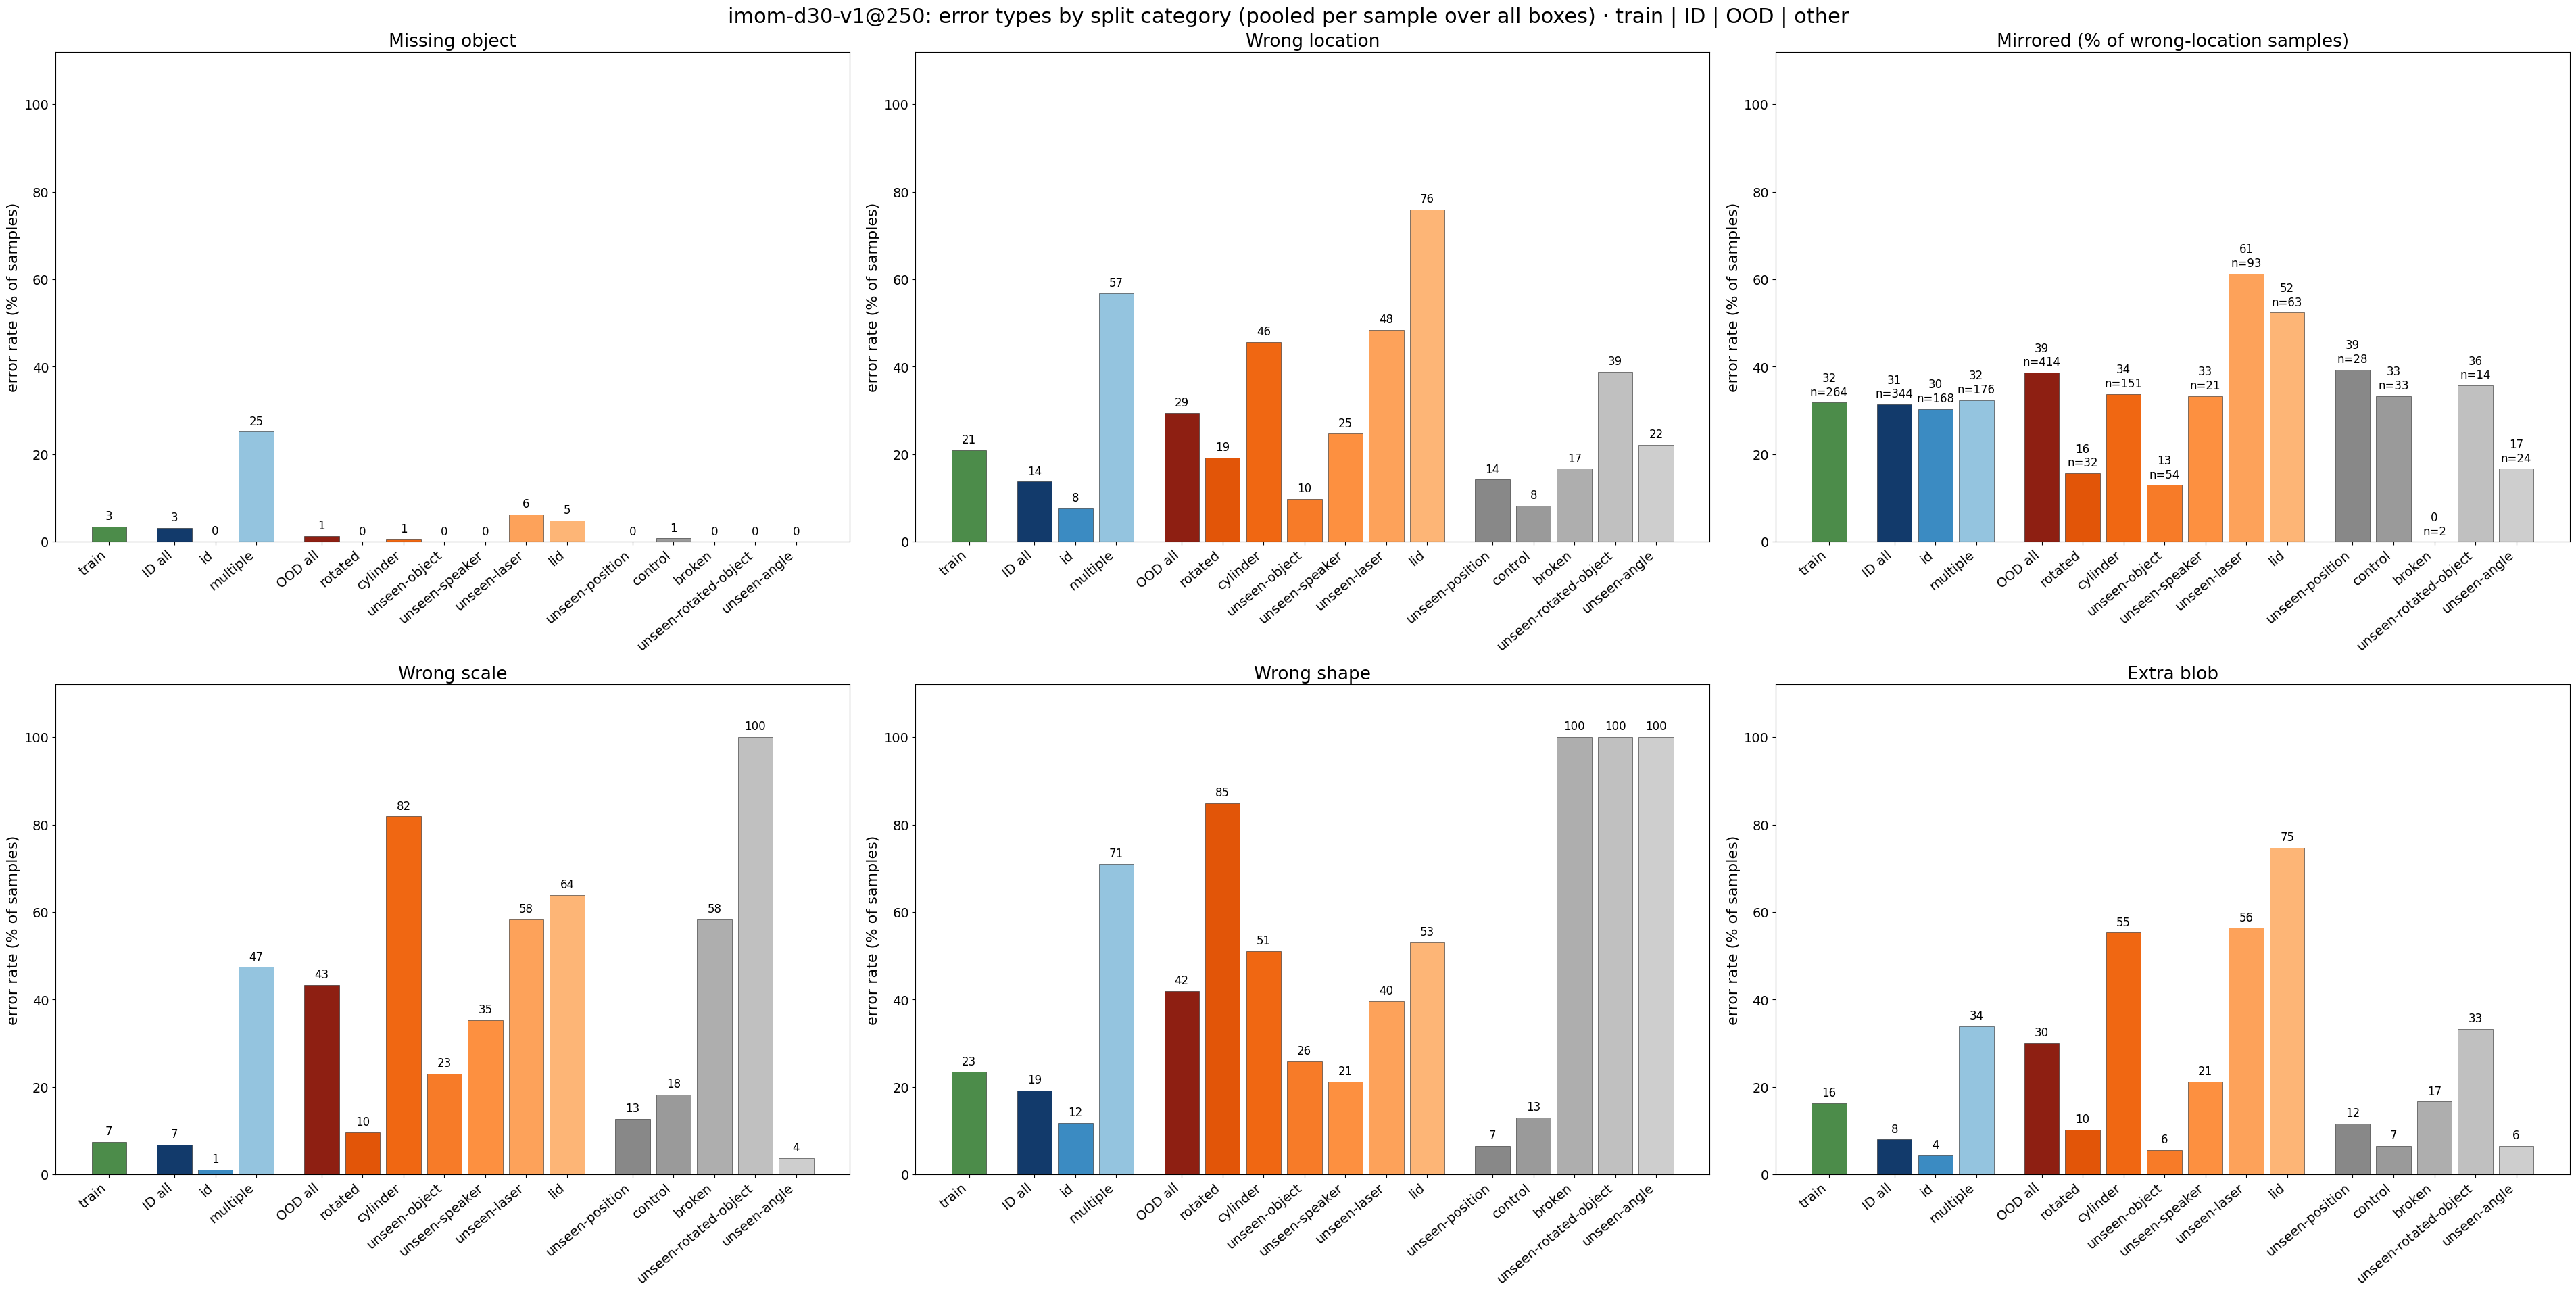

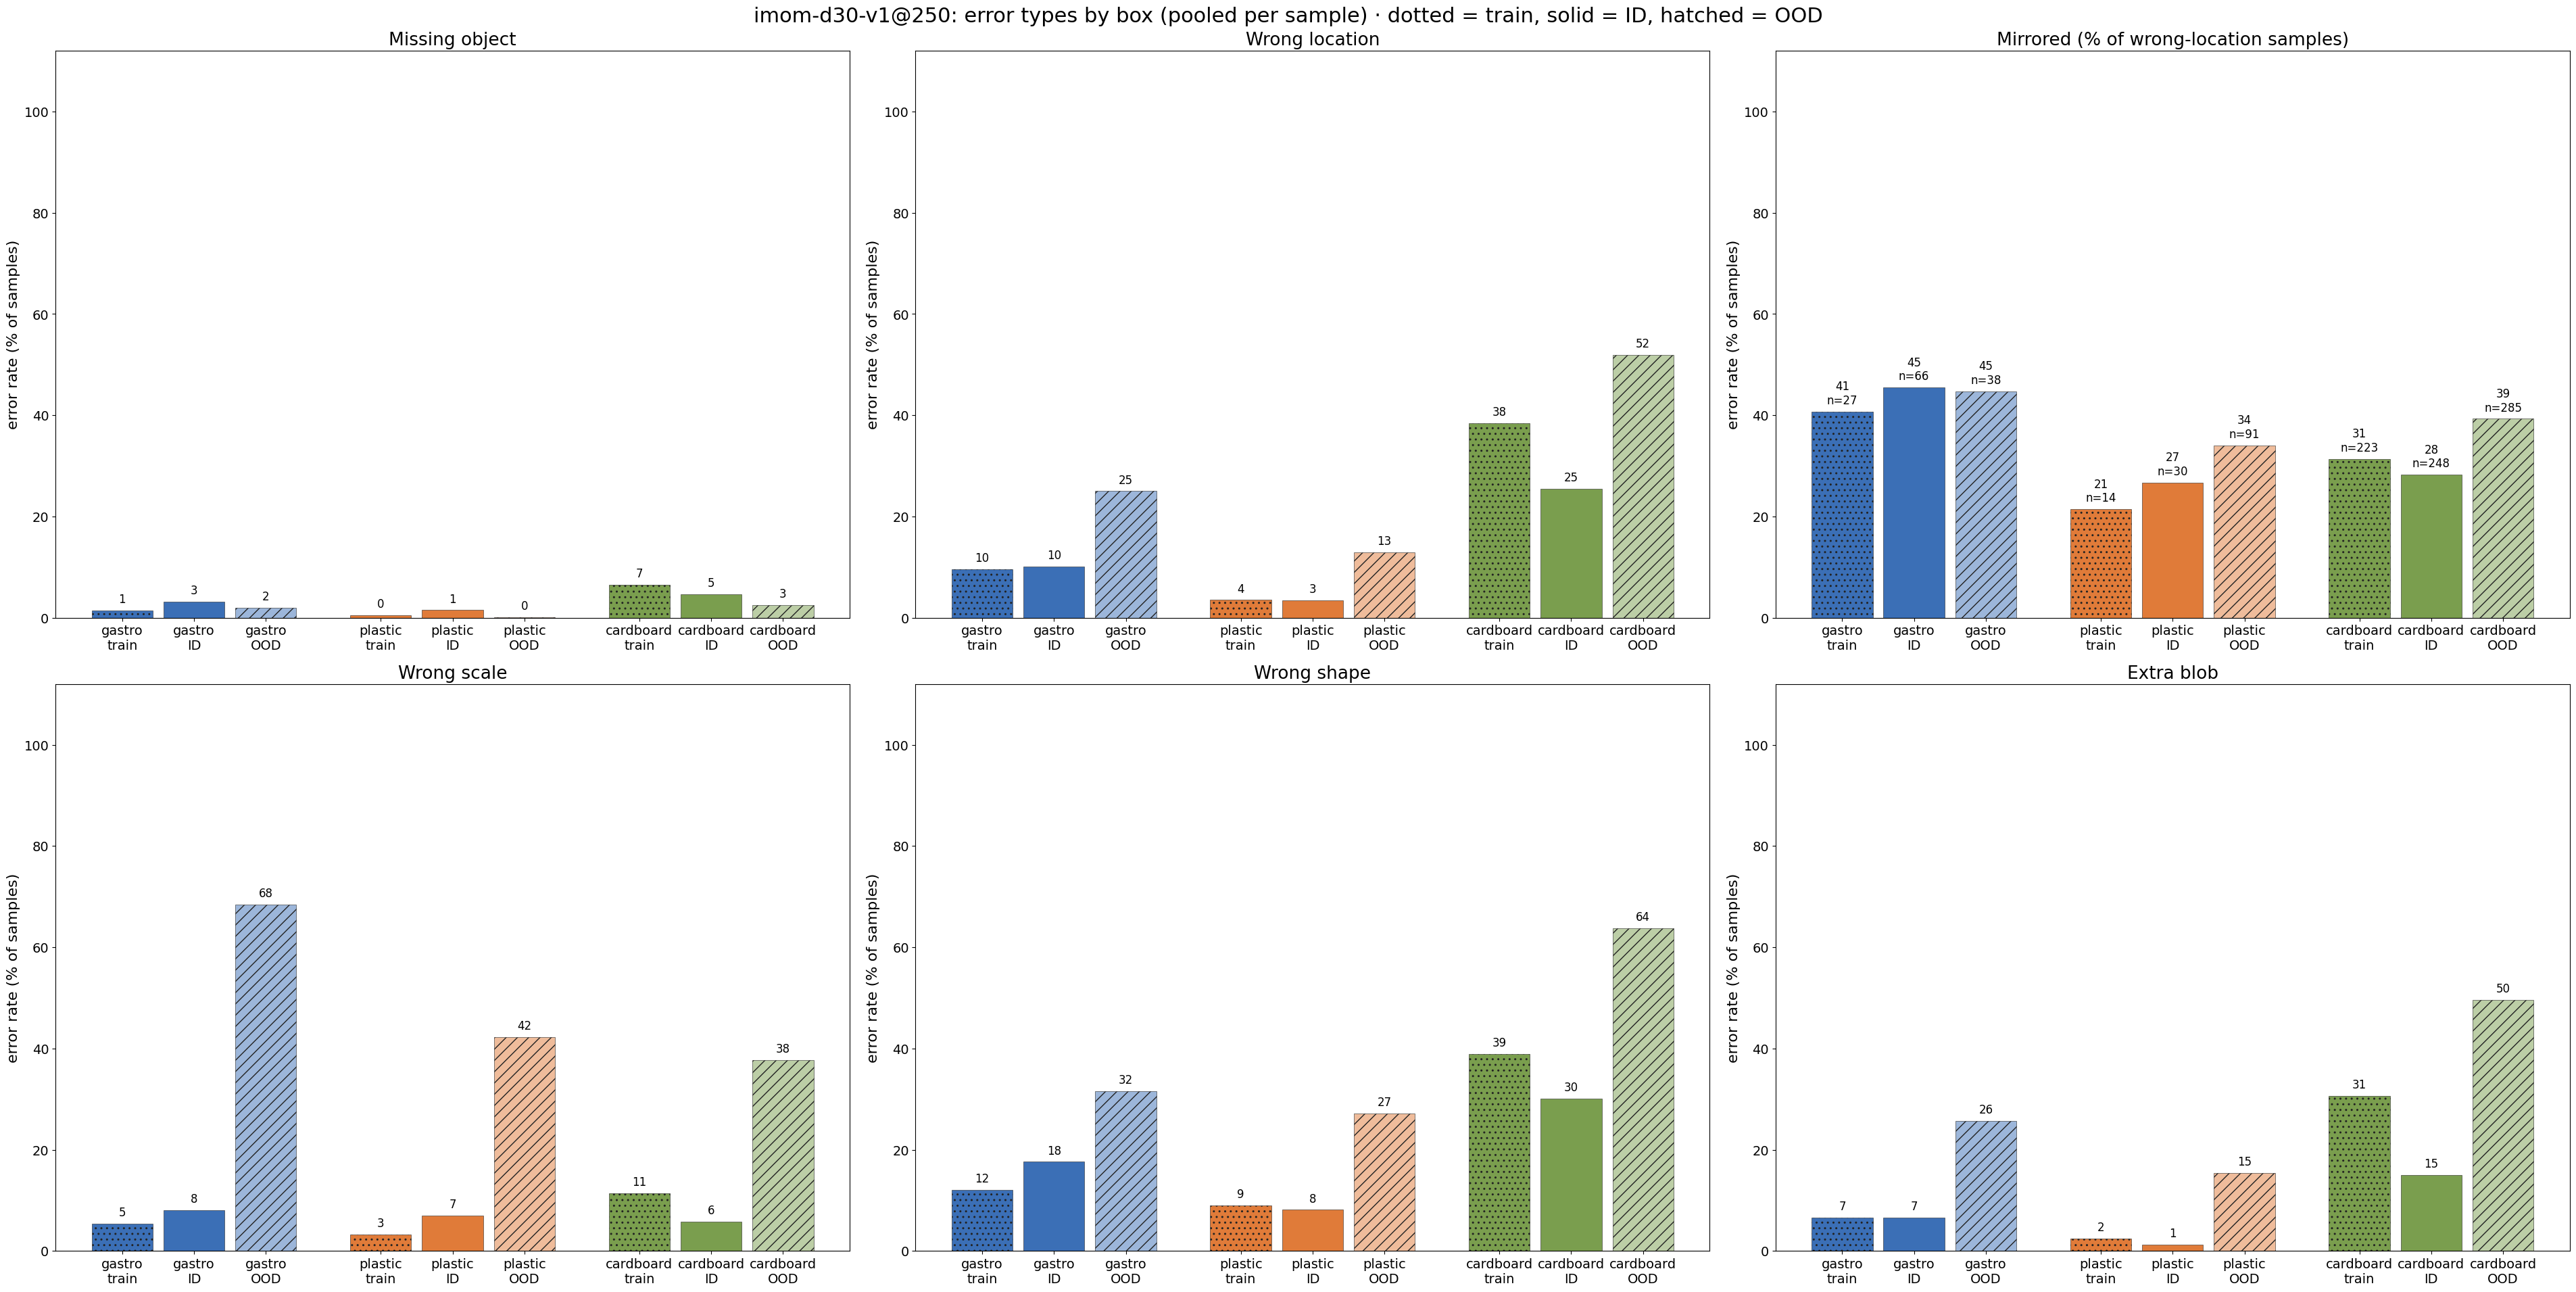

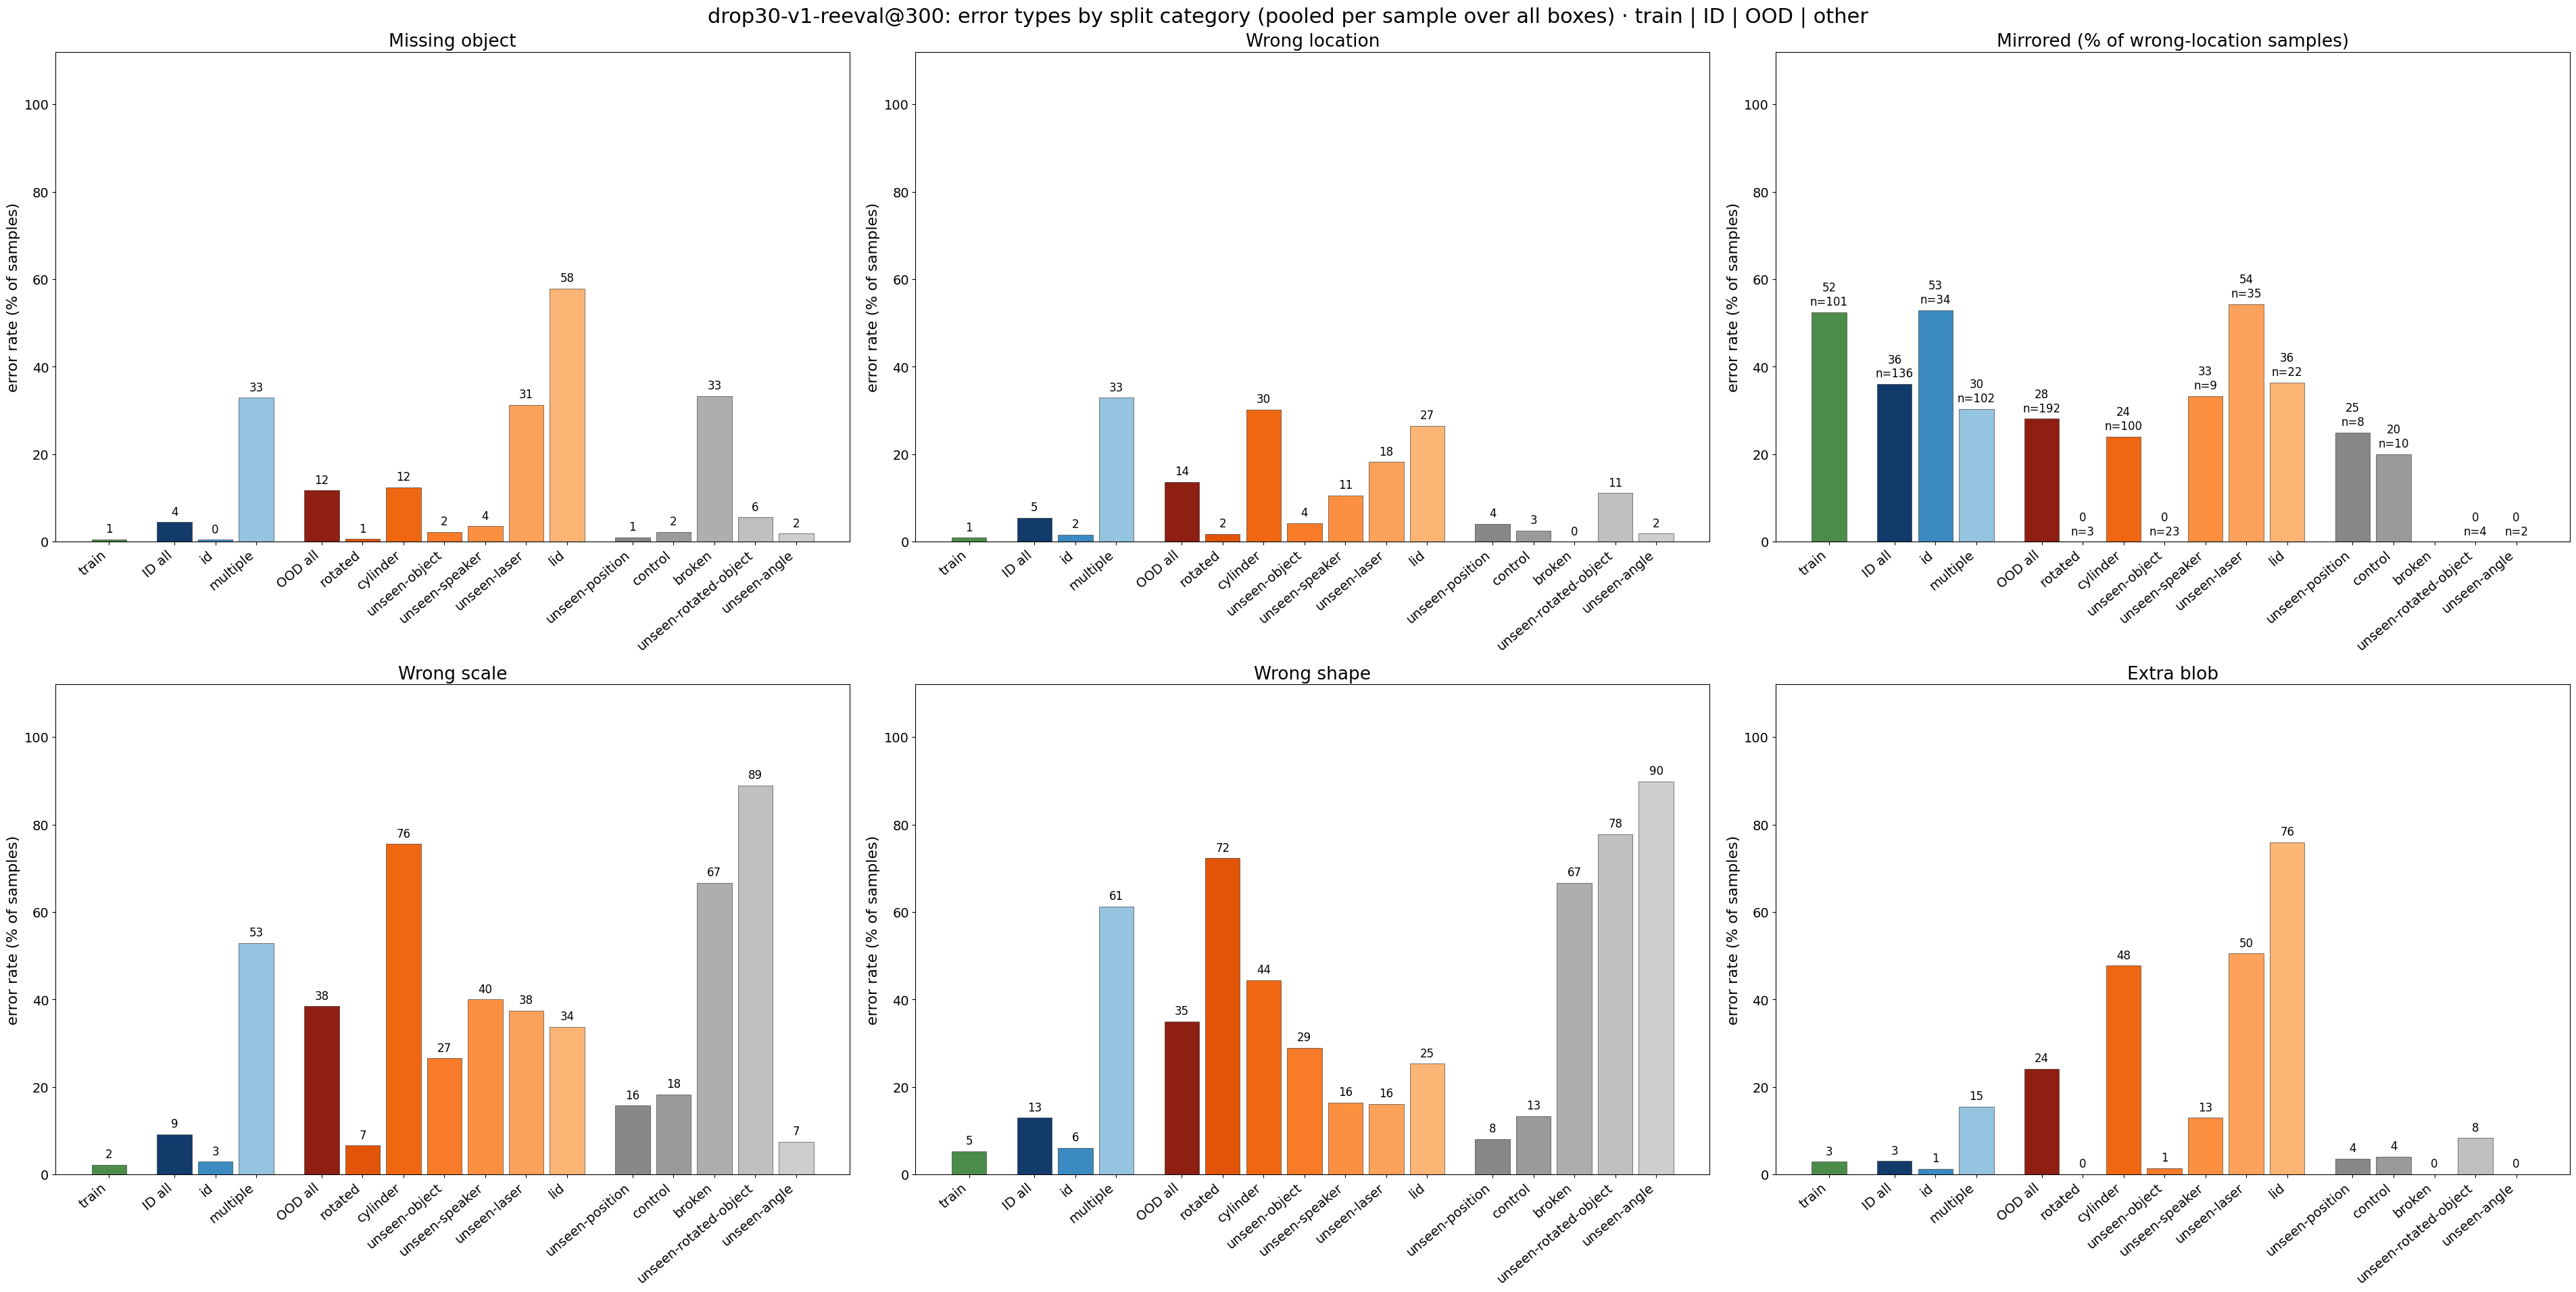

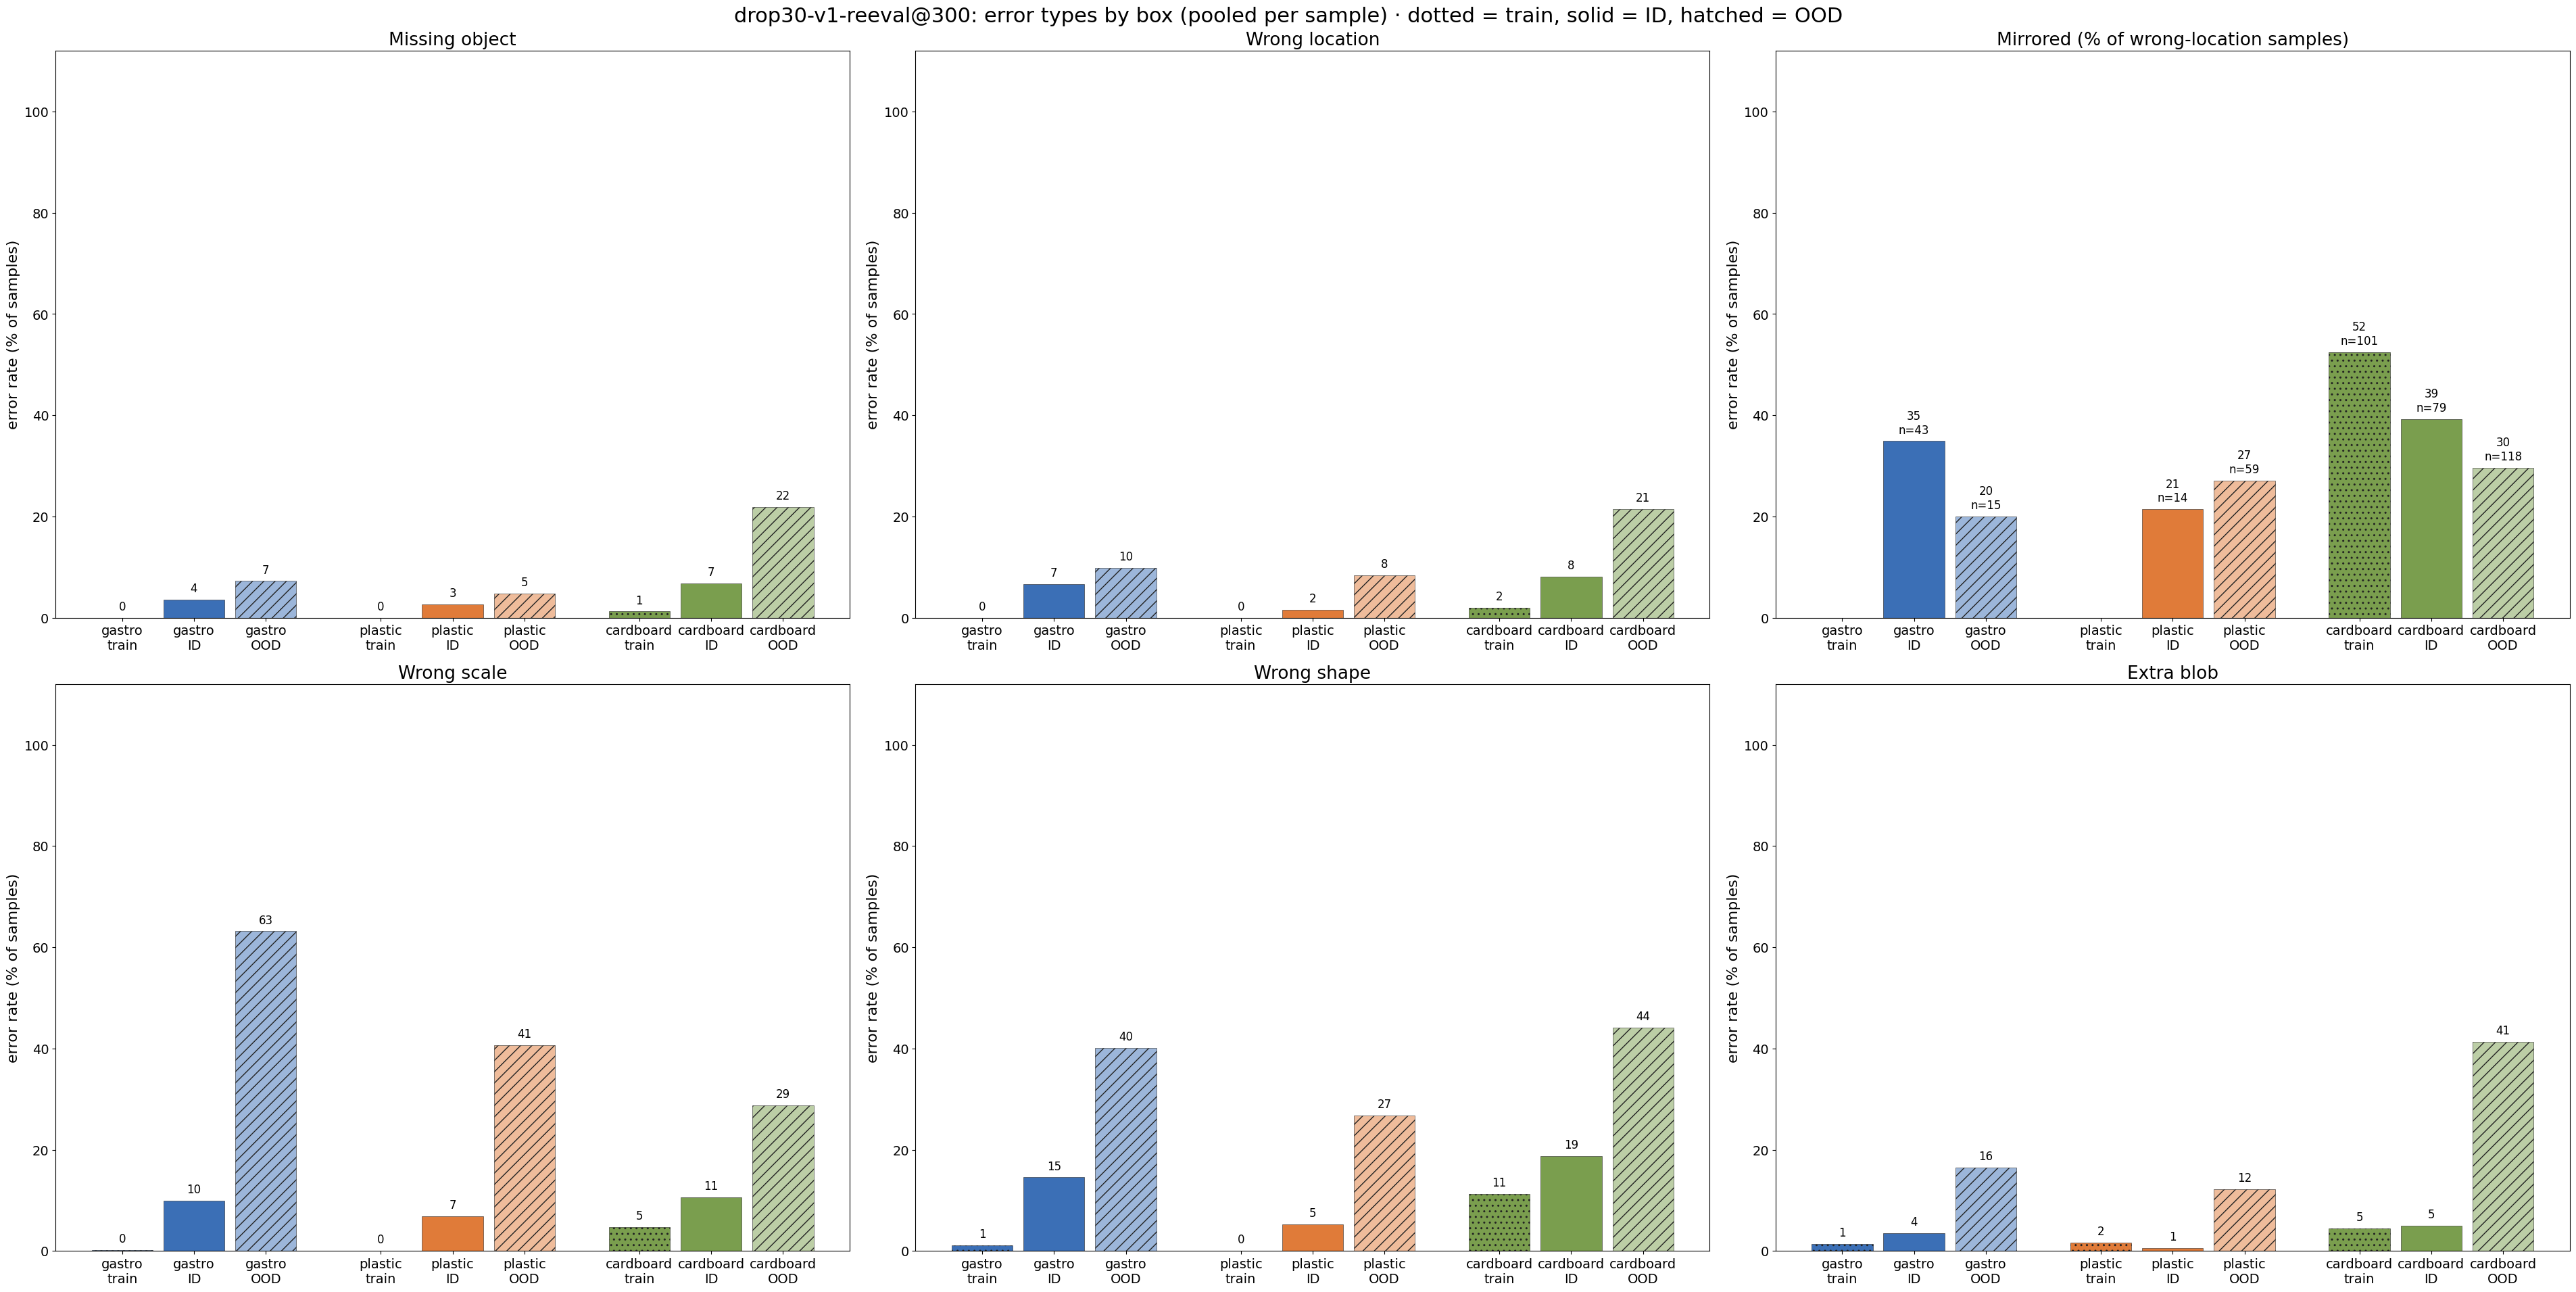

In [6]:
for run in (IMOM, BASE):   # the main pair
    s = DS[run]
    grid(f"{LABEL[run]}: error types by split category (pooled per sample over all boxes) · train | ID | OOD | other", split_groups(s), rot=40)

    groups = [[(f"{b}\n{g}", cat(s[s.box == b], cs), BOX_COLOR[b] + a, h) for g, cs, a, h in (("train", "train", "FF", ".."), ("ID", ID_CATS, "FF", None), ("OOD", OOD_CATS, "80", "//"))]
              for b in BOXES]
    grid(f"{LABEL[run]}: error types by box (pooled per sample) · dotted = train, solid = ID, hatched = OOD", groups)

Per run: first grid = each category pooled per sample over all boxes (train = the saved train-set eval; other = neither ID nor OOD, e.g. unseen-position); second grid = train / ID / OOD per box. Missing object and Mirrored are always rates.

## A · primary error (exclusive)

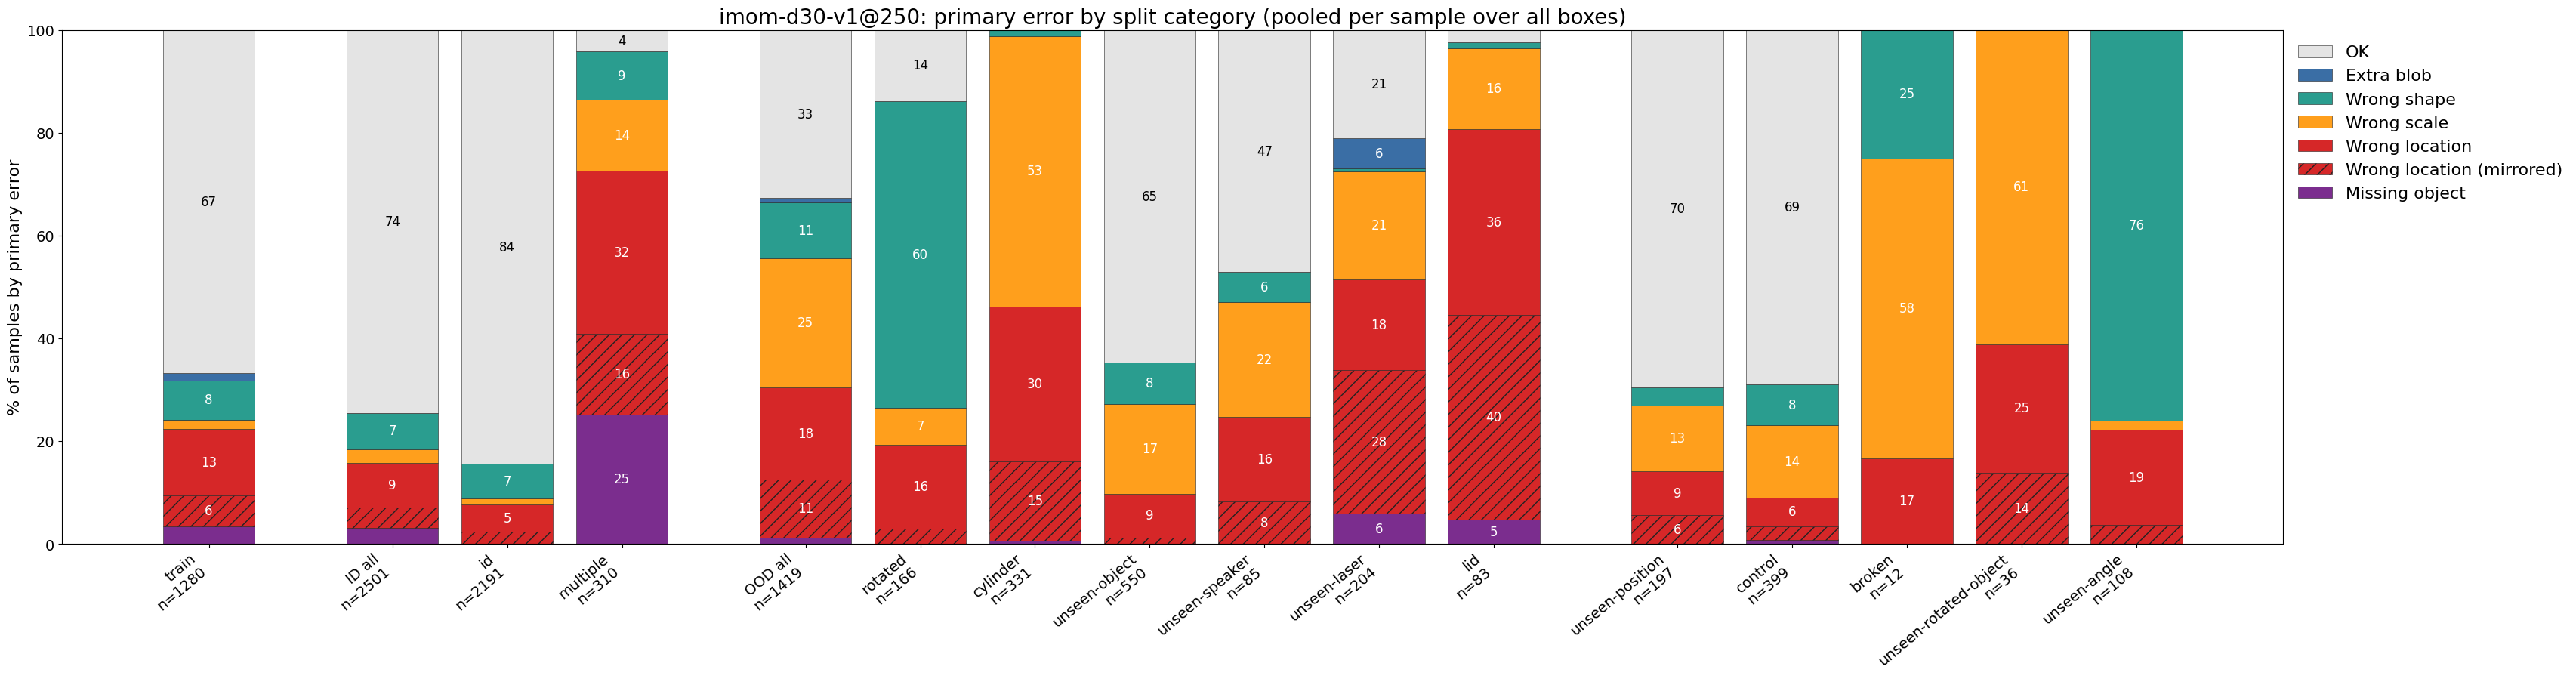

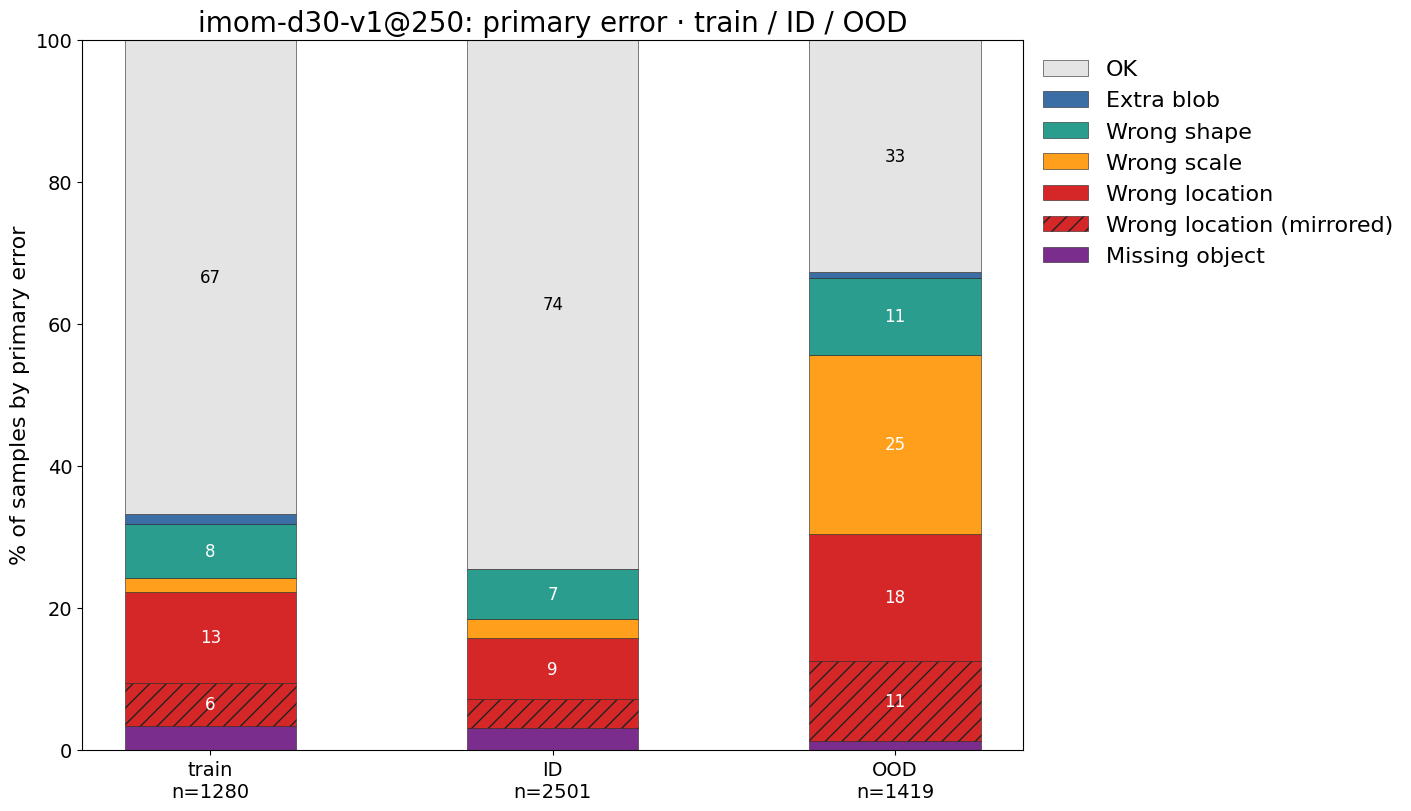

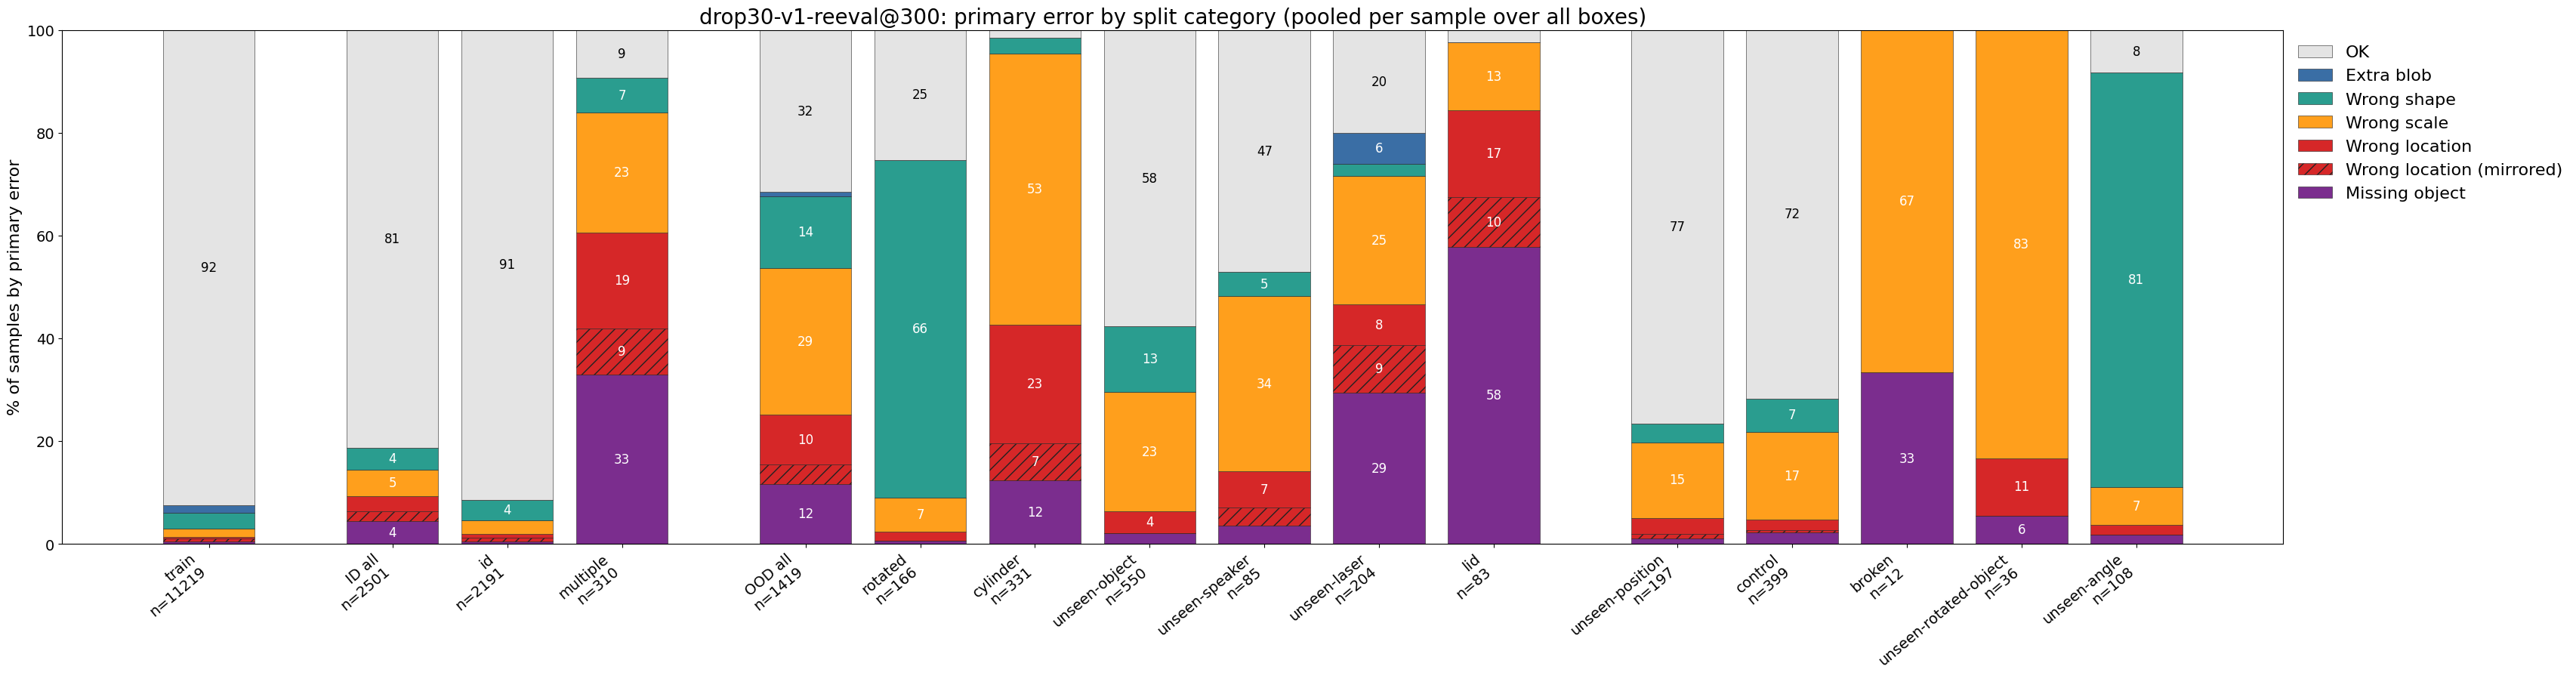

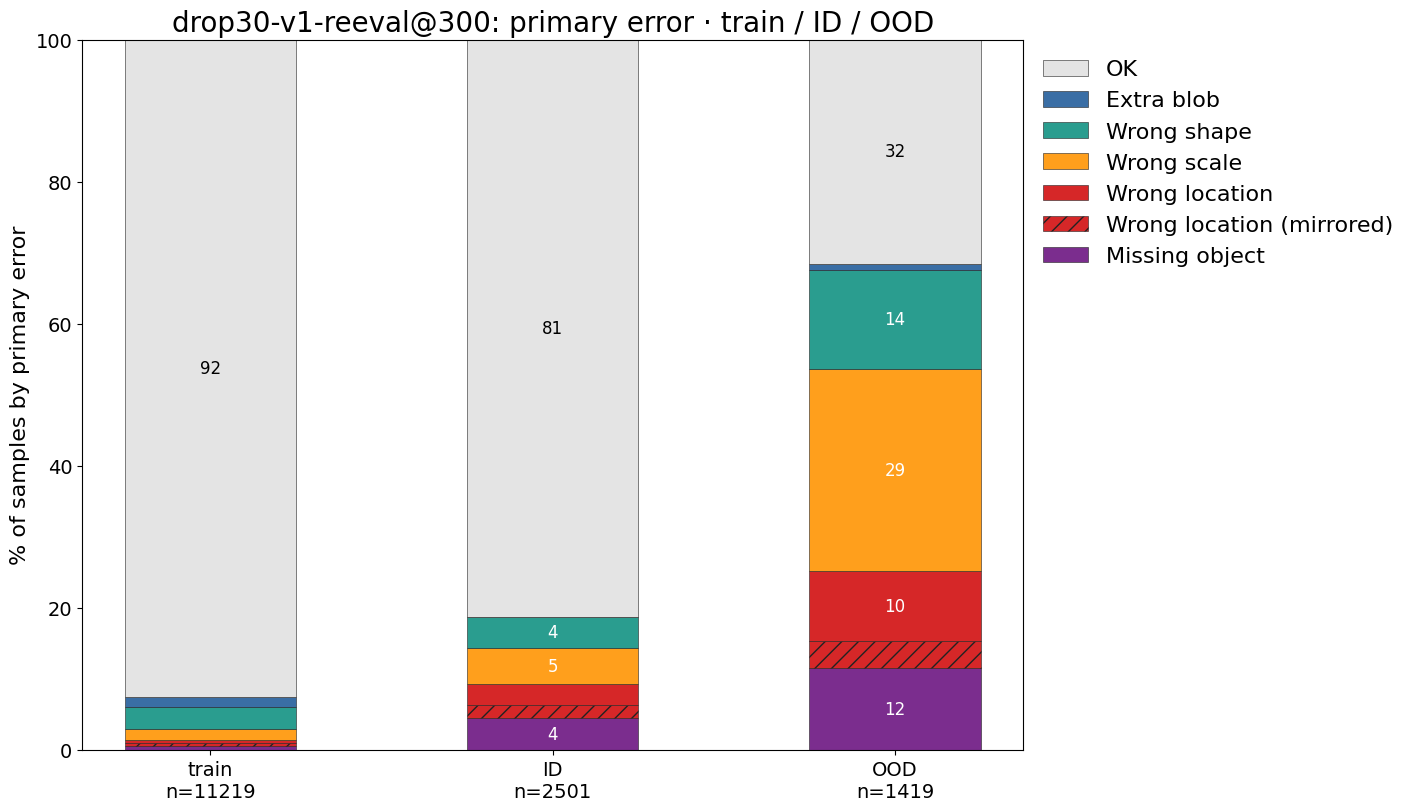

In [7]:
# primary error per sample: first flag in priority order (missing > location > scale > shape > extra > OK); location split into mirrored / not
PRIMARY = [("Missing object", "#7B2D8E", None), ("Wrong location (mirrored)", "#D62728", "//"), ("Wrong location", "#D62728", None),
           ("Wrong scale", "#FF9F1C", None), ("Wrong shape", "#2A9D8F", None), ("Extra blob", "#3A6EA5", None), ("OK", "#E4E4E4", None)]

def primary(s):
    f = lambda c: s[c].fillna(0).to_numpy() > 0
    loc = f("r_loc") & ~f("missing")
    return np.select([f("missing"), loc & f("mirrored"), loc, f("r_scale"), f("r_shape"), f("r_extra")], range(6), 6)

def stacked(title, bars, figsize, rot=0):
    """bars = [[(label, samples), ...], ...] groups; each bar = 100% of its samples split by primary error"""
    pos, flat = [], []
    for g in bars:
        x0 = (pos[-1] + 1.6) if pos else 0
        for j, b in enumerate(g): pos.append(x0 + j); flat.append(b)
    fig, ax = plt.subplots(figsize=figsize, constrained_layout=True)
    bottom = np.zeros(len(flat))
    shares = np.array([np.bincount(primary(s), minlength=7) / max(len(s), 1) * 100 for _, s in flat])  # (bars, 7)
    for j, (name, color, hatch) in enumerate(PRIMARY):
        ax.bar(pos, shares[:, j], 0.8, bottom=bottom, color=color, hatch=hatch, edgecolor="#222222", linewidth=0.4, label=name)
        for p, b, v in zip(pos, bottom, shares[:, j]):
            if v >= 4: ax.text(p, b + v / 2, f"{v:.0f}", ha="center", va="center", fontsize=12, color="black" if name == "OK" else "white")
        bottom += shares[:, j]
    ax.set_xticks(pos, [f"{l}\nn={len(s)}" for l, s in flat], rotation=rot, ha="right" if rot else "center")
    ax.set_ylim(0, 100); ax.set_ylabel("% of samples by primary error"); ax.set_title(title, fontsize=20)
    h, l = ax.get_legend_handles_labels()
    ax.legend(h[::-1], l[::-1], frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
    plt.show()

for run in (IMOM, BASE):   # the main pair
    s = DS[run]
    stacked(f"{LABEL[run]}: primary error by split category (pooled per sample over all boxes)",
            [[(l, d) for l, d, _, _ in g] for g in split_groups(s)], (34, 9), rot=40)
    stacked(f"{LABEL[run]}: primary error · train / ID / OOD", [[("train", cat(s, "train"))], [("ID", cat(s, ID_CATS))], [("OOD", cat(s, OOD_CATS))]], (14, 8))

Each sample counted once by its first error in priority order Missing object > Wrong location (hatched = mirrored) > Wrong scale > Wrong shape > Extra blob > OK.

## B · runs compared

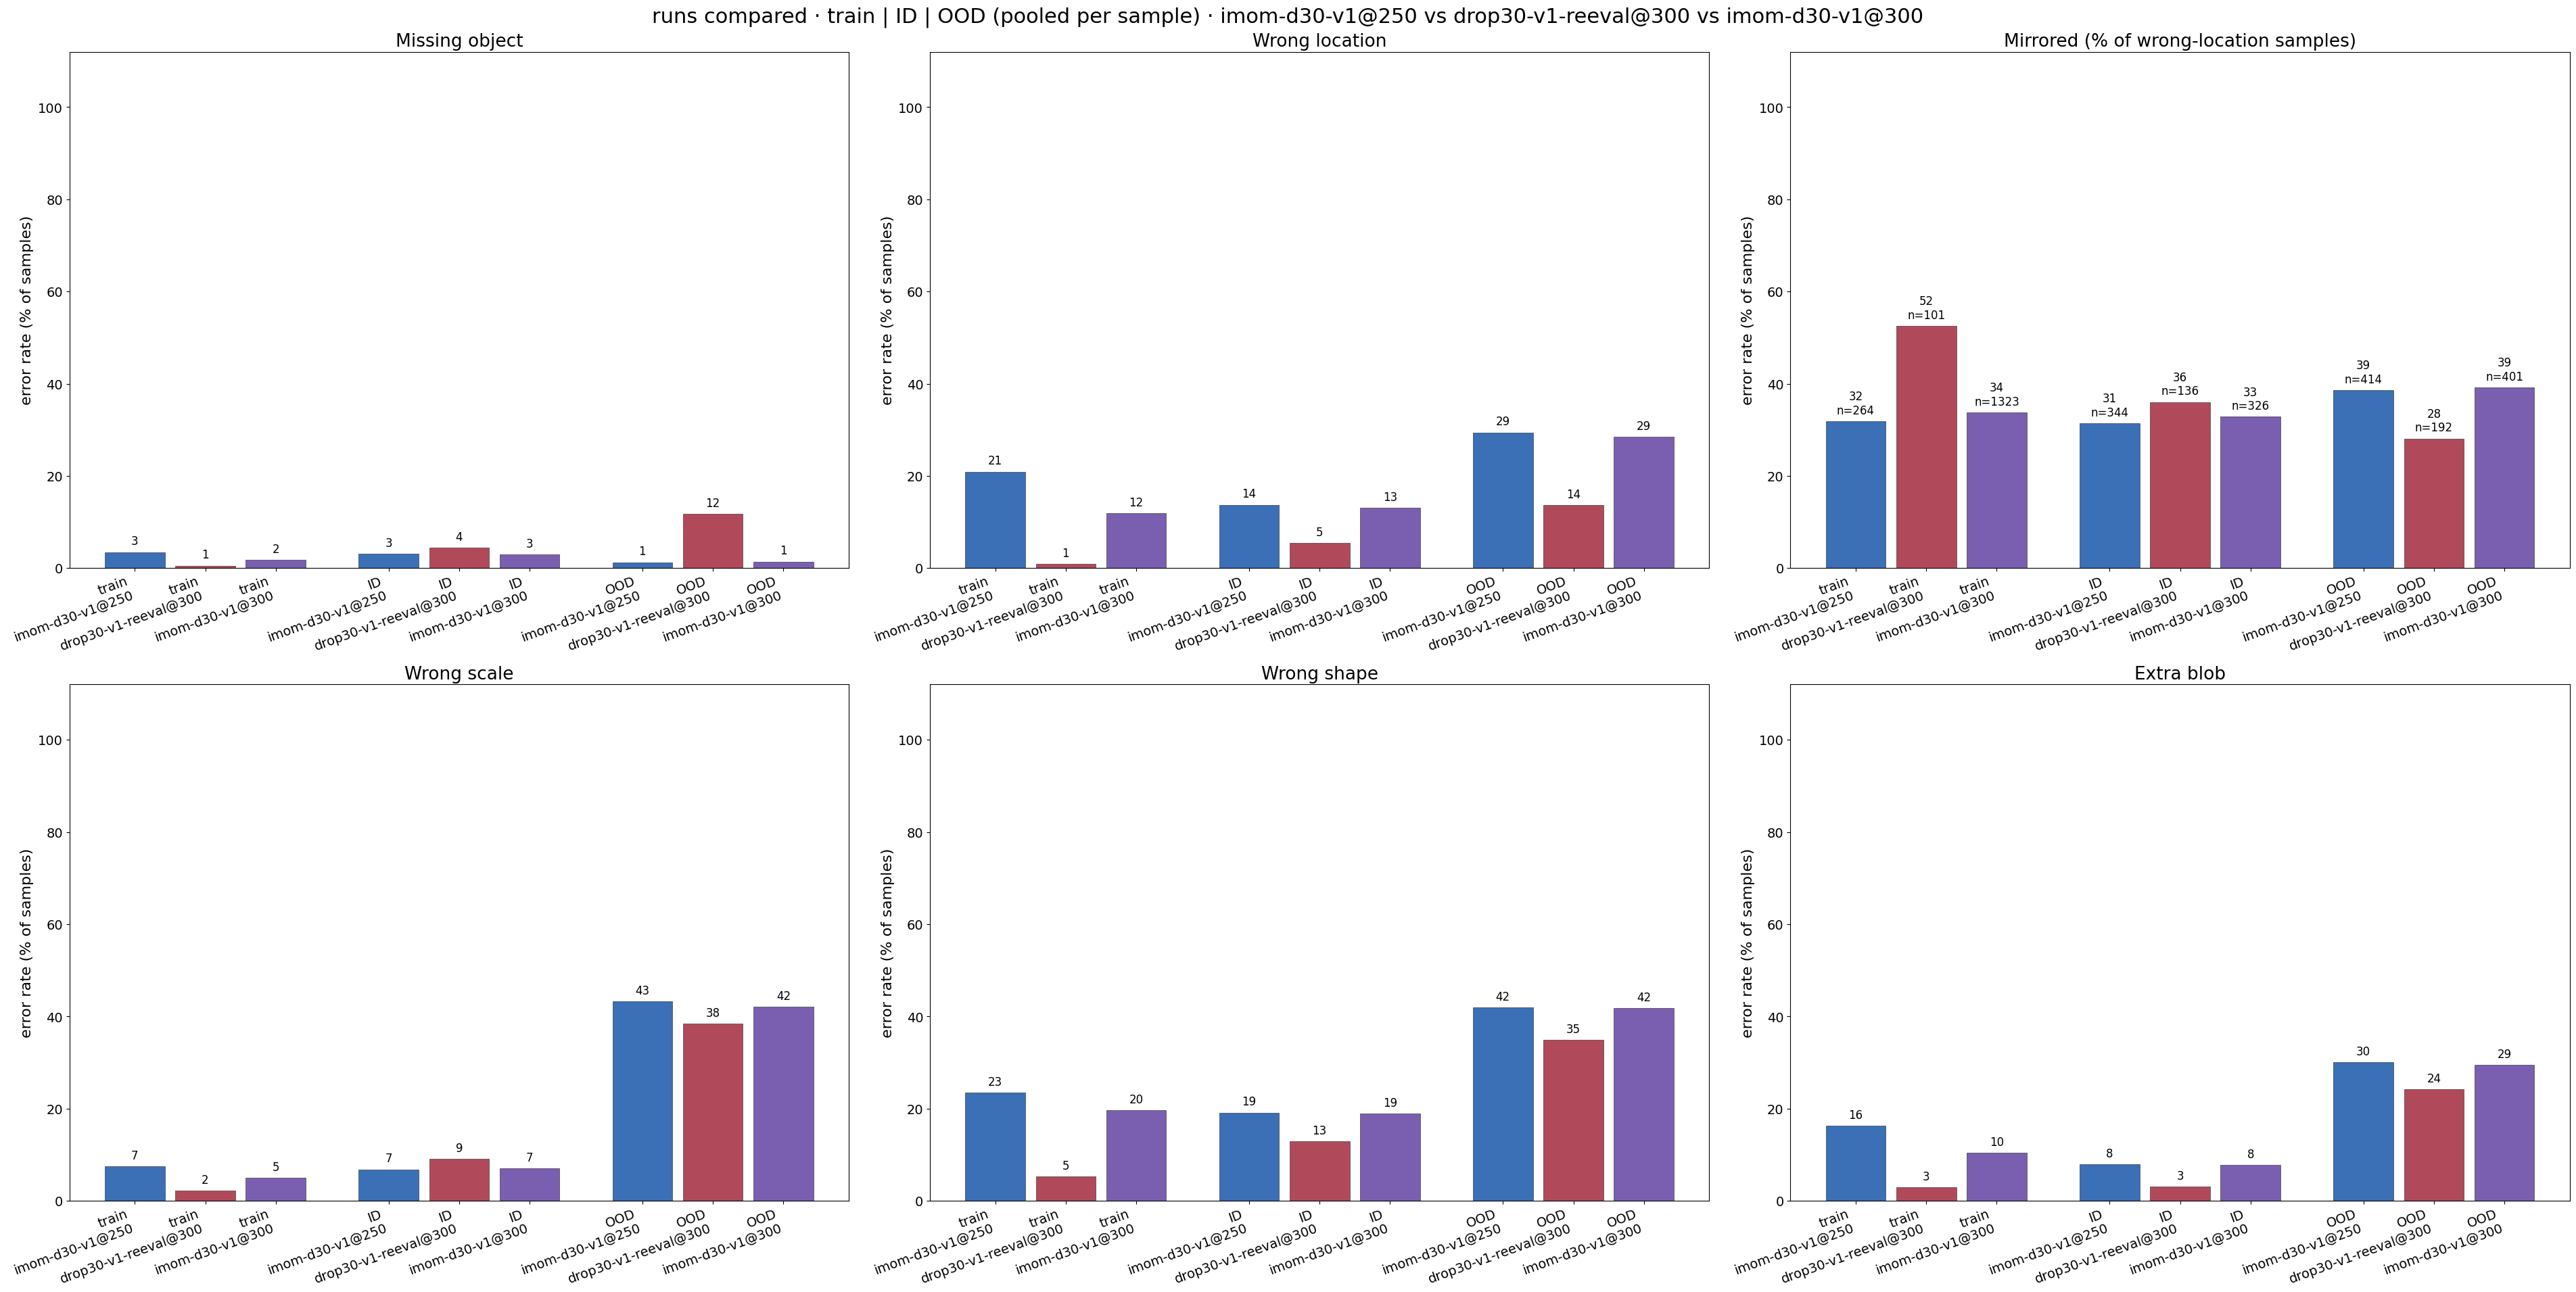

In [8]:
groups = [[(f"{g}\n{LABEL[r]}", cat(DS[r], cs), RUN_COLOR[i % len(RUN_COLOR)], None) for i, r in enumerate(RUNS)]
          for g, cs in (("train", "train"), ("ID", ID_CATS), ("OOD", OOD_CATS))]
grid("runs compared · train | ID | OOD (pooled per sample) · " + " vs ".join(LABEL[r] for r in RUNS), groups, rot=20)

One bar per run inside each of train / ID / OOD.

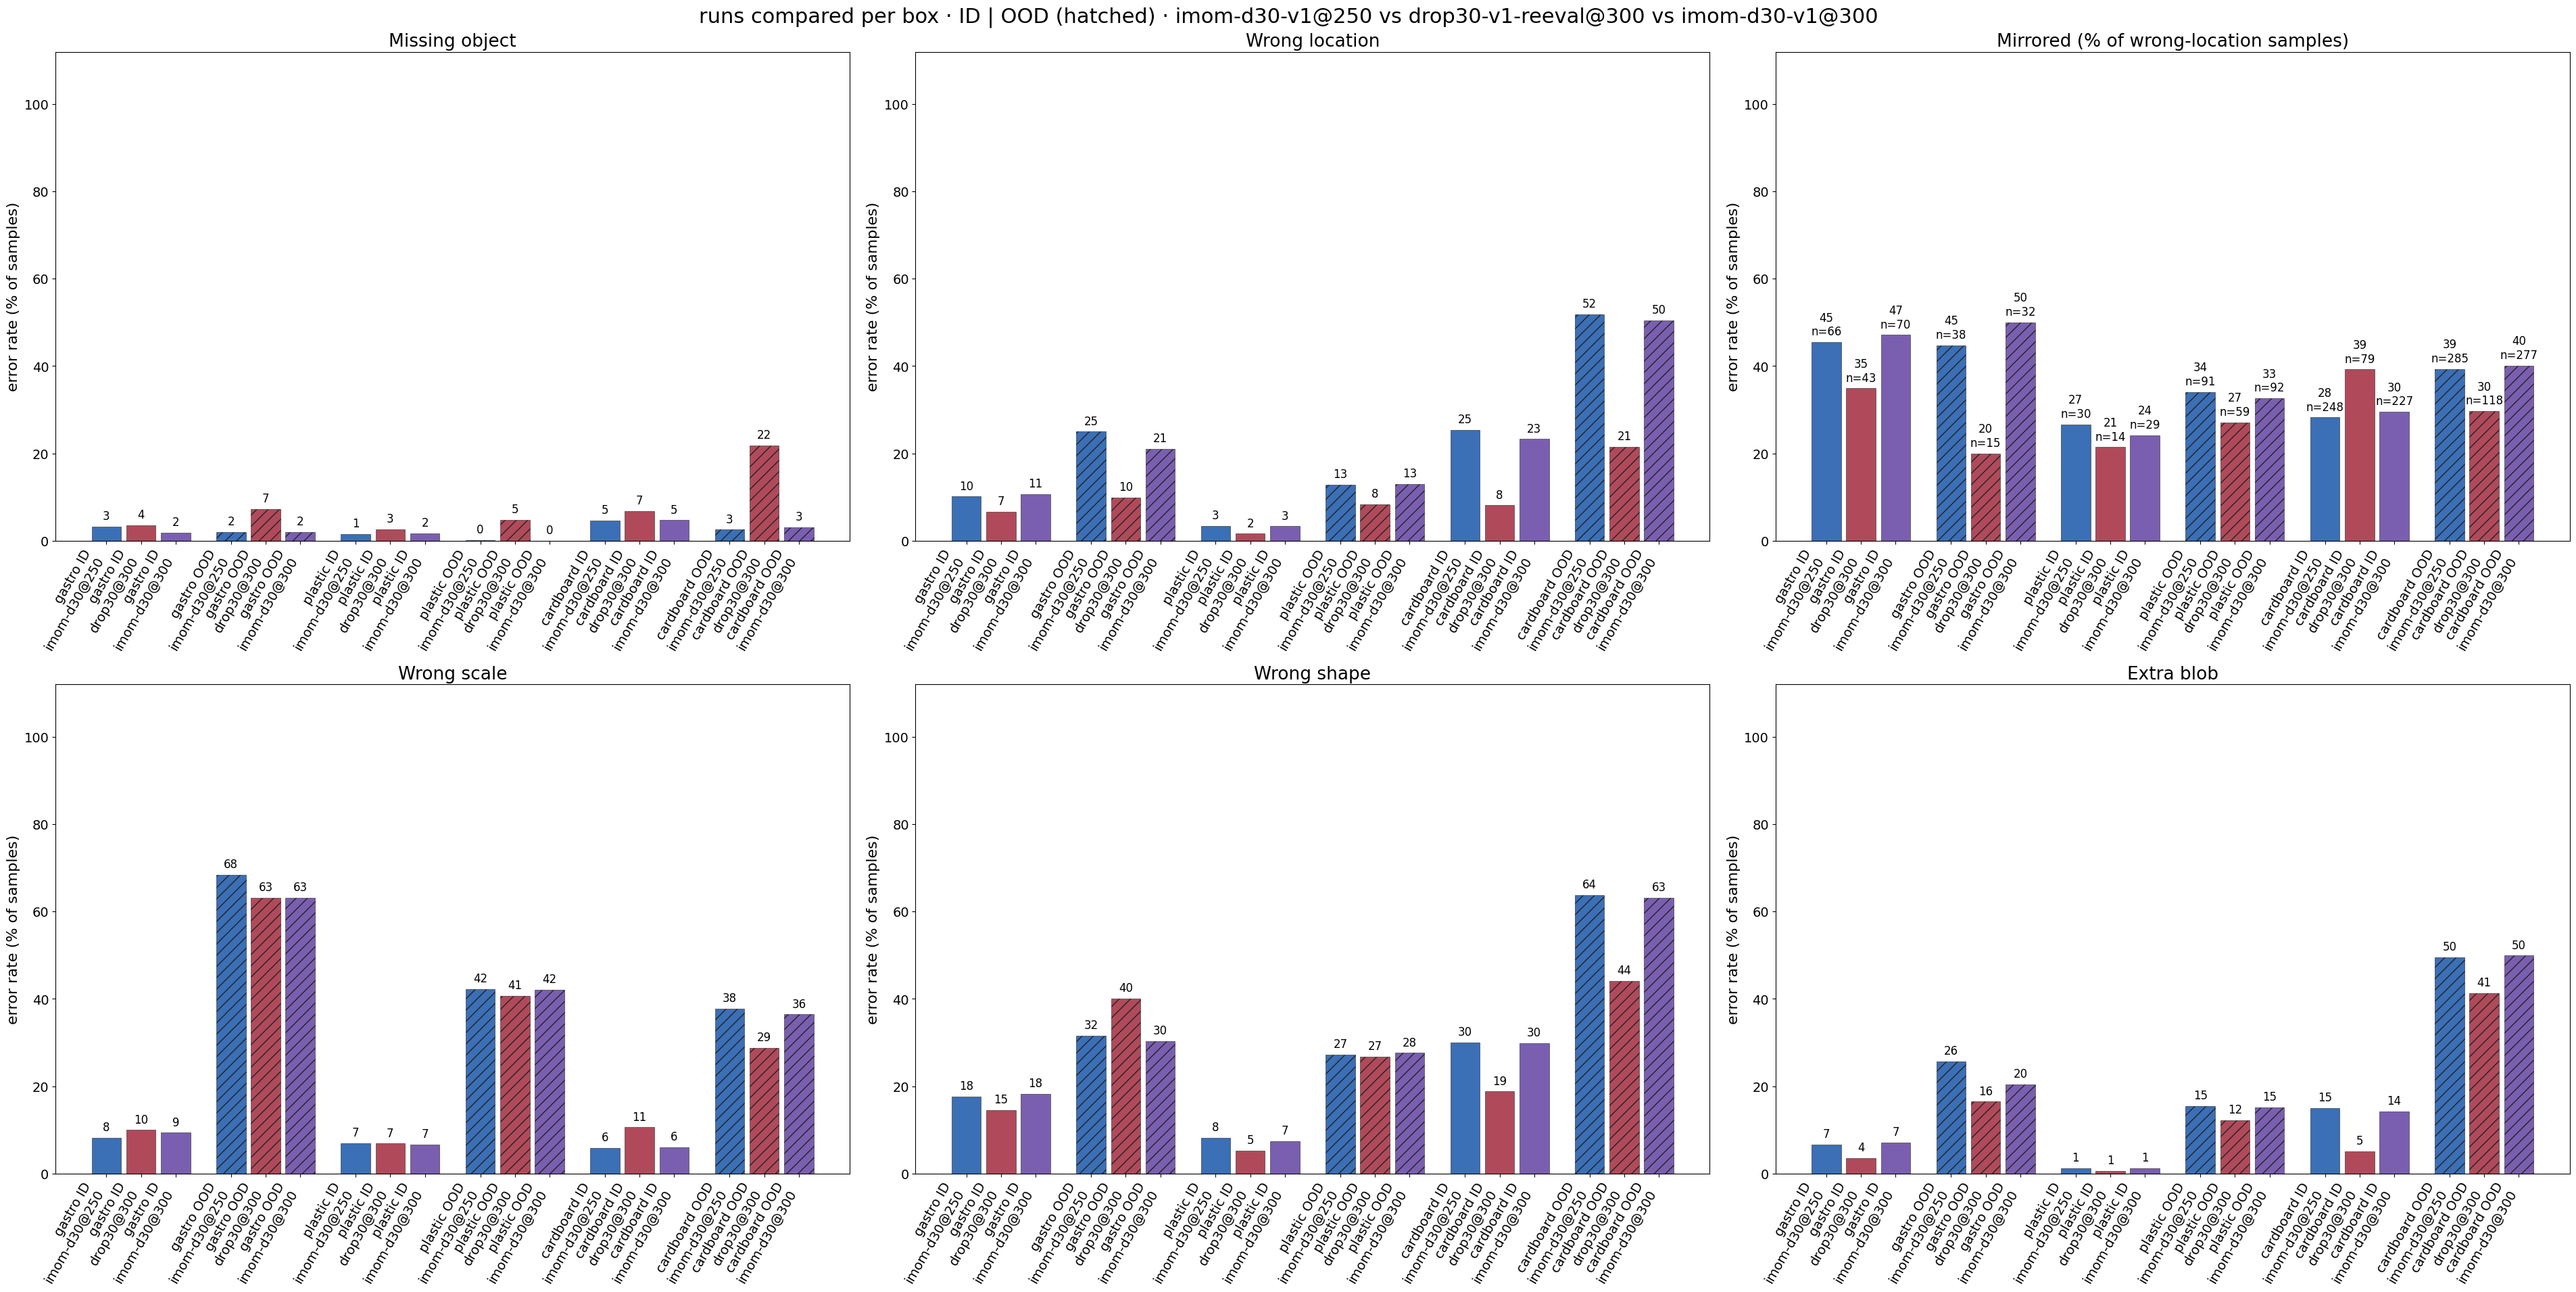

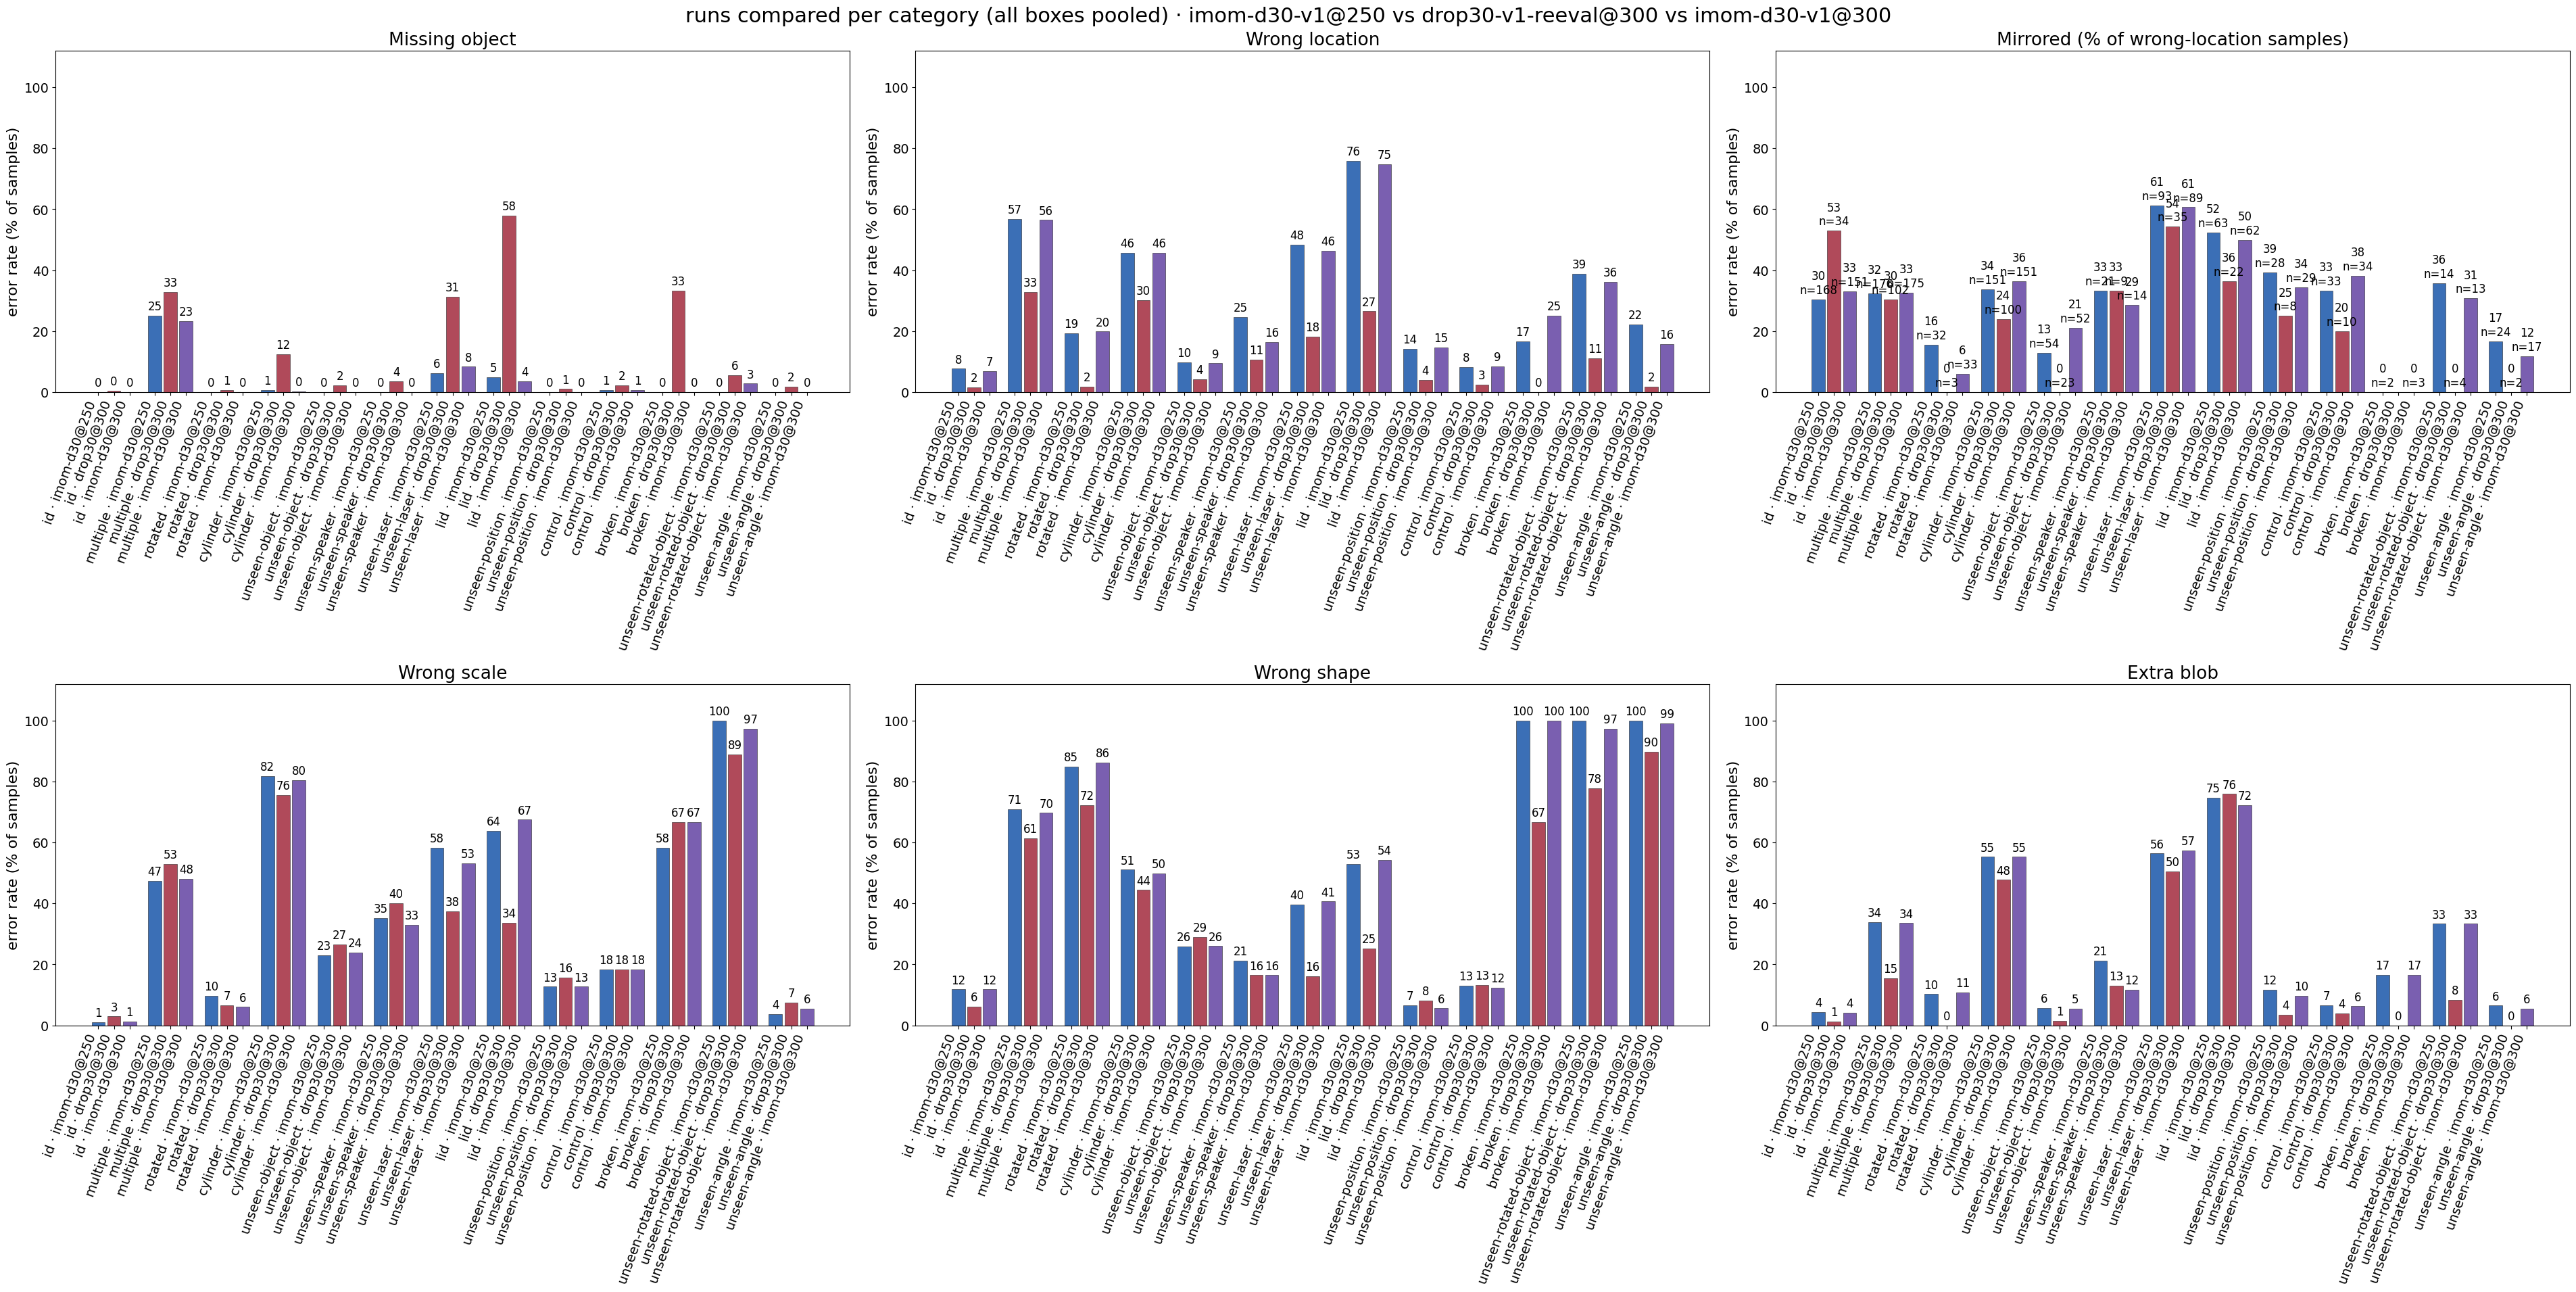

In [9]:
short = lambda r: r.replace("-v1-reeval", "").replace("-v1", "")
groups = [[(f"{b} {g}\n{short(r)}", cat(DS[r][DS[r].box == b], cs), RUN_COLOR[i], None if g == "ID" else "//") for i, r in enumerate(RUNS)]
          for b in BOXES for g, cs in (("ID", ID_CATS), ("OOD", OOD_CATS))]
grid("runs compared per box · ID | OOD (hatched) · " + " vs ".join(RUNS), groups, rot=60)

groups = [[(f"{c} · {short(r)}", cat(DS[r], c), RUN_COLOR[i], None) for i, r in enumerate(RUNS)] for c in ID_CATS + OOD_CATS + OTHER_CATS]
grid("runs compared per category (all boxes pooled) · " + " vs ".join(RUNS), groups, rot=70)

## C · where the gap is (imom − drop30, percentage points)
Each row is a sample group; `iou08` = per-sample mean iou08 (pooled), the other columns = imom's error rate minus drop30's (pp; **positive = imom worse**). The paired decomposition below splits the pooled iou08 gap by each sample's primary error under drop30 (rows) and under imom (columns).

imom-d30-v1@250 − drop30-v1-reeval@300


,n,iou08 drop30-v1-reeval@300,iou08 imom-d30-v1@250,Δ iou08,Δ Missing object pp,Δ Wrong location pp,Δ Wrong scale pp,Δ Wrong shape pp,Δ Extra blob pp,Δ mirrored pp (of wrong-loc),Δ biou
group,,,,,,,,,,,
train,1280,0.824,0.540,-0.284,2.934,20.005,5.258,18.115,13.431,-20.657,-0.332
ID,2501,0.671,0.587,-0.084,-1.319,8.317,-2.279,6.198,4.918,-4.634,-0.099
OOD,1419,0.385,0.351,-0.034,-10.448,15.778,4.833,6.965,5.849,10.522,-0.029
gastro ID,653,0.671,0.601,-0.070,-0.306,3.522,-1.838,3.063,3.063,10.571,-0.090
gastro OOD,152,0.305,0.261,-0.045,-5.263,15.132,5.263,-8.553,9.211,24.737,-0.036
plastic ID,873,0.727,0.682,-0.045,-1.145,1.833,0.115,2.864,0.687,5.238,-0.058
plastic OOD,706,0.456,0.454,-0.002,-4.674,4.533,1.558,0.425,3.258,6.947,0.003
cardboard ID,975,0.622,0.494,-0.128,-2.154,17.333,-4.718,11.282,9.949,-11.015,-0.143
cardboard OOD,561,0.317,0.244,-0.072,-19.308,30.419,8.925,19.672,8.200,9.637,-0.069


imom-d30-v1@300 − drop30-v1-reeval@300


,n,iou08 imom-d30-v1@300,Δ iou08,Δ Missing object pp,Δ Wrong location pp,Δ Wrong scale pp,Δ Wrong shape pp,Δ Extra blob pp,Δ mirrored pp (of wrong-loc)
group,,,,,,,,,
train,11219,0.649,-0.175,1.285,11.059,2.842,14.271,7.568,-18.688
ID,2501,0.595,-0.077,-1.559,7.597,-1.999,6.038,4.718,-3.207
OOD,1419,0.355,-0.030,-10.306,14.854,3.696,6.823,5.285,11.027
gastro ID,653,0.611,-0.060,-1.685,4.135,-0.613,3.675,3.522,12.259
gastro OOD,152,0.275,-0.030,-5.263,11.184,0.000,-9.868,3.947,30.000
plastic ID,873,0.687,-0.040,-0.916,1.718,-0.229,2.176,0.573,2.709
plastic OOD,706,0.456,0.000,-4.816,4.674,1.416,0.850,2.975,5.490
cardboard ID,975,0.501,-0.120,-2.051,15.179,-4.513,11.077,9.231,-9.725
cardboard OOD,561,0.247,-0.069,-18.761,28.962,7.650,19.126,8.556,10.411


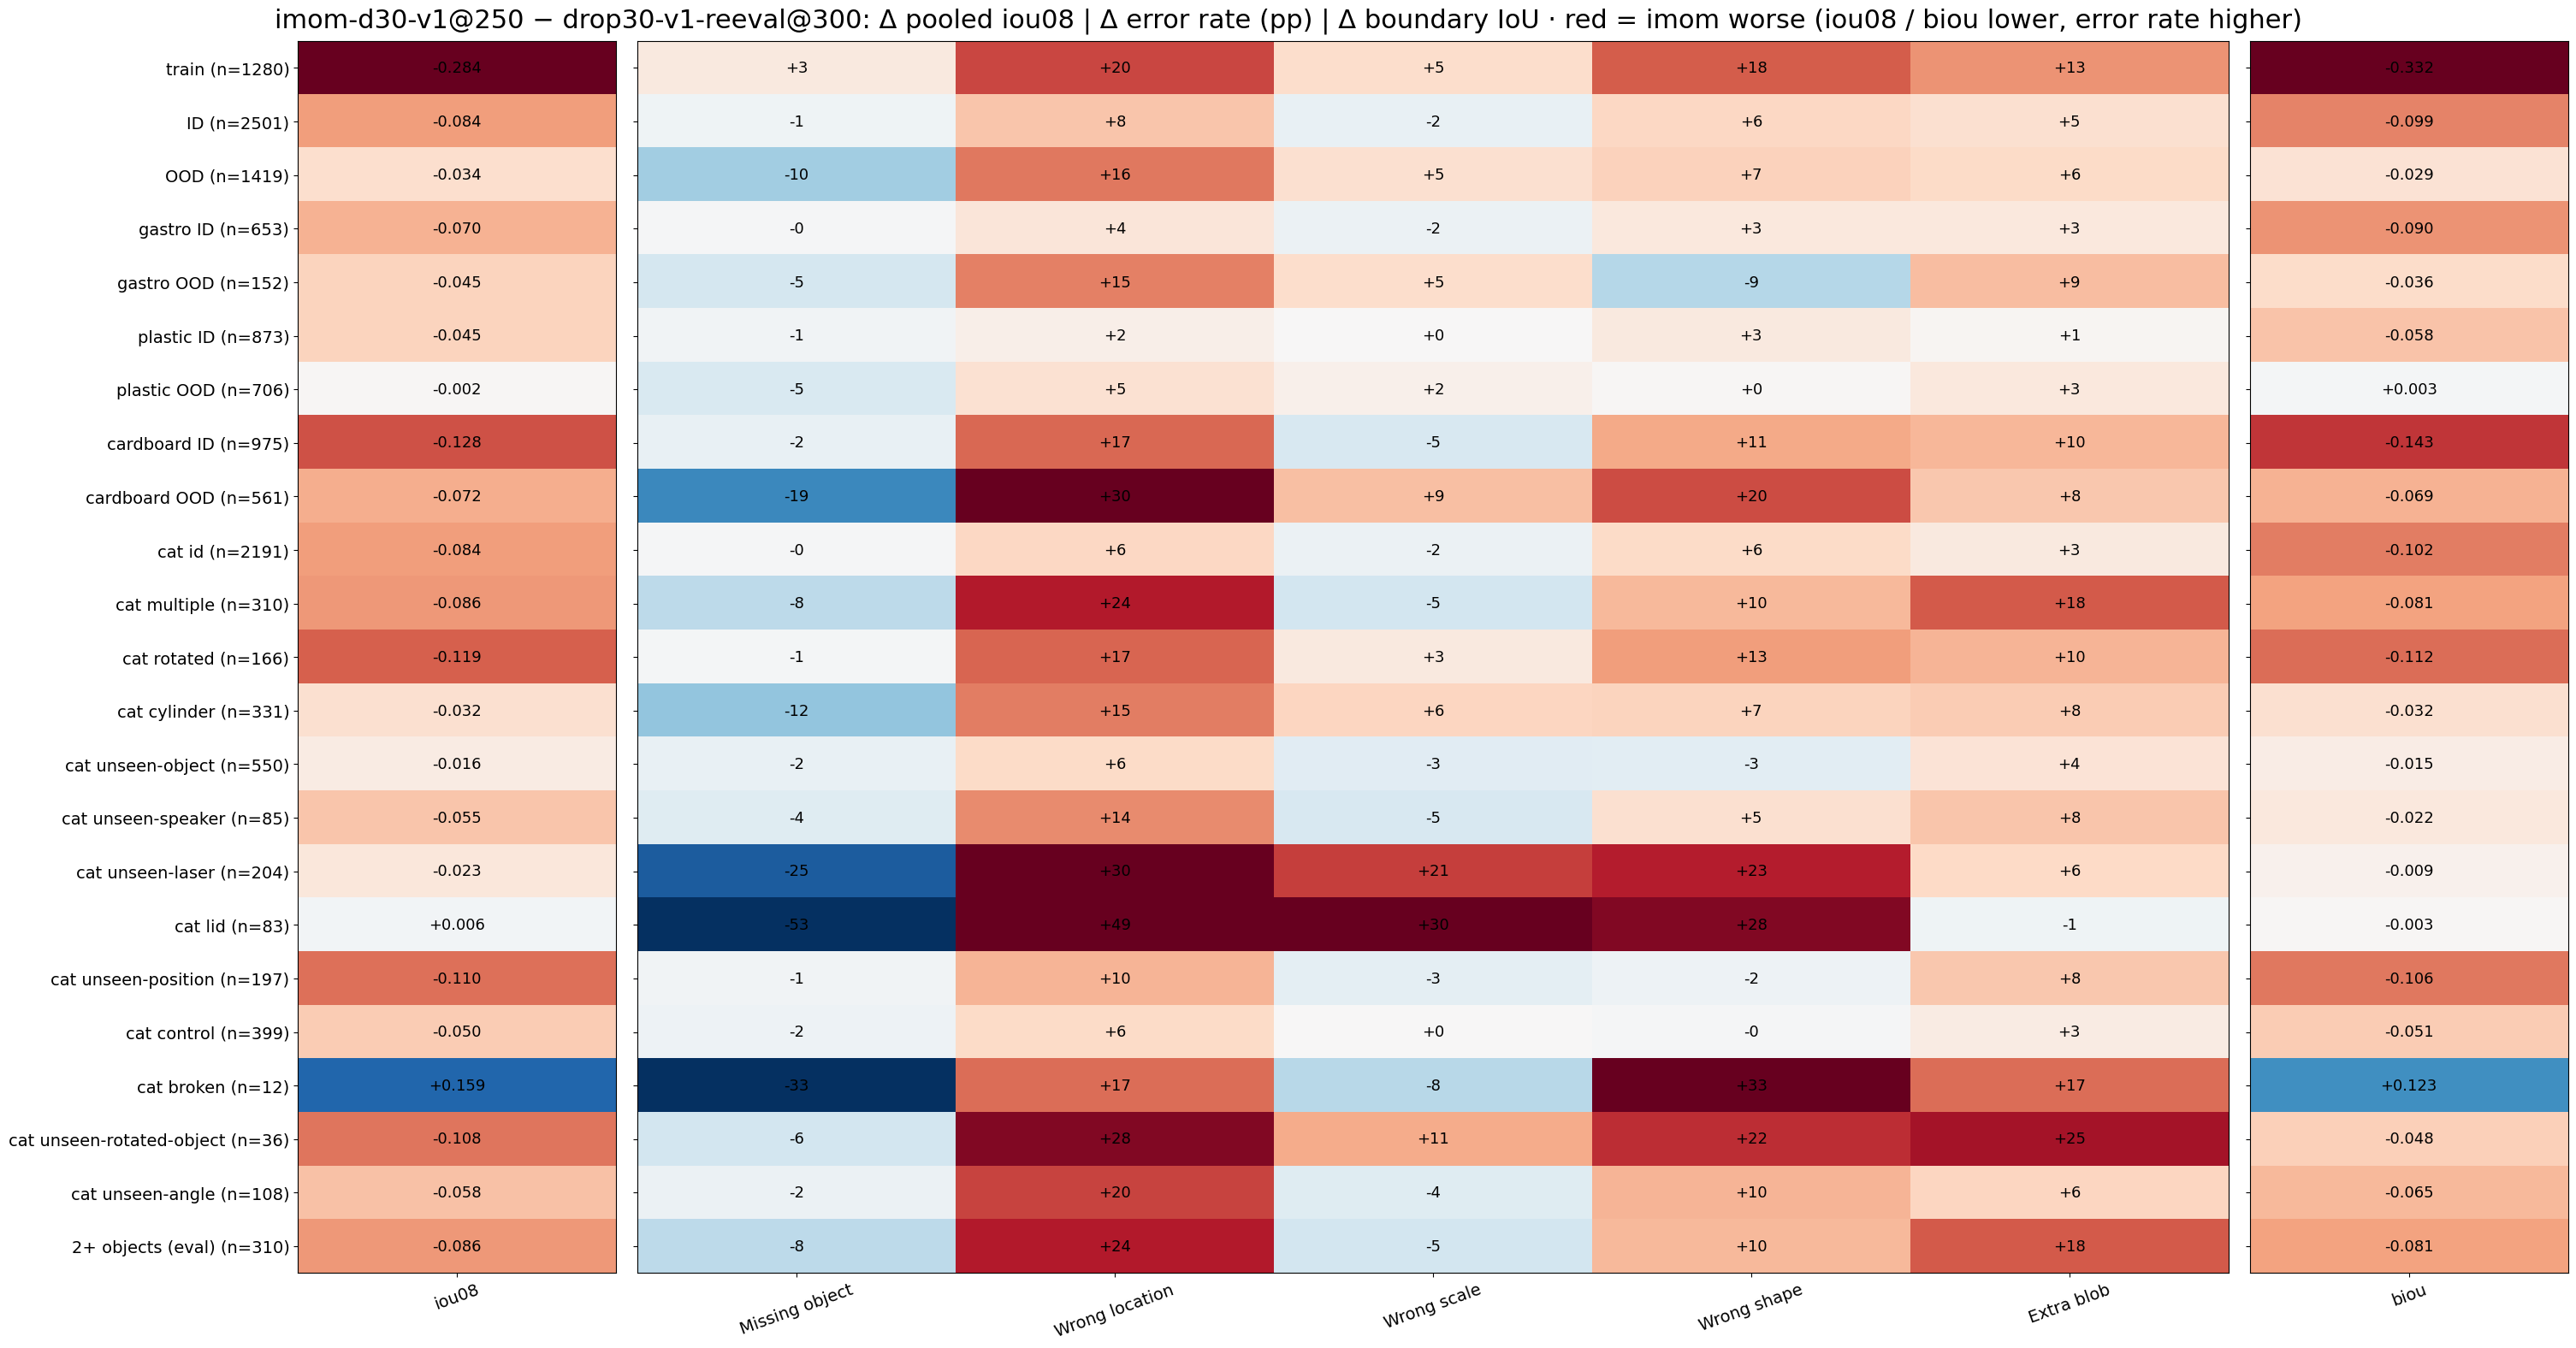

In [10]:
def groups_all():
    yield "train", lambda s: cat(s, "train")
    yield "ID", lambda s: cat(s, ID_CATS)
    yield "OOD", lambda s: cat(s, OOD_CATS)
    for b in BOXES:
        for g, cs in (("ID", ID_CATS), ("OOD", OOD_CATS)): yield f"{b} {g}", (lambda s, b=b, cs=cs: cat(s[s.box == b], cs))
    for c in ID_CATS + OOD_CATS + OTHER_CATS: yield f"cat {c}", (lambda s, c=c: cat(s, c))
    yield "2+ objects (eval)", lambda s: s[(s.n_obj >= 2) & (s.category != "train")]

def gap_table(a, b):
    rows = []
    for g, sel in groups_all():
        sa, sb = sel(DS[a]), sel(DS[b])
        r = {"group": g, "n": len(sa), f"iou08 {b}": sb.iou08.mean(), f"iou08 {a}": sa.iou08.mean(), "Δ iou08": sa.iou08.mean() - sb.iou08.mean()}
        r |= {f"Δ {n} pp": 100 * (sa[RATE[k]].mean() - sb[RATE[k]].mean()) for k, n in METRICS}
        r |= {"Δ mirrored pp (of wrong-loc)": mirrored(sa) - mirrored(sb), "Δ biou": sa.biou.mean() - sb.biou.mean()}
        rows.append(r)
    return pd.DataFrame(rows).set_index("group")

GAP = gap_table(IMOM, BASE)
GAP300 = gap_table(LABELS[2], BASE)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30); pd.set_option("display.precision", 3)
print(f"{IMOM} − {BASE}"); display(GAP.round(3))
print(f"{LABELS[2]} − {BASE}"); display(GAP300[["n", f"iou08 {LABELS[2]}", "Δ iou08"] + [c for c in GAP300 if c.startswith("Δ ") and "pp" in c]].round(3))

def gap_heat(G, title):
    cols = ["Δ iou08"] + [f"Δ {n} pp" for _, n in METRICS] + ["Δ biou"]
    M = G[cols].to_numpy(dtype=float)
    fig, axes = plt.subplots(1, 3, figsize=(30, 0.55 * len(G) + 3), gridspec_kw=dict(width_ratios=[1, 5, 1]), constrained_layout=True)
    for ax, sl, vmax, fmt in ((axes[0], [0], 0.2, "{:+.3f}"), (axes[1], list(range(1, 6)), 30, "{:+.0f}"), (axes[2], [6], 0.2, "{:+.3f}")):
        X = M[:, sl]; sgn = 1 if ax is axes[1] else -1          # red = imom worse in every panel
        ax.imshow(sgn * X, cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")
        for i in range(X.shape[0]):
            for j in range(X.shape[1]):
                if np.isfinite(X[i, j]): ax.text(j, i, fmt.format(X[i, j]), ha="center", va="center", fontsize=13)
        ax.set_xticks(range(len(sl)), [cols[k].replace("Δ ", "").replace(" pp", "") for k in sl], rotation=20)
        ax.set_yticks(range(len(G)), [f"{g} (n={n})" for g, n in zip(G.index, G.n)] if ax is axes[0] else [])
    fig.suptitle(title + " · red = imom worse (iou08 / biou lower, error rate higher)", fontsize=22)
    plt.show()

gap_heat(GAP, f"{IMOM} − {BASE}: Δ pooled iou08 | Δ error rate (pp) | Δ boundary IoU")

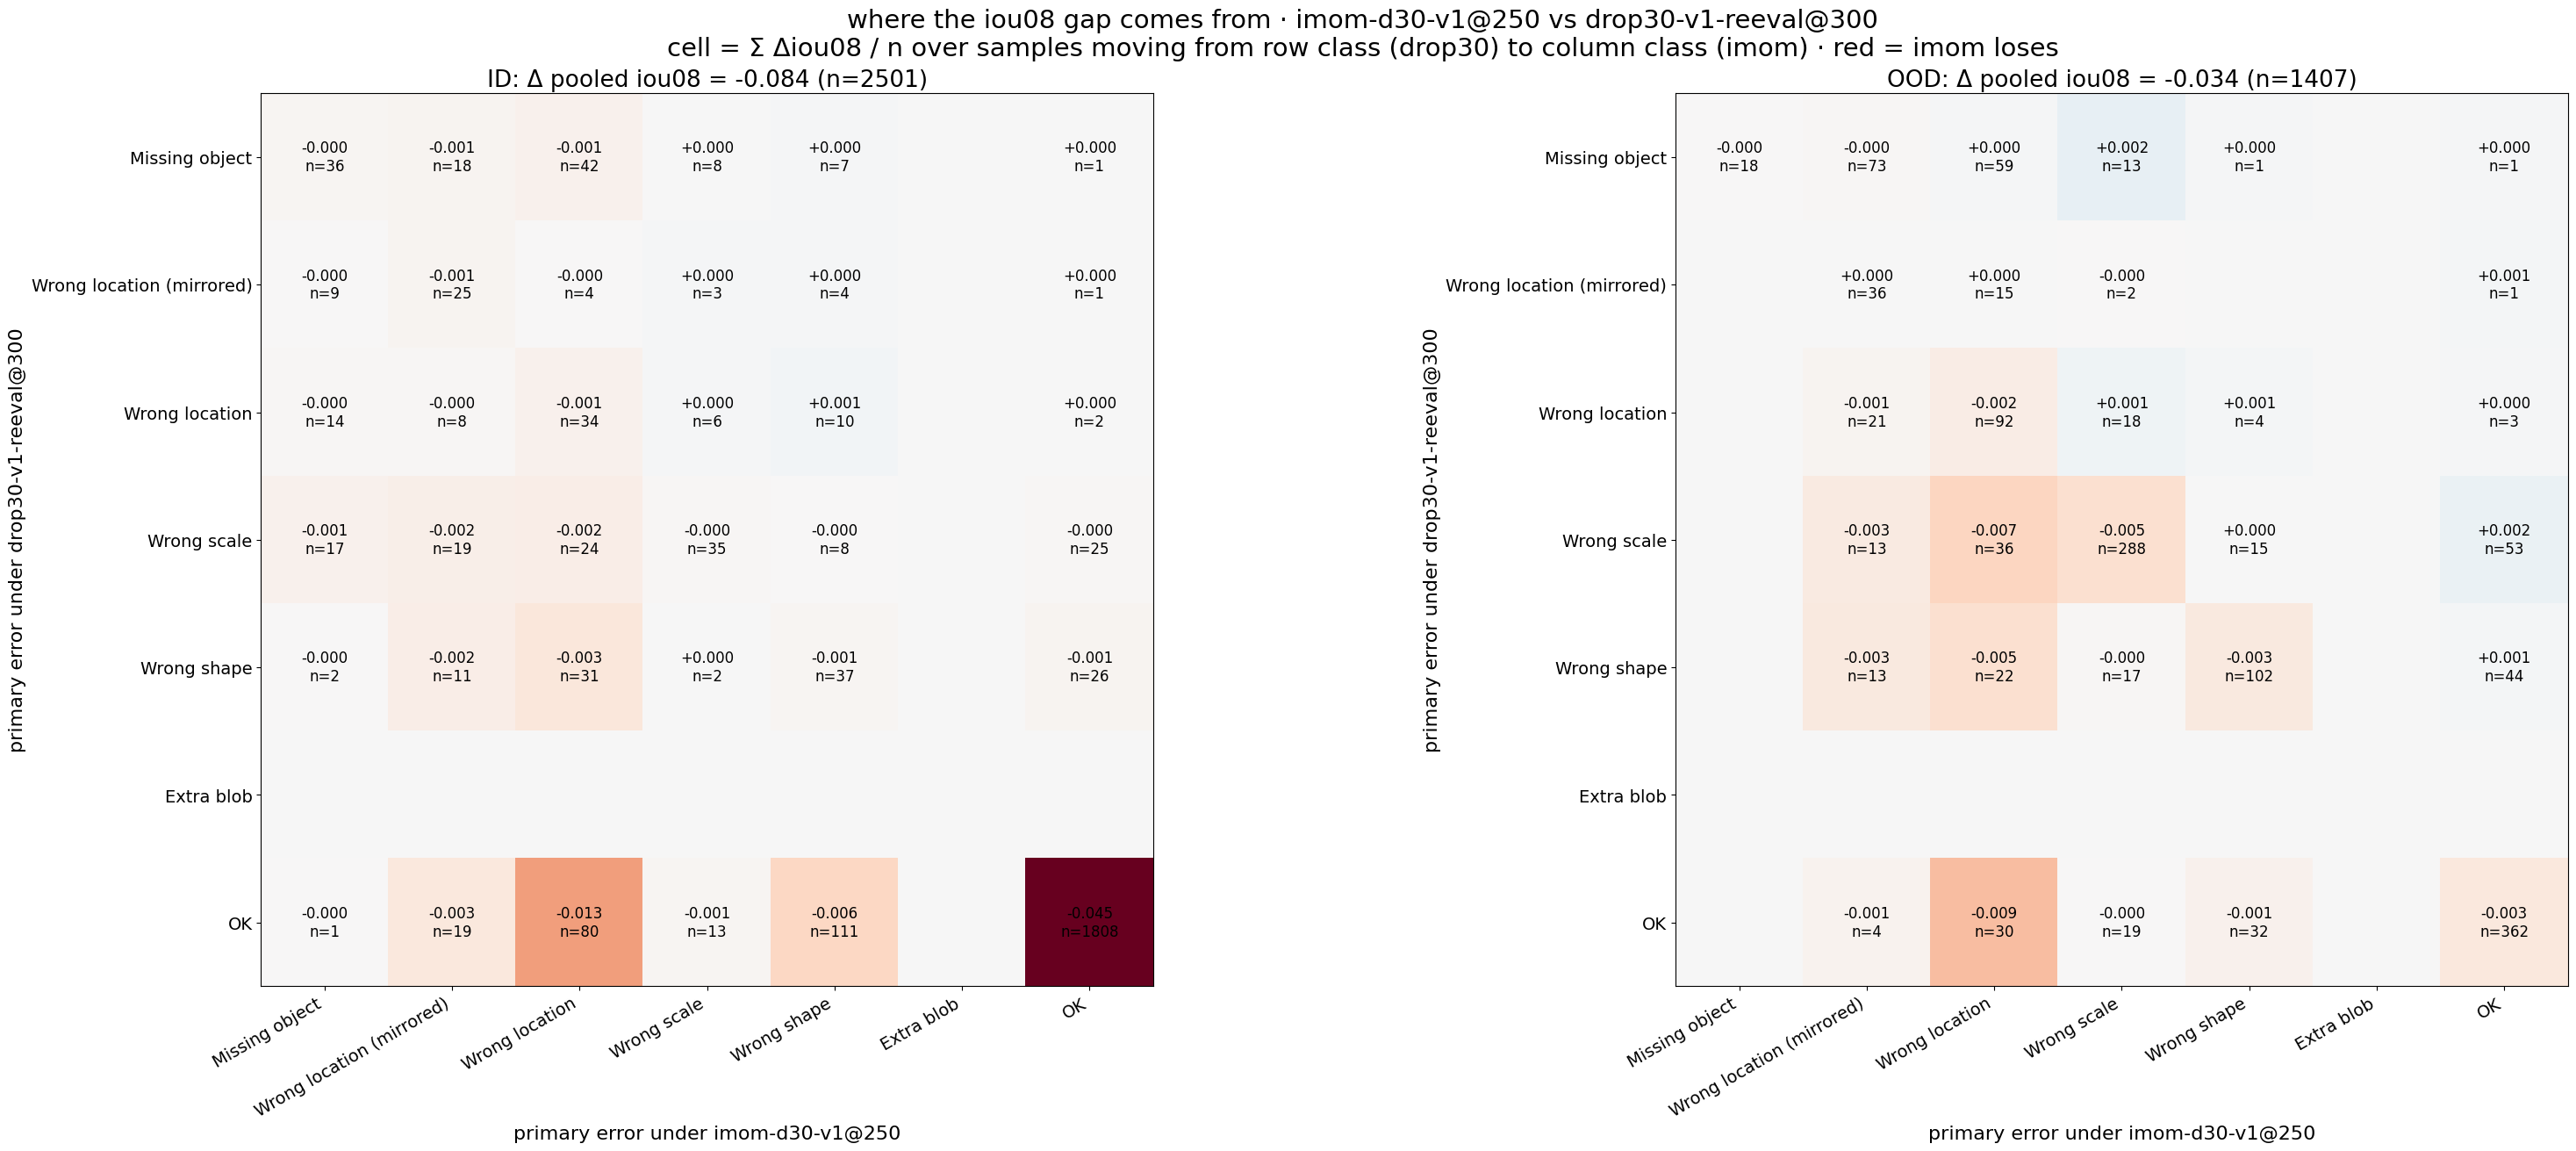

ID: gap -0.084 · by drop30's primary error (row sums): Missing object -0.002, Wrong location (mirrored) -0.000, Wrong location -0.001, Wrong scale -0.006, Wrong shape -0.007, Extra blob +0.000, OK -0.068
ID: gap -0.084 · by imom's primary error (column sums): Missing object -0.003, Wrong location (mirrored) -0.009, Wrong location -0.021, Wrong scale -0.000, Wrong shape -0.006, Extra blob +0.000, OK -0.046
ID: share of samples by primary error  drop30 → imom: Missing object 4→3%, Wrong location (mirrored) 2→4%, Wrong location 3→9%, Wrong scale 5→3%, Wrong shape 4→7%, Extra blob 0→0%, OK 81→74%
OOD: gap -0.034 · by drop30's primary error (row sums): Missing object +0.003, Wrong location (mirrored) +0.001, Wrong location -0.001, Wrong scale -0.012, Wrong shape -0.010, Extra blob +0.000, OK -0.015
OOD: gap -0.034 · by imom's primary error (column sums): Missing object -0.000, Wrong location (mirrored) -0.008, Wrong location -0.022, Wrong scale -0.001, Wrong shape -0.003, Extra blob +0.000,

In [11]:
# paired: same eval samples in both runs; Δ iou08 summed per (primary error under drop30, under imom) cell, / n -> contribution to the pooled gap
K = ["experiment", "sample_id", "position_id", "speaker", "box", "split"]
NAMES = [n for n, _, _ in PRIMARY]
def paired(a, b, cats):
    sa, sb = cat(DS[a], cats).drop_duplicates(K), cat(DS[b], cats).drop_duplicates(K)
    m = sb.assign(pb=primary(sb)).merge(sa.assign(pa=primary(sa)), on=K, suffixes=("_b", "_a"))
    m = m[m.n_obj_b > 0]
    T = np.zeros((7, 7)); np.add.at(T, (m.pb, m.pa), (m.iou08_a - m.iou08_b) / len(m))
    C = np.zeros((7, 7)); np.add.at(C, (m.pb, m.pa), 1)
    return T, C, len(m), (m.iou08_a - m.iou08_b).mean()

fig, axes = plt.subplots(1, 2, figsize=(32, 13), constrained_layout=True)
for ax, (g, cs) in zip(axes, (("ID", ID_CATS), ("OOD", OOD_CATS))):
    T, C, n, gap = paired(IMOM, BASE, cs)
    ax.imshow(T, cmap="RdBu", vmin=-0.03, vmax=0.03)
    for i in range(7):
        for j in range(7):
            if C[i, j]: ax.text(j, i, f"{T[i, j]:+.3f}\nn={int(C[i, j])}", ha="center", va="center", fontsize=12)
    ax.set_xticks(range(7), NAMES, rotation=30, ha="right"); ax.set_yticks(range(7), NAMES)
    ax.set_xlabel(f"primary error under {IMOM}"); ax.set_ylabel(f"primary error under {BASE}")
    ax.set_title(f"{g}: Δ pooled iou08 = {gap:+.3f} (n={n})", fontsize=19)
fig.suptitle(f"where the iou08 gap comes from · {IMOM} vs {BASE}\ncell = Σ Δiou08 / n over samples moving from row class (drop30) to column class (imom) · red = imom loses", fontsize=21)
plt.show()

for g, cs in (("ID", ID_CATS), ("OOD", OOD_CATS)):
    T, C, n, gap = paired(IMOM, BASE, cs)
    print(f"{g}: gap {gap:+.3f} · by drop30's primary error (row sums): " + ", ".join(f"{NAMES[i]} {T[i].sum():+.3f}" for i in range(7)))
    print(f"{g}: gap {gap:+.3f} · by imom's primary error (column sums): " + ", ".join(f"{NAMES[j]} {T[:, j].sum():+.3f}" for j in range(7)))
    print(f"{g}: share of samples by primary error  drop30 → imom: " + ", ".join(f"{NAMES[j]} {100 * C[j].sum() / n:.0f}→{100 * C[:, j].sum() / n:.0f}%" for j in range(7)))

## Table

In [12]:
rows = []
for run in RUNS:
    for g, cats in (("train", ["train"]), ("ID", ID_CATS), ("OOD", OOD_CATS)):
        s, o = DS[run][DS[run].category.isin(cats)], DO[run][DO[run].category.isin(cats)]
        sf, mc = o[o.scale > SCALE_THR], o.mirror.value_counts()
        rows.append({"run": LABEL[run], "group": g, "n": len(s),
                     **{f"{n} · error rate %": round(100 * s[RATE[k]].mean(), 1) for k, n in METRICS},
                     **{f"{n} · mean error": round(s[k].mean(), 3) for k, n in METRICS if k != "missing"},
                     "mirrored (% of wrong-location samples)": round(mirrored(s), 1),
                     "wrong scale: too small %": round(100 * sf.too_small.mean(), 1), "wrong scale: too large %": round(100 * (1 - sf.too_small.mean()), 1),
                     **{f"mirror {m} (objects)": int(mc.get(m, 0)) for m in MIRRORS}})
TABLE = pd.DataFrame(rows).set_index(["run", "group"])
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
TABLE.T

run                                    imom-d30-v1@250                     drop30-v1-reeval@300                     imom-d30-v1@300                    
group                                            train        ID       OOD                train        ID       OOD           train        ID       OOD
n                                             1280.000  2501.000  1419.000            11219.000  2501.000  1419.000       11219.000  2501.000  1419.000
Missing object · error rate %                    3.500     3.200     1.300                0.600     4.500    11.700           1.800     2.900     1.400
Wrong location · error rate %                   20.900    13.800    29.400                0.900     5.400    13.600          12.000    13.000    28.500
Wrong scale · error rate %                       7.400     6.800    43.300                2.200     9.100    38.500           5.000     7.100    42.100
Wrong shape · error rate %                      23.500    19.200    41.900                5.300    13.000    35.000          19.600    19.000    41.800
Extra blob · error rate %                       16.300     8.000    30.000                2.900     3.100    24.200          10.500     7.800    29.500
Wrong location · mean error                      0.036     0.025     0.066                0.005     0.016     0.036           0.022     0.024     0.065
Wrong scale · mean error                         0.070     0.060     0.251                0.036     0.066     0.244           0.049     0.060     0.250
Wrong shape · mean error                         0.245     0.232     0.326                0.172     0.210     0.334           0.233     0.232     0.326
Extra blob · mean error                          0.127     0.053     0.259                0.028     0.020     0.205           0.082     0.051     0.254
mirrored (% of wrong-location samples)          31.800    31.400    38.600               52.500    36.000    28.100          33.800    32.800    39.200
wrong scale: too small %                        61.200    62.400    33.700               36.800    77.900    45.500          51.800    68.900    35.600
wrong scale: too large %                        38.800    37.600    66.300               63.200    22.100    54.500          48.200    31.100    64.400
mirror flip-x (objects)                         31.000    34.000    50.000                8.000    15.000    15.000         114.000    38.000    50.000
mirror flip-y (objects)                         42.000    70.000    72.000               29.000    36.000    21.000         278.000    69.000    71.000
mirror rot180 (objects)                         12.000     5.000    38.000               16.000     1.000    18.000          60.000     4.000    36.000

Too small / too large is over wrong-scale objects; mirror counts are objects (flip-x = column mirrored, flip-y = row mirrored).

## D · pooled iou08 over training
imom-d30-v1: recomputed here from its saved eval outputs (eager post-fix eval: clean). drop30-v1: no un-biased trajectory exists (only its ep300 weights were re-evaluated), so the curve is its **logged** wandb `metrics/eval/{id,ood}/iou08` from the old compiled eval, **biased ≈ −.01** by the compile-eval bug (at ep300 logged .664 / .384 vs re-evaluated .671 / .386); the re-evaluated ep300 point is the star.

imom-d30-v1 (clean)        drop30-v1 (logged, biased ~-.01)       
                     ID    OOD                               ID    OOD
0                 0.019  0.016                            0.019  0.016
50                0.111  0.095                            0.401  0.271
100               0.400  0.265                            0.585  0.376
150               0.497  0.309                            0.636  0.383
200               0.537  0.332                            0.650  0.382
250               0.587  0.351                            0.657  0.376
300               0.595  0.355                            0.664  0.384

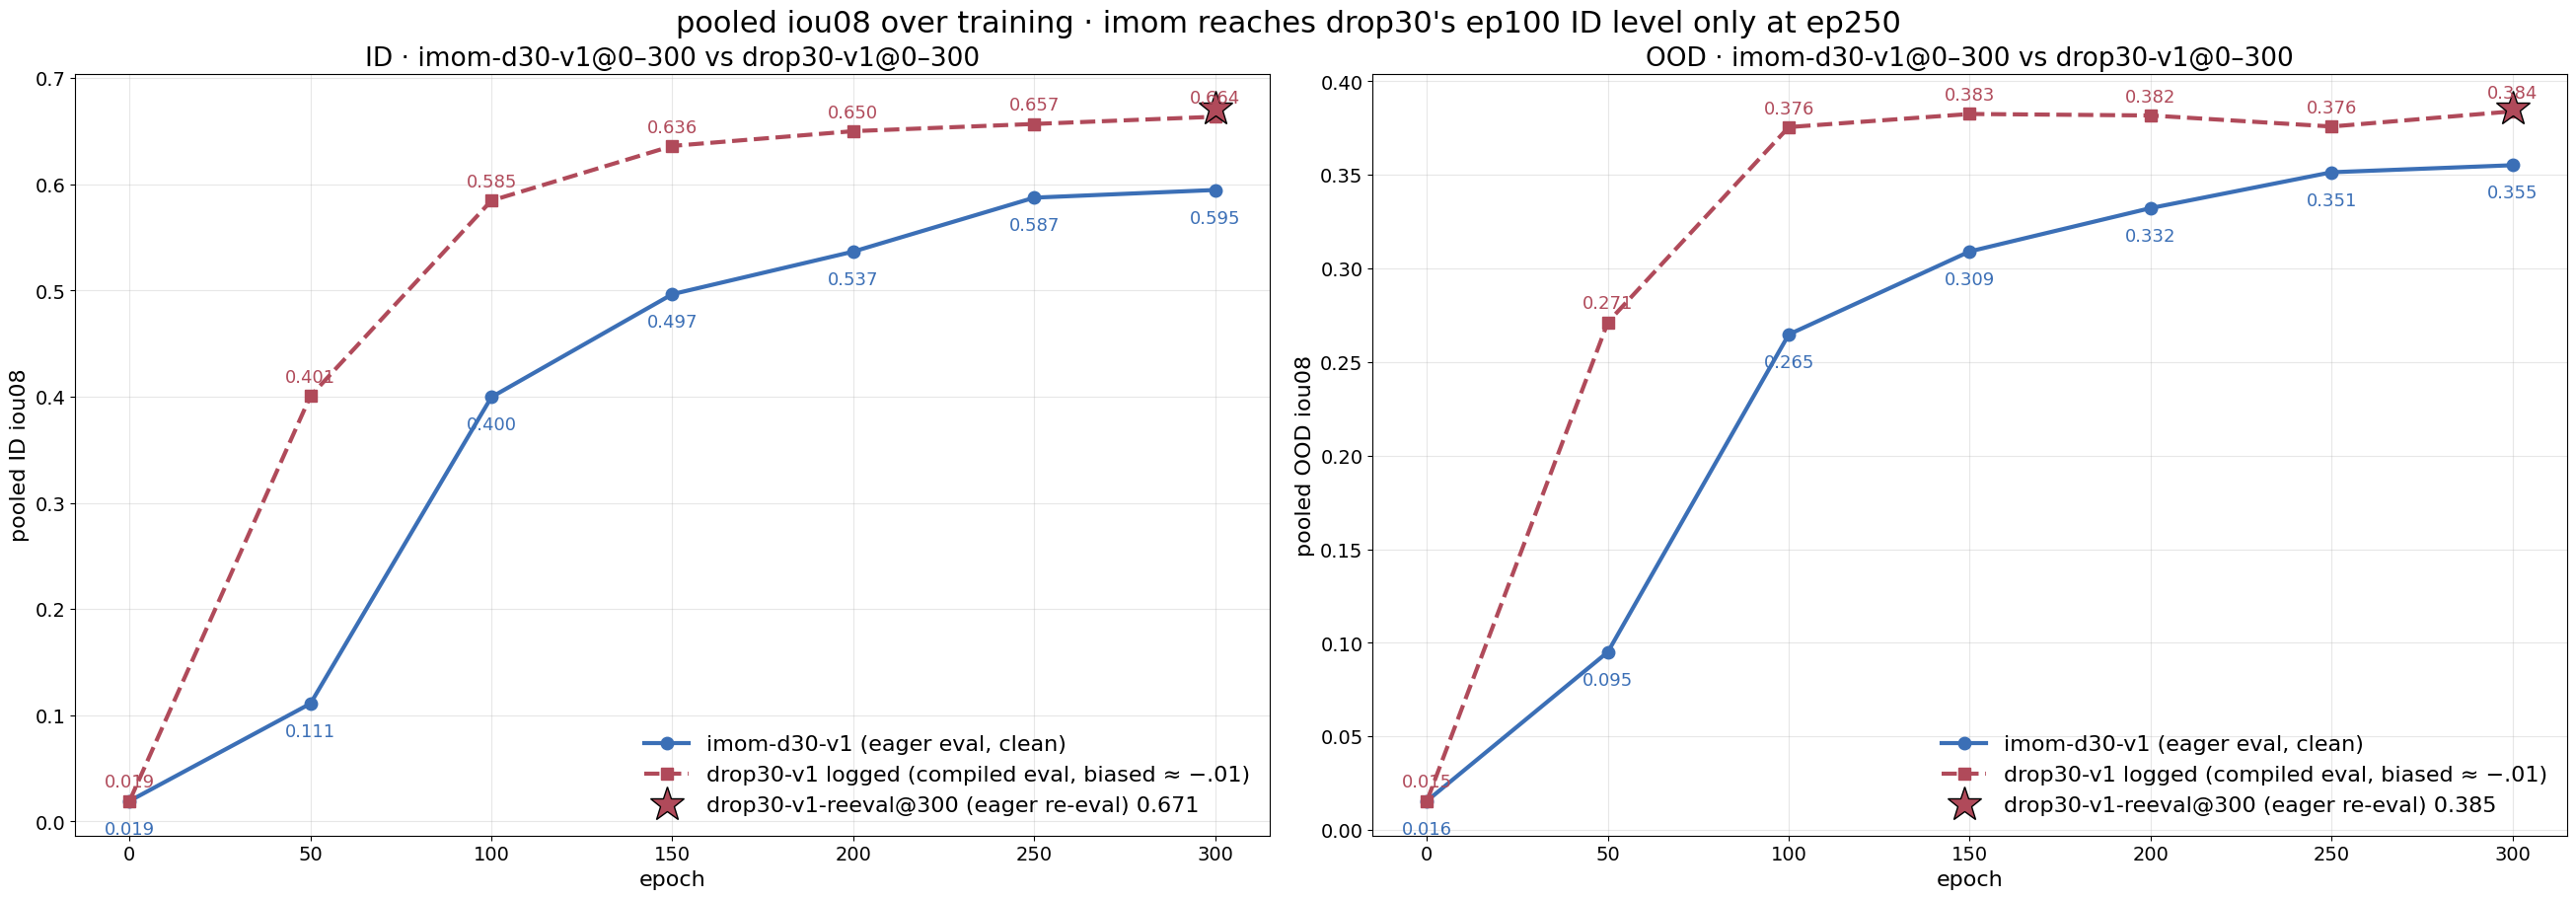

In [13]:
def pooled_curve(run):
    """per-sample mean iou08 over ID / OOD splits at every saved eval epoch (truth cached by score.truth)"""
    f = Path(CACHE) / f"curve_{run}.pkl"
    eps = sorted({int(p.name[2:6]) for p in (ROOT / "runs" / run / "outputs_history/eval").rglob("ep*.pt")})
    if f.exists() and (c := pickle.load(open(f, "rb"))).index.tolist() == eps: return c
    rows = {}
    for ep in eps:
        v = {"ID": [], "OOD": []}
        for pt in sorted((ROOT / "runs" / run / "outputs_history/eval").glob(f"*/*/ep{ep:04d}-ba*.pt")):
            c = CAT.get((pt.parent.parent.name, pt.parent.name)); g = "ID" if c in ID_CATS else "OOD" if c in OOD_CATS else None
            if g is None: continue
            d = torch.load(pt, weights_only=False, map_location="cpu"); P, info = d["mask_pred"].float().numpy(), d["info"]
            for i in range(len(P)):
                y = truth(info["experiment"][i], int(info["sample_id"][i]), int(info["position_id"][i]), int(info["speaker"][i]), H, W) > 0.5
                if y.any(): b = P[i] > THR; v[g].append((b & y).sum() / (b | y).sum())
        rows[ep] = {g: np.mean(x) for g, x in v.items()}
    c = pd.DataFrame(rows).T; pickle.dump(c, open(f, "wb")); return c

IMOM_CURVE = pooled_curve("imom-d30-v1")
# drop30-v1 logged (wandb better-tsa/drop30-v1, metrics/eval/{id,ood}/iou08, compiled eval: biased ~ -.01)
DROP30_LOGGED = pd.DataFrame({"ID": [0.0194, 0.4007, 0.5847, 0.6362, 0.6501, 0.6569, 0.6637], "OOD": [0.0155, 0.2713, 0.3756, 0.3826, 0.3818, 0.3759, 0.3840]},
                             index=[0, 50, 100, 150, 200, 250, 300])
REEVAL = {g: cat(DS[BASE], cs).iou08.mean() for g, cs in (("ID", ID_CATS), ("OOD", OOD_CATS))}
display(pd.concat({"imom-d30-v1 (clean)": IMOM_CURVE, "drop30-v1 (logged, biased ~-.01)": DROP30_LOGGED}, axis=1).round(3))

fig, axes = plt.subplots(1, 2, figsize=(26, 9), constrained_layout=True)
for ax, g in zip(axes, ("ID", "OOD")):
    ax.plot(IMOM_CURVE.index, IMOM_CURVE[g], "o-", lw=3, ms=9, color=RUN_COLOR[0], label="imom-d30-v1 (eager eval, clean)")
    ax.plot(DROP30_LOGGED.index, DROP30_LOGGED[g], "s--", lw=3, ms=9, color=RUN_COLOR[1], label="drop30-v1 logged (compiled eval, biased ≈ −.01)")
    ax.plot([300], [REEVAL[g]], "*", ms=26, color=RUN_COLOR[1], mec="k", label=f"{BASE} (eager re-eval) {REEVAL[g]:.3f}")
    for e, v in IMOM_CURVE[g].items(): ax.annotate(f"{v:.3f}", (e, v), textcoords="offset points", xytext=(0, -24), ha="center", fontsize=13, color=RUN_COLOR[0])
    for e, v in DROP30_LOGGED[g].items(): ax.annotate(f"{v:.3f}", (e, v), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=13, color=RUN_COLOR[1])
    ax.set_xlabel("epoch"); ax.set_ylabel(f"pooled {g} iou08"); ax.set_title(f"{g} · imom-d30-v1@0–300 vs drop30-v1@0–300"); ax.legend(frameon=False, loc="lower right"); ax.grid(alpha=0.3)
fig.suptitle("pooled iou08 over training · imom reaches drop30's ep100 ID level only at ep250", fontsize=22)
plt.show()

## E · prediction style
Per sample with a non-empty target, at THR = 0.08 unless noted: **area ratio** = |p > .08| / |true| (1 = right size), **mass ratio** = Σp / |true|, **soft fraction** = share of the predicted pixels (p > .08) that are soft (.08 < p < .92), **biou** = boundary IoU of the 2 px inner bands (utils.biou), **miss08** = no predicted pixel on the truth.

iou08 (mean)  boundary IoU (mean)  soft-edge fraction (mean)  area ratio |p>.08| / |true| (median)  mass ratio Σp / |true| (median)  miss08 (% of samples)  area ratio mean  % over-painted (area>1.25)  \
run                  group                                                                                                                                                                                                            
imom-d30-v1@250      train         0.540                0.403                      0.453                                 1.233                            0.977                  9.350            1.326                      45.246   
                     ID            0.587                0.439                      0.431                                 1.244                            0.987                  2.999            1.277                      47.981   
                     OOD           0.351                0.253                      0.481                                 1.293                            0.982                 22.033            2.601                      51.955   
drop30-v1-reeval@300 train         0.824                0.735                      0.244                                 1.125                            1.004                  1.213            1.179                      17.674   
                     ID            0.671                0.539                      0.287                                 1.111                            0.977                  1.040            1.121                      17.433   
                     OOD           0.385                0.283                      0.349                                 1.011                            0.841                 19.190            1.786                      35.892   
imom-d30-v1@300      train         0.649                0.526                      0.422                                 1.220                            0.990                  5.339            1.325                      41.412   
                     ID            0.595                0.449                      0.428                                 1.222                            0.978                  2.879            1.259                      43.503   
                     OOD           0.355                0.258                      0.481                                 1.262                            0.963                 21.748            2.543                      50.604   

                            % under-painted (area<0.8)  
run                  group                              
imom-d30-v1@250      train                       1.981  
                     ID                          1.080  
                     OOD                        11.443  
drop30-v1-reeval@300 train                       0.507  
                     ID                          5.238  
                     OOD                        29.851  
imom-d30-v1@300      train                       0.534  
                     ID                          1.319  
                     OOD                        12.225

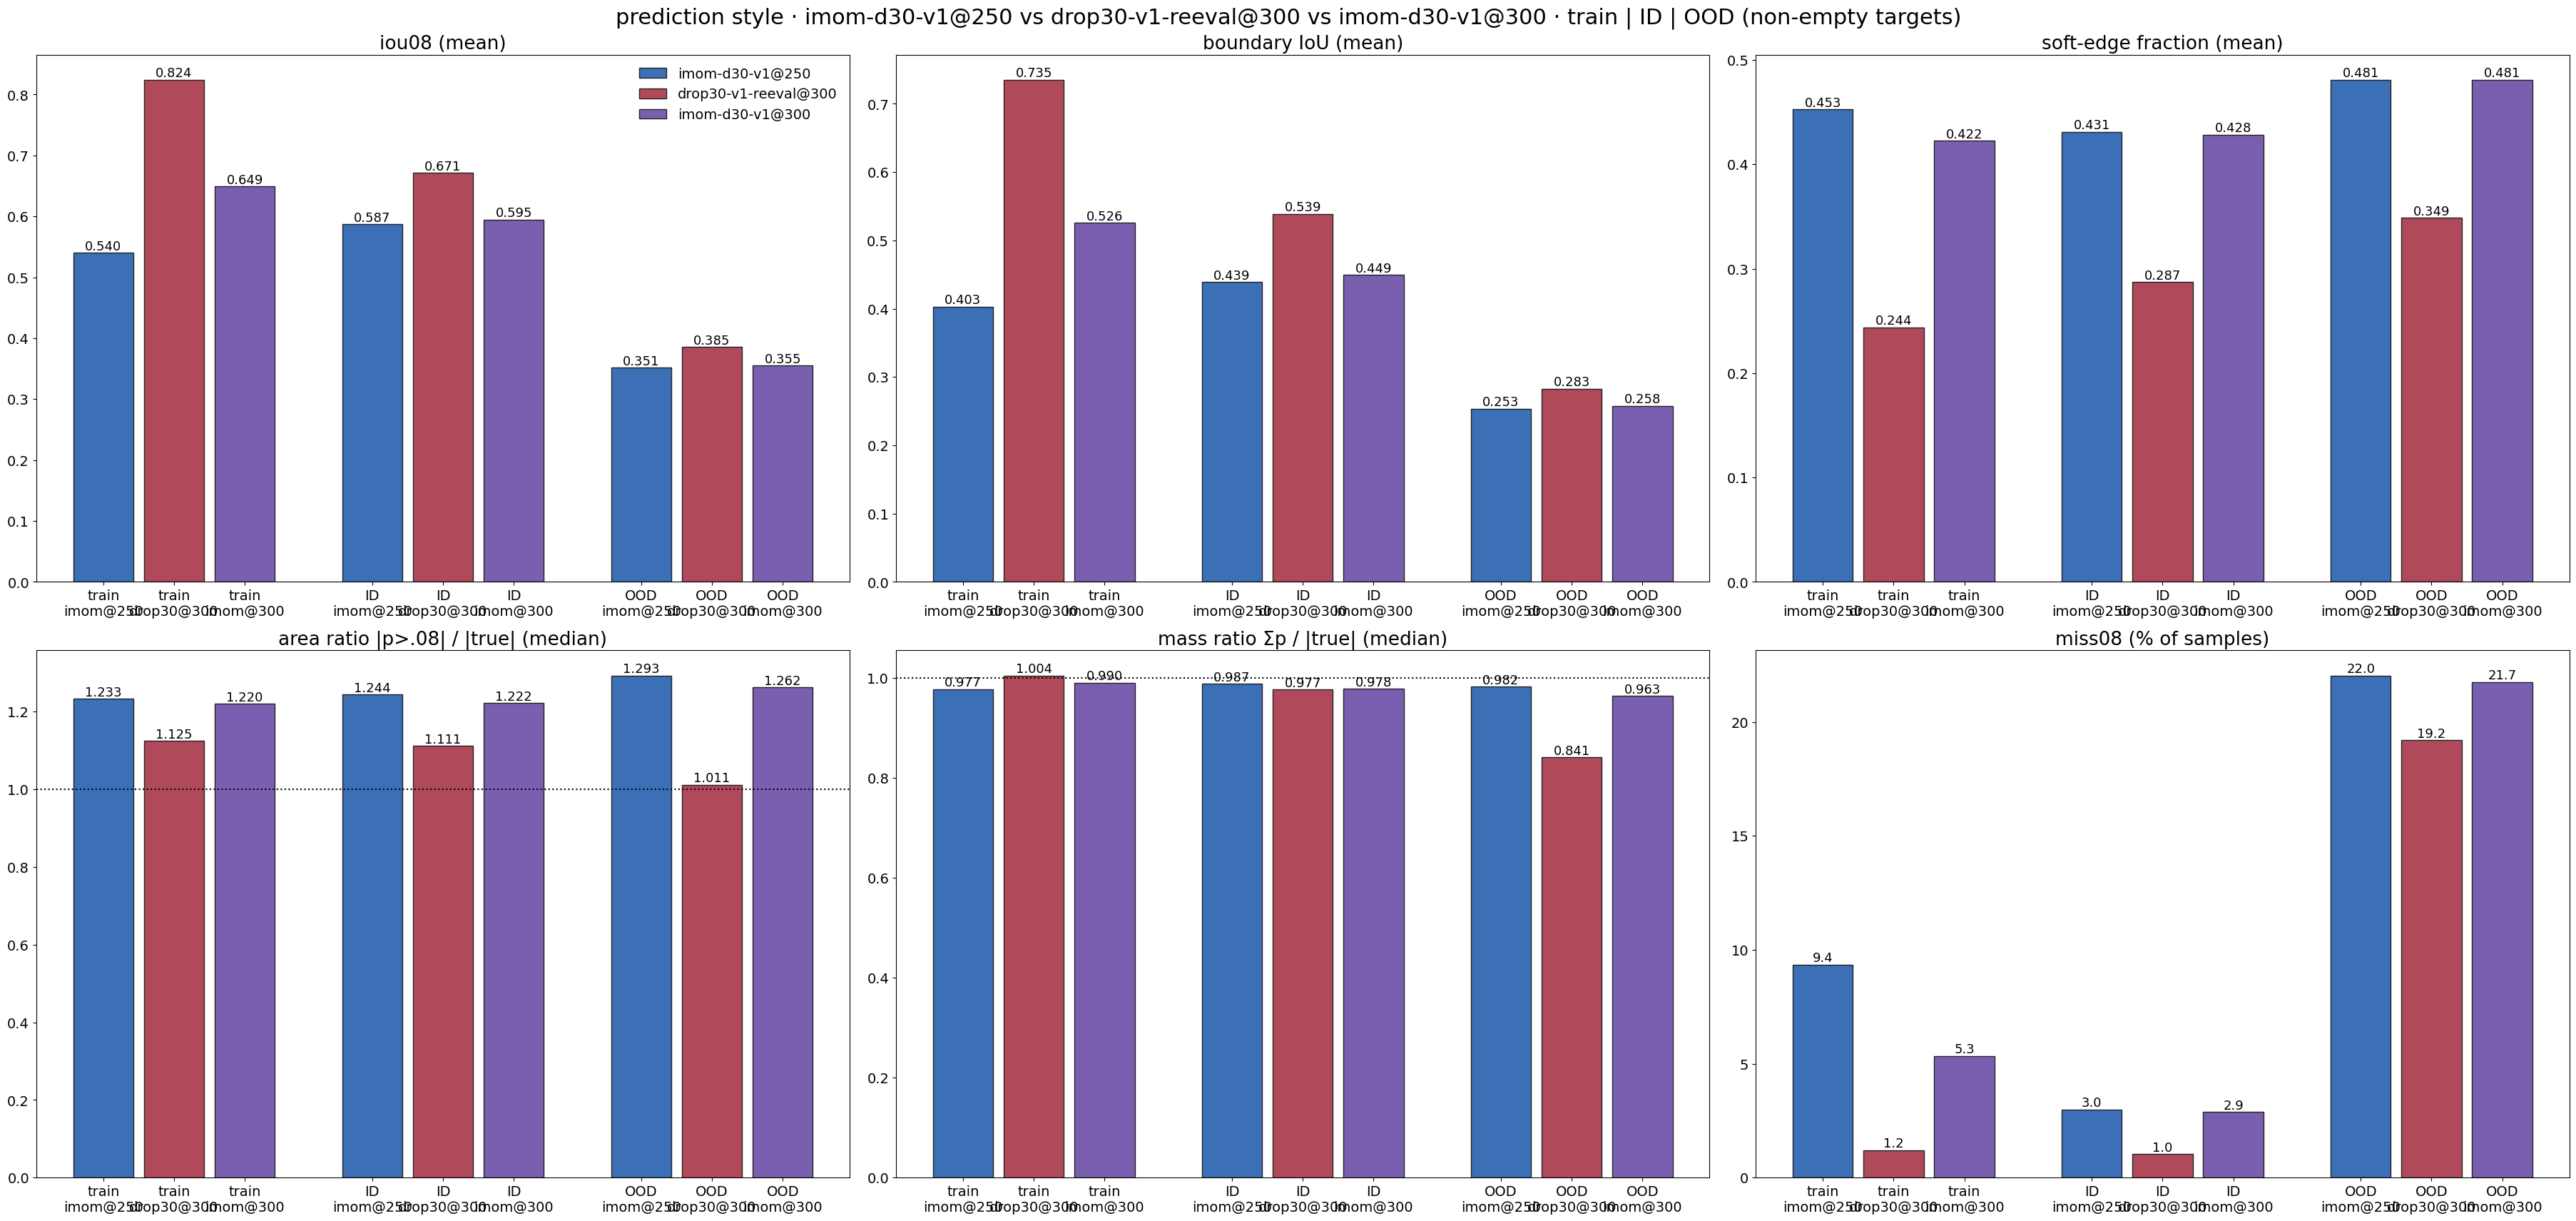

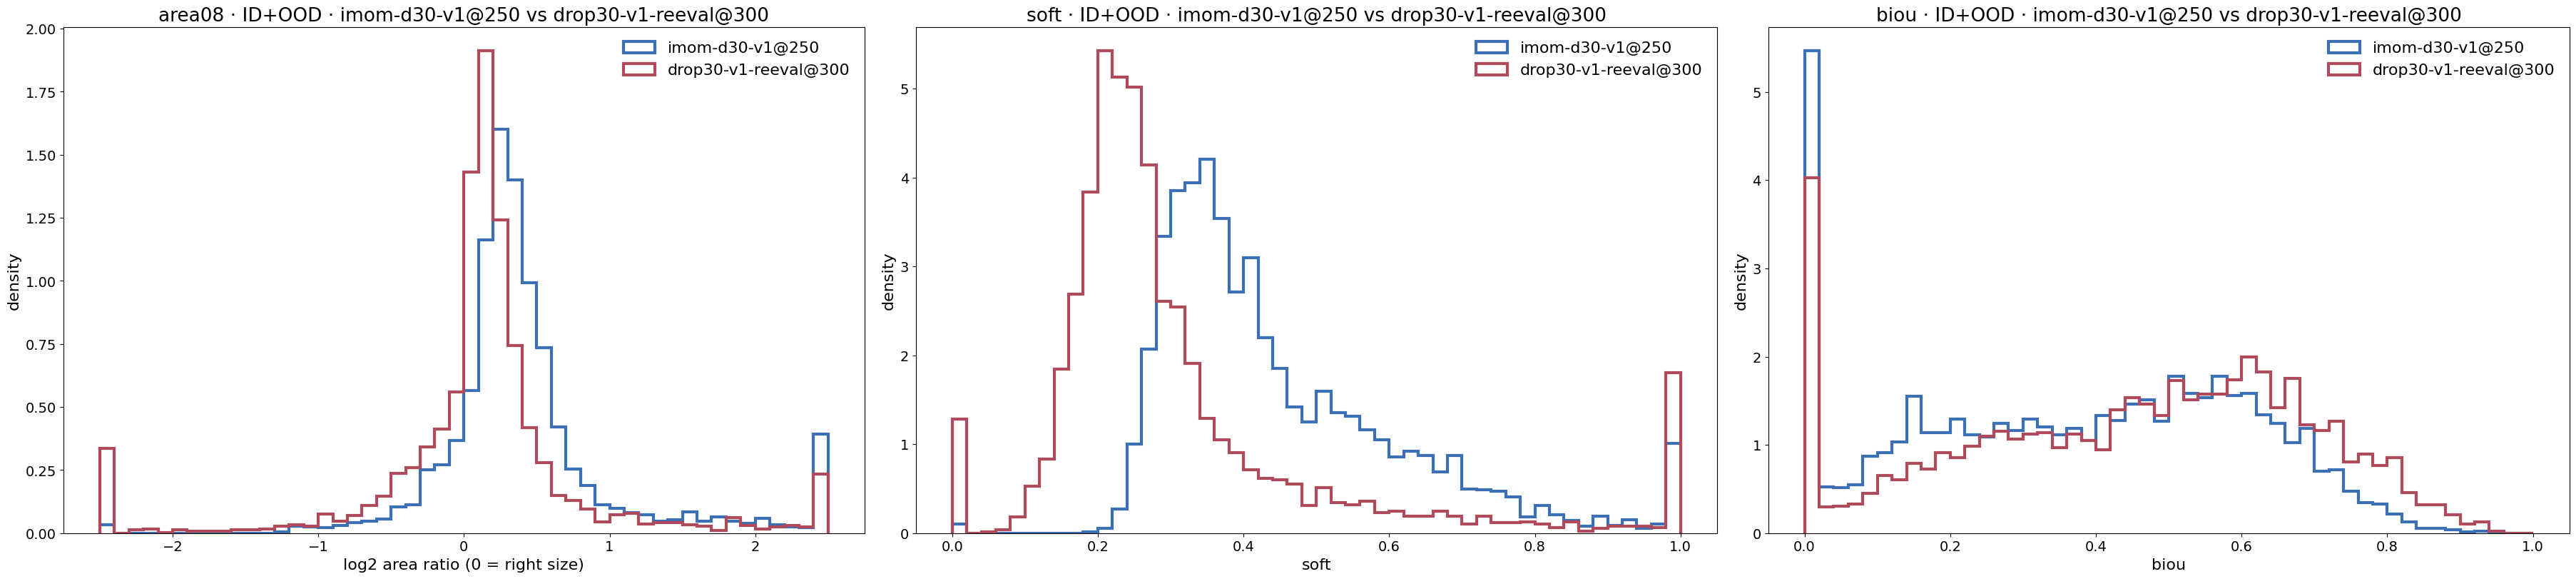

In [14]:
STY = [("iou08", "iou08 (mean)"), ("biou", "boundary IoU (mean)"), ("soft", "soft-edge fraction (mean)"), ("area08", "area ratio |p>.08| / |true| (median)"),
       ("mass_ratio", "mass ratio Σp / |true| (median)"), ("miss08", "miss08 (% of samples)")]
def sty(s, k): return 100 * s[k].mean() if k == "miss08" else s[k].median() if k in ("area08", "mass_ratio") else s[k].mean()
rows = []
for r in RUNS:
    for g, cs in (("train", "train"), ("ID", ID_CATS), ("OOD", OOD_CATS)):
        s = cat(DS[r], cs); s = s[s.n_obj > 0]
        rows.append({"run": r, "group": g, **{n: sty(s, k) for k, n in STY}, "area ratio mean": s.area08.mean(),
                     "% over-painted (area>1.25)": 100 * (s.area08 > 1.25).mean(), "% under-painted (area<0.8)": 100 * (s.area08 < 0.8).mean()})
STYLE = pd.DataFrame(rows).set_index(["run", "group"]); display(STYLE.round(3))

fig, axes = plt.subplots(2, 3, figsize=(36, 17), constrained_layout=True)
for ax, (k, n) in zip(axes.flat, STY):
    pos, xt = 0, []
    for g, cs in (("train", "train"), ("ID", ID_CATS), ("OOD", OOD_CATS)):
        for i, r in enumerate(RUNS):
            s = cat(DS[r], cs); v = sty(s[s.n_obj > 0], k)
            ax.bar(pos, v, 0.85, color=RUN_COLOR[i], edgecolor="#222", label=r if g == "train" else None)
            ax.text(pos, v, f"{v:.3f}" if k != "miss08" else f"{v:.1f}", ha="center", va="bottom", fontsize=13); xt.append((pos, f"{g}\n{r.split('-')[0]}@{r.split('@')[1]}")); pos += 1
        pos += 0.8
    if k in ("area08", "mass_ratio"): ax.axhline(1, color="k", ls=":")
    ax.set_xticks(*zip(*xt)); ax.set_title(n)
axes.flat[0].legend(frameon=False, fontsize=14)
fig.suptitle("prediction style · " + " vs ".join(RUNS) + " · train | ID | OOD (non-empty targets)", fontsize=22)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(36, 8), constrained_layout=True)
for ax, (k, rng, lg) in zip(axes, (("area08", (-2.5, 2.5), True), ("soft", (0, 1), False), ("biou", (0, 1), False))):
    for i, r in enumerate(RUNS[:2]):
        s = cat(DS[r], ID_CATS + OOD_CATS); v = s[s.n_obj > 0][k].dropna().to_numpy()
        v = np.log2(np.clip(v, 2 ** -2.5, 2 ** 2.5)) if lg else v
        ax.hist(v, bins=50, range=rng, histtype="step", lw=3, color=RUN_COLOR[i], density=True, label=r)
    ax.set_xlabel("log2 area ratio (0 = right size)" if lg else k); ax.set_ylabel("density"); ax.legend(frameon=False)
    ax.set_title(f"{k} · ID+OOD · {IMOM} vs {BASE}")
plt.show()

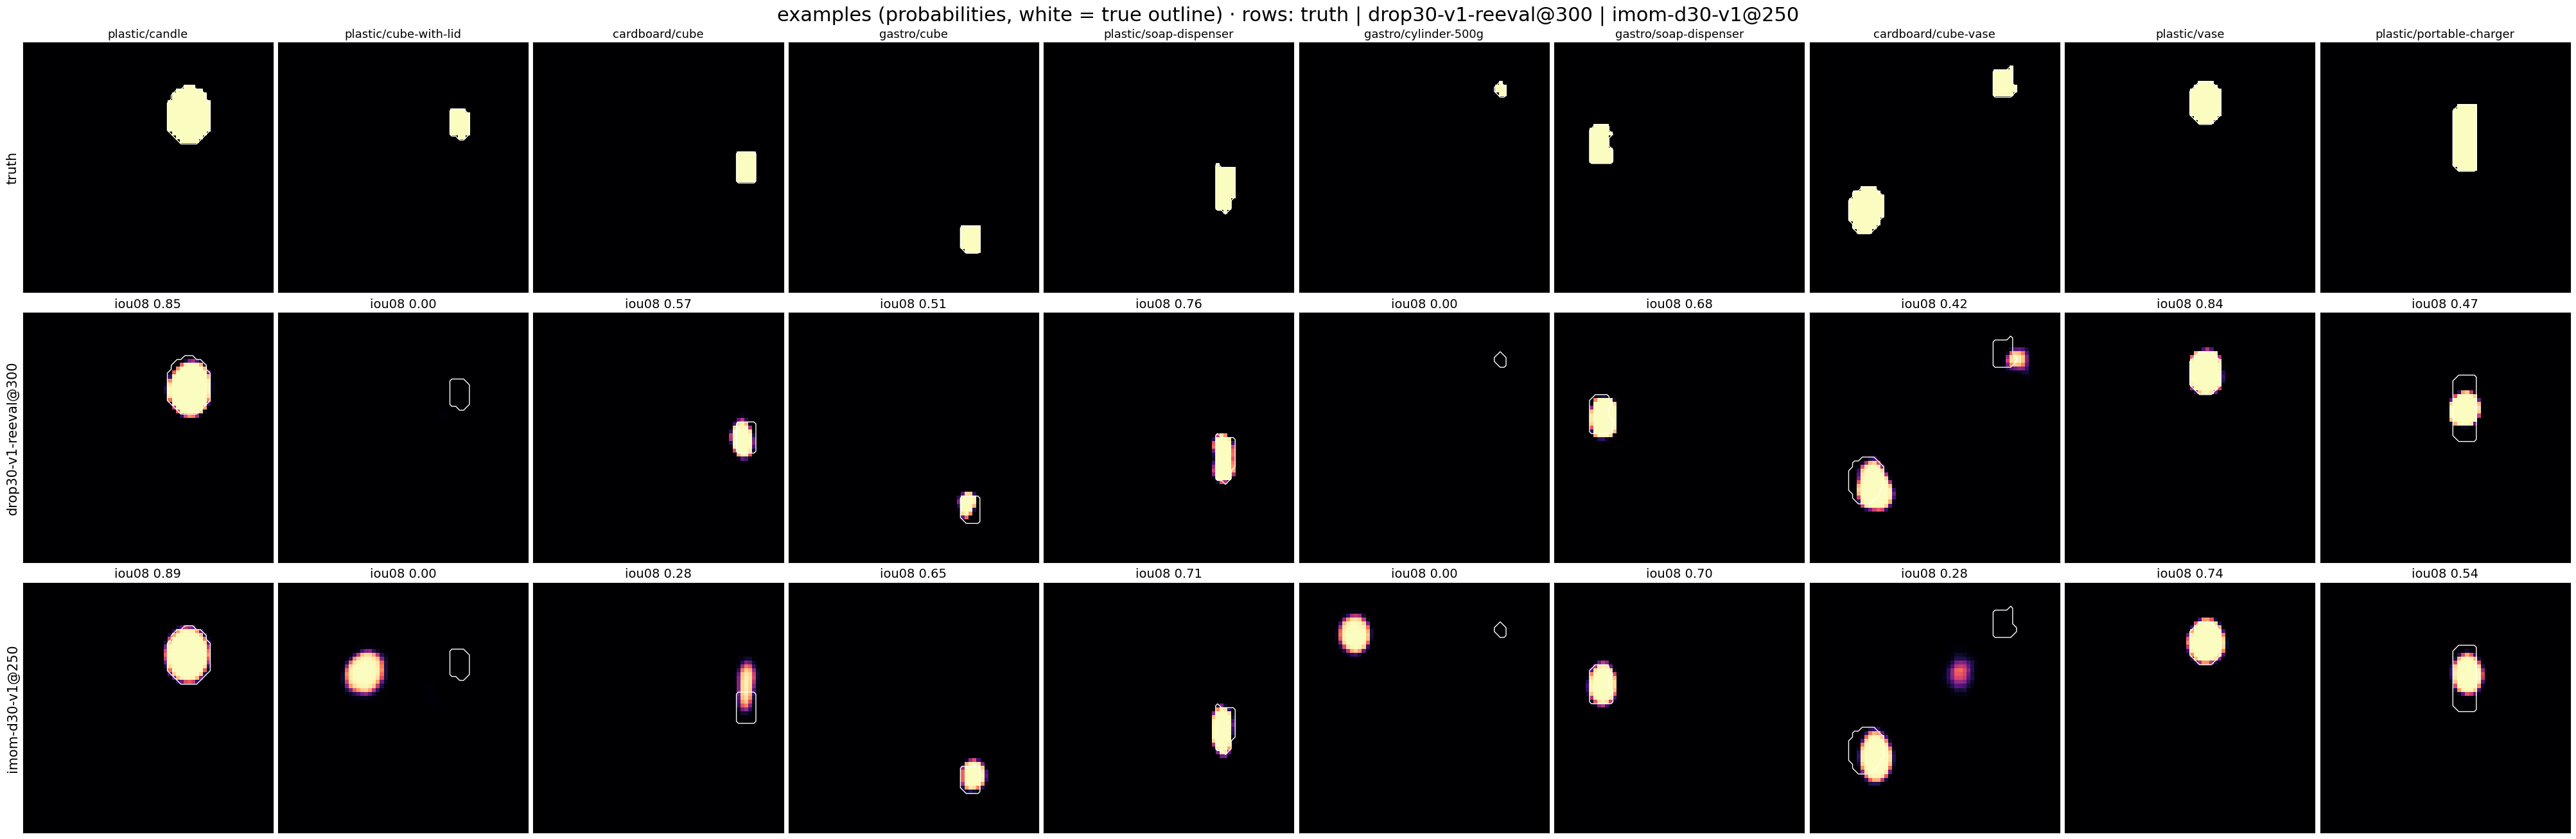

In [15]:
# examples: same eval samples, truth | drop30 | imom@250 (ID, random, seed 0), probabilities shown, truth outline in white
K = ["experiment", "sample_id", "position_id", "speaker", "box", "split"]
pick = cat(DS[BASE], ID_CATS + OOD_CATS); pick = pick[pick.n_obj > 0].drop_duplicates(K).sample(10, random_state=0)
def pred_of(run, ep, r):
    for pt in sorted((ROOT / "runs" / run / "outputs_history/eval" / r.box / r.split).glob(f"ep{ep:04d}-ba*.pt")):
        d = torch.load(pt, weights_only=False, map_location="cpu"); info = d["info"]
        for i in range(len(d["mask_pred"])):
            if (info["experiment"][i], int(info["sample_id"][i]), int(info["position_id"][i]), int(info["speaker"][i])) == (r.experiment, r.sample_id, r.position_id, r.speaker):
                return d["mask_pred"][i].float().numpy()
fig, axes = plt.subplots(3, 10, figsize=(40, 13), constrained_layout=True)
for j, (_, r) in enumerate(pick.iterrows()):
    y = truth(r.experiment, r.sample_id, r.position_id, r.speaker, H, W) > 0.5
    for i, (lab, p) in enumerate((("truth", y.astype(float)), (BASE, pred_of("drop30-v1-reeval", 0, r)), (IMOM, pred_of("imom-d30-v1", 250, r)))):
        ax = axes[i, j]; ax.imshow(p, vmin=0, vmax=1, cmap="magma"); ax.contour(y, [0.5], colors="w", linewidths=1); ax.set_xticks([]); ax.set_yticks([])
        if i: b = p > THR; ax.set_title(f"iou08 {(b & y).sum() / (b | y).sum():.2f}", fontsize=14)
        else: ax.set_title(f"{r.box}/{r.split}", fontsize=13)
        if j == 0: ax.set_ylabel(lab, fontsize=15)
fig.suptitle(f"examples (probabilities, white = true outline) · rows: truth | {BASE} | {IMOM}", fontsize=22)
plt.show()

## F · loss terms over training (runs/imom-d30-v1.log vs runs/drop30-v1.log)
`loss/train/<term>` per batch, averaged per epoch. imom-d30-v1's total = mask + 1.0·imoment + 1.0·outline + 0.1·object + 0.1·box; drop30-v1's = mask + 0.1·object + 0.1·box.

imom-d30-v1 epoch 1: {'box': 1.138, 'imoment': 16.223, 'mask': 0.826, 'object': 2.615, 'outline': 0.533, 'total': 17.958}
imom-d30-v1 epoch 300: {'box': 0.0, 'imoment': 0.158, 'mask': 0.209, 'object': 0.237, 'outline': 0.277, 'total': 0.668}
drop30-v1 epoch 300: {'box': 0.0, 'mask': 0.102, 'object': 0.069, 'total': 0.109}


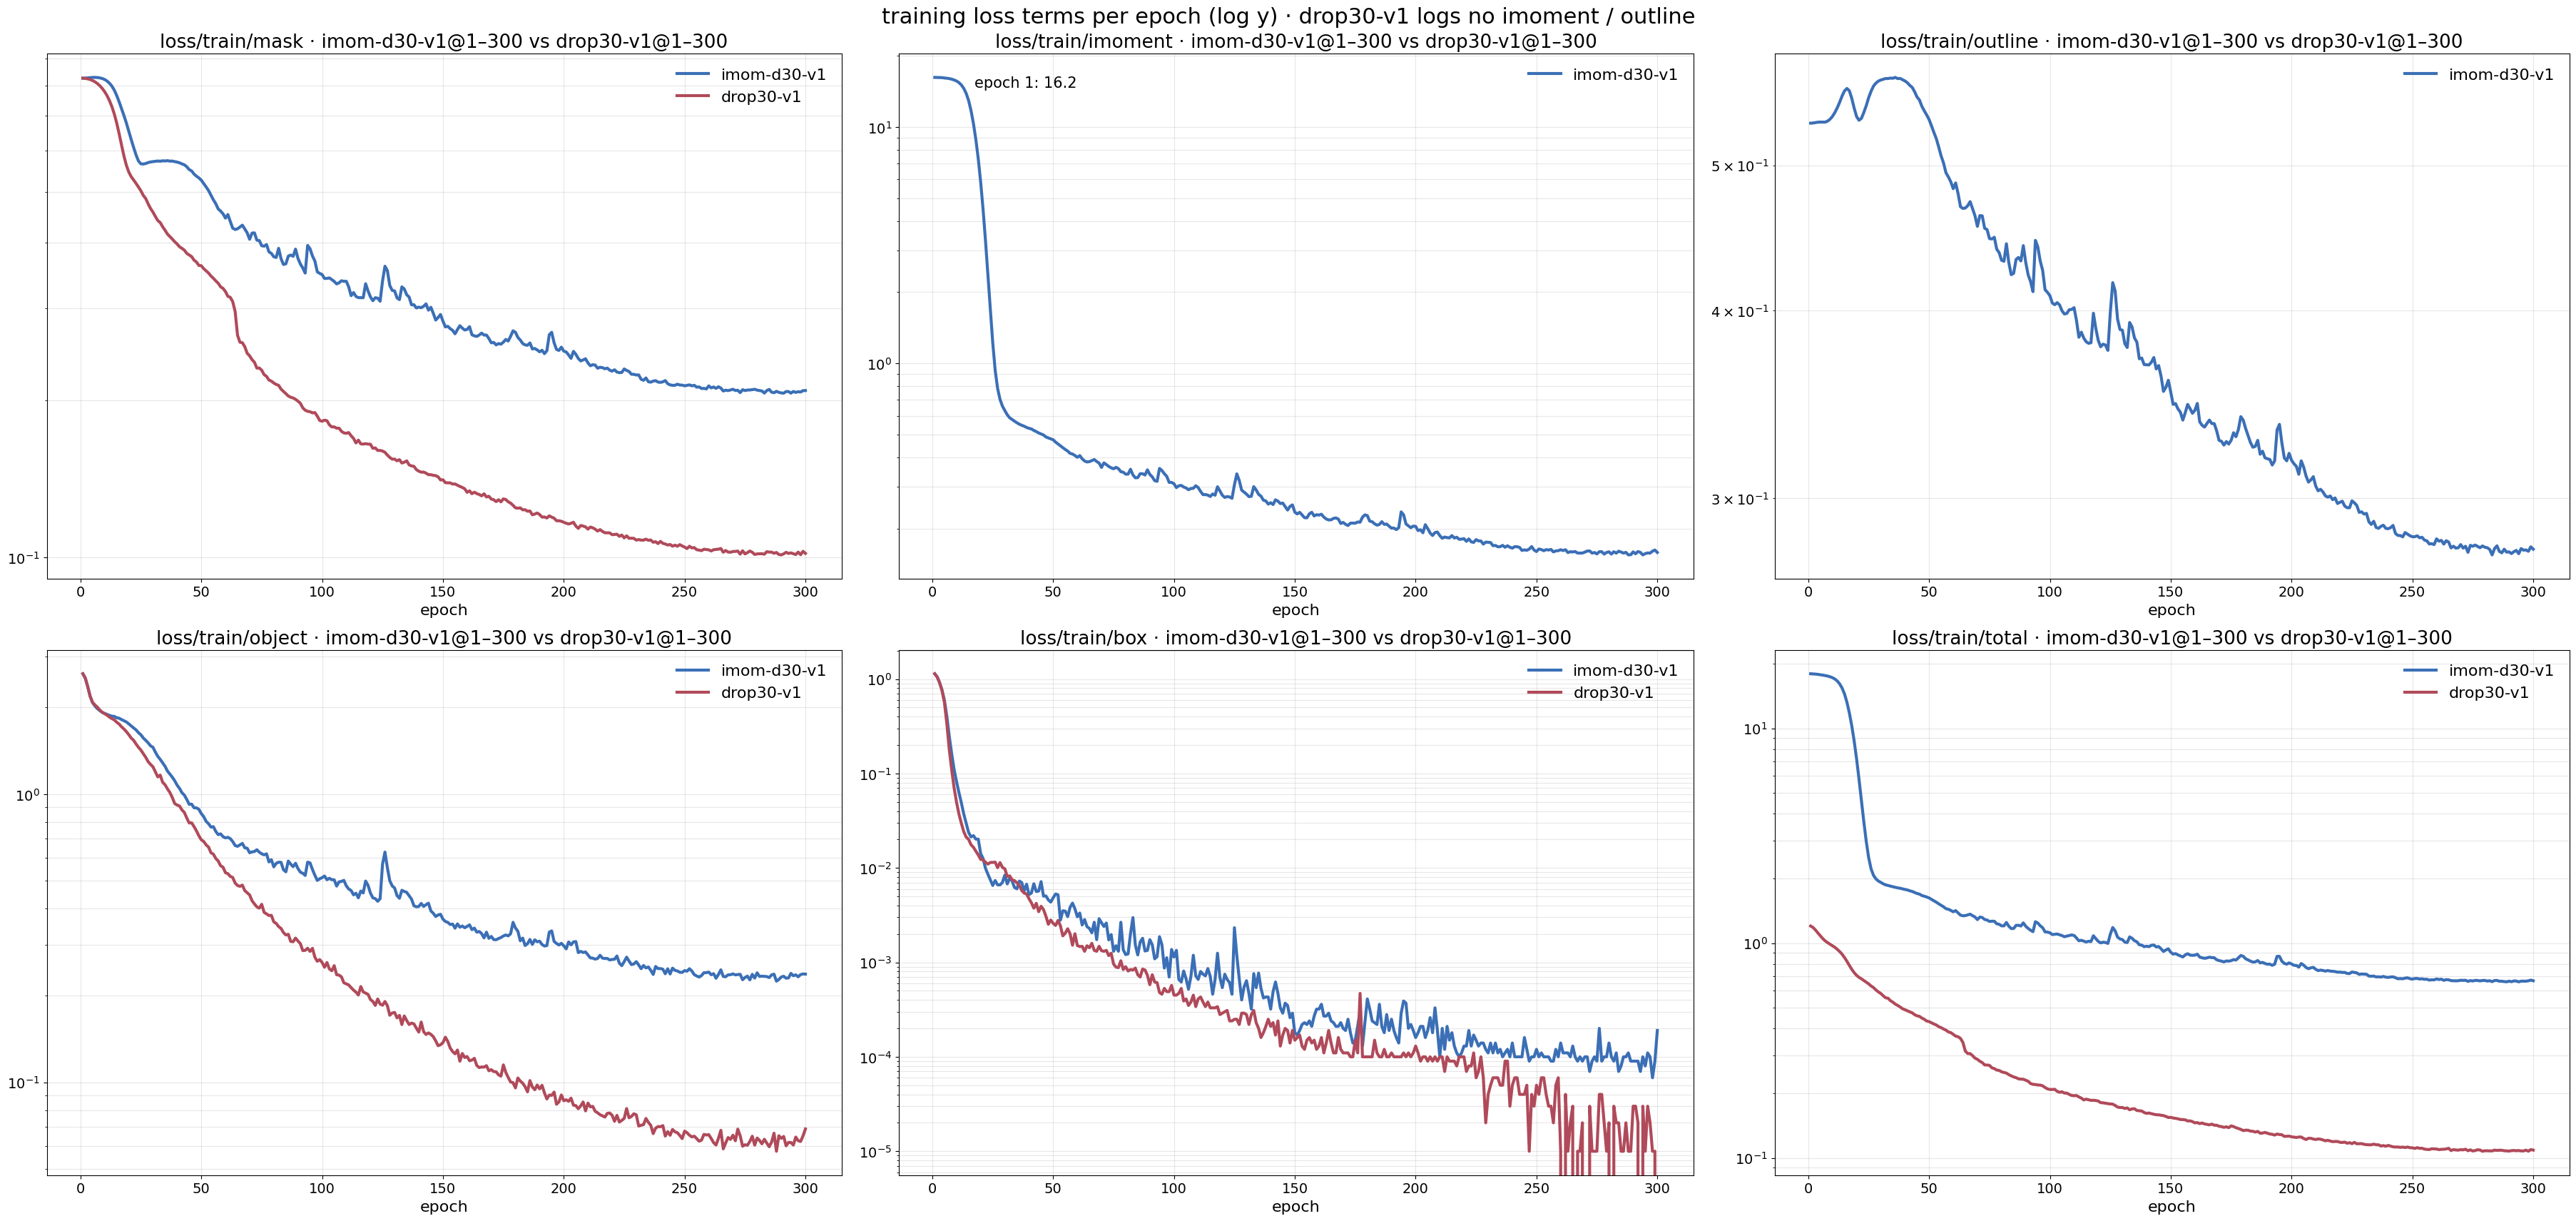

/tmp/ipykernel_1017371/3161829160.py:23: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  share = pd.DataFrame({t: w * LI[t] for t, w in W_.items()}); share = share.div(share.sum(1), axis=0)


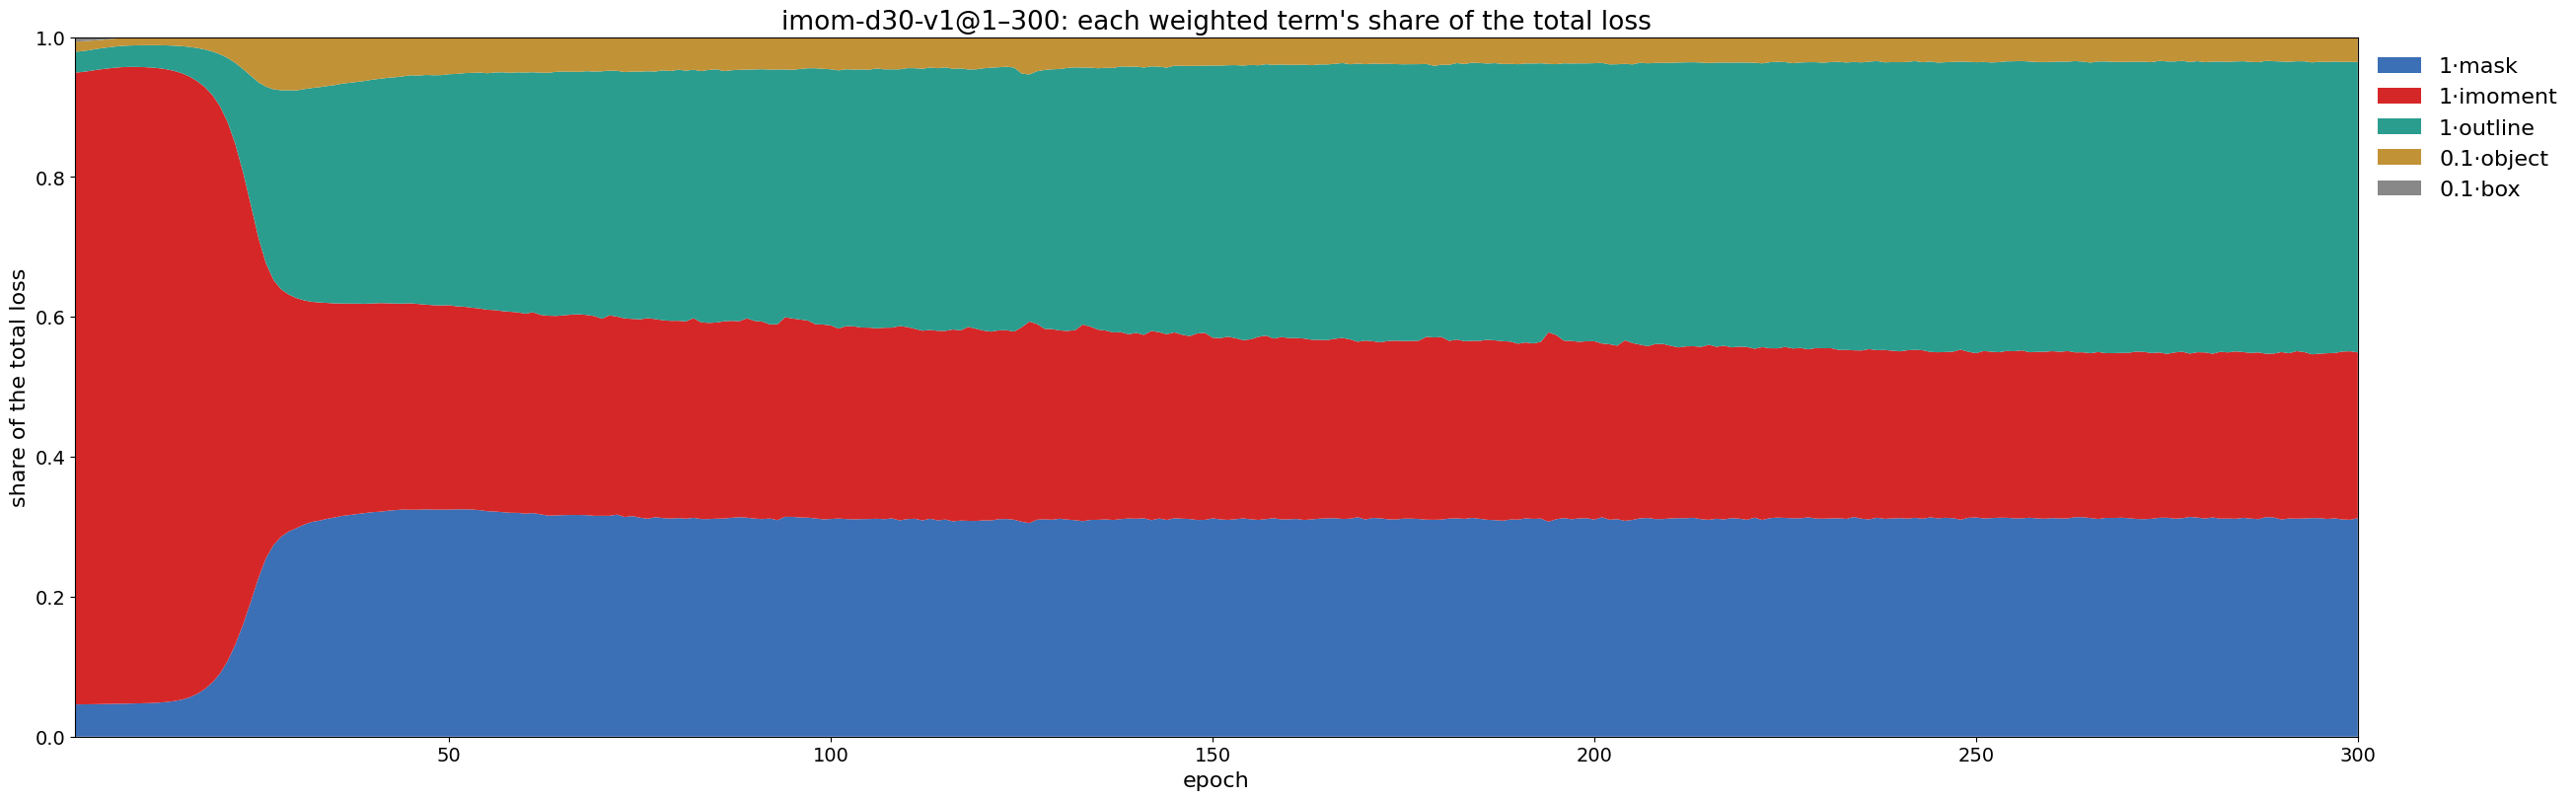

share of total, epochs 1 / 5 / 25 / 50 / 300:


,mask,imoment,outline,object,box
epoch,,,,,
1,0.046,0.903,0.030,0.015,0.006
5,0.047,0.908,0.030,0.012,0.003
25,0.226,0.487,0.222,0.064,0.000
50,0.325,0.292,0.330,0.053,0.000
300,0.312,0.237,0.415,0.035,0.000


In [16]:
import re
def parse_losses(log):
    """{epoch: {term: mean over the epoch's batches}} from the console log (Train loss/train/<term>: v under [epoch=N][batch=b/n])"""
    ep, rows = None, []
    for line in open(log, errors="ignore"):
        if m := re.match(r"\[epoch=(\d+)\]\[batch=(\d+)/\d+\]", line): ep = int(m[1])
        elif ep is not None and (m := re.search(r"Train loss/train/(\w+): ([-\d.eE+naif]+)", line)): rows.append((ep, m[1], float(m[2])))
    return pd.DataFrame(rows, columns=["epoch", "term", "v"]).pivot_table(index="epoch", columns="term", values="v", aggfunc="mean")

LI, LD = parse_losses(ROOT / "runs/imom-d30-v1.log"), parse_losses(ROOT / "runs/drop30-v1.log")
print("imom-d30-v1 epoch 1:", LI.iloc[0].round(3).to_dict()); print("imom-d30-v1 epoch 300:", LI.iloc[-1].round(3).to_dict()); print("drop30-v1 epoch 300:", LD.iloc[-1].round(3).to_dict())

fig, axes = plt.subplots(2, 3, figsize=(36, 17), constrained_layout=True)
for ax, t in zip(axes.flat, ("mask", "imoment", "outline", "object", "box", "total")):
    ax.plot(LI.index, LI[t], lw=3, color=RUN_COLOR[0], label="imom-d30-v1")
    if t in LD: ax.plot(LD.index, LD[t], lw=3, color=RUN_COLOR[1], label="drop30-v1")
    ax.set_yscale("log"); ax.set_title(f"loss/train/{t} · imom-d30-v1@1–300 vs drop30-v1@1–300"); ax.set_xlabel("epoch"); ax.grid(alpha=0.3, which="both"); ax.legend(frameon=False)
    if t == "imoment": ax.annotate(f"epoch 1: {LI[t].iloc[0]:.1f}", (1, LI[t].iloc[0]), xytext=(40, -10), textcoords="offset points", fontsize=15)
fig.suptitle("training loss terms per epoch (log y) · drop30-v1 logs no imoment / outline", fontsize=22)
plt.show()

W_ = {"mask": 1.0, "imoment": 1.0, "outline": 1.0, "object": 0.1, "box": 0.1}
share = pd.DataFrame({t: w * LI[t] for t, w in W_.items()}); share = share.div(share.sum(1), axis=0)
fig, ax = plt.subplots(figsize=(26, 8), constrained_layout=True)
ax.stackplot(share.index, *[share[t] for t in W_], labels=[f"{w:g}·{t}" for t, w in W_.items()], colors=["#3B6FB6", "#D62728", "#2A9D8F", "#C29237", "#888888"])
ax.set_xlabel("epoch"); ax.set_ylabel("share of the total loss"); ax.set_xlim(1, share.index.max()); ax.set_ylim(0, 1); ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
ax.set_title("imom-d30-v1@1–300: each weighted term's share of the total loss")
plt.show()
print("share of total, epochs 1 / 5 / 25 / 50 / 300:"); display(share.loc[[1, 5, 25, 50, share.index.max()]].round(3))

## G · gradient norm per loss term (CPU, checkpoints)
Each term's weighted gradient (imom-d30-v1's weights: mask 1, imoment 1, outline 1, object 0.1, box 0.1) on the same 128 train samples (32 microbatches of 4: CPU RAM ≤ 6 GB), train mode (augs + token dropout, as in training), fp32, averaged over the microbatches before taking the norm. Checkpoints: imom-d30-v1 init (seed 42 = drop30-v1's init) / ep100 / ep200 / ep300 and drop30-v1 ep100 / ep200 / ep300 (drop30 never trained on imoment / outline: its values show what those terms are for a model fit only with mask loss). `enc` = everything but the decoder. cos = cosine to the mask-loss gradient. The code below is the inline copy of what produced the cached JSON (rerun by deleting it).

who,imom-d30-v1@init,imom-d30-v1@ep100,imom-d30-v1@ep200,imom-d30-v1@ep300,drop30-v1@ep100,drop30-v1@ep200,drop30-v1@ep300
loss_mask,0.826,0.363,0.251,0.215,0.188,0.120,0.108
loss_imoment,15.958,0.290,0.190,0.160,0.513,0.290,0.211
loss_outline,0.534,0.417,0.322,0.286,0.275,0.186,0.166
loss_object,2.628,0.434,0.202,0.170,0.152,0.046,0.031
loss_box,1.164,0.002,0.003,0.000,0.000,0.000,0.000
gnorm_mask,0.448,1.259,1.187,1.512,1.648,1.357,1.879
gnorm_imoment,2.087,3.767,1.653,1.881,47.499,26.572,14.779
gnorm_outline,0.090,0.991,1.144,1.573,1.842,1.874,2.009
gnorm_object,0.507,0.542,0.442,0.464,0.605,0.470,0.431
gnorm_box,0.429,0.014,0.047,0.006,0.002,0.001,0.000


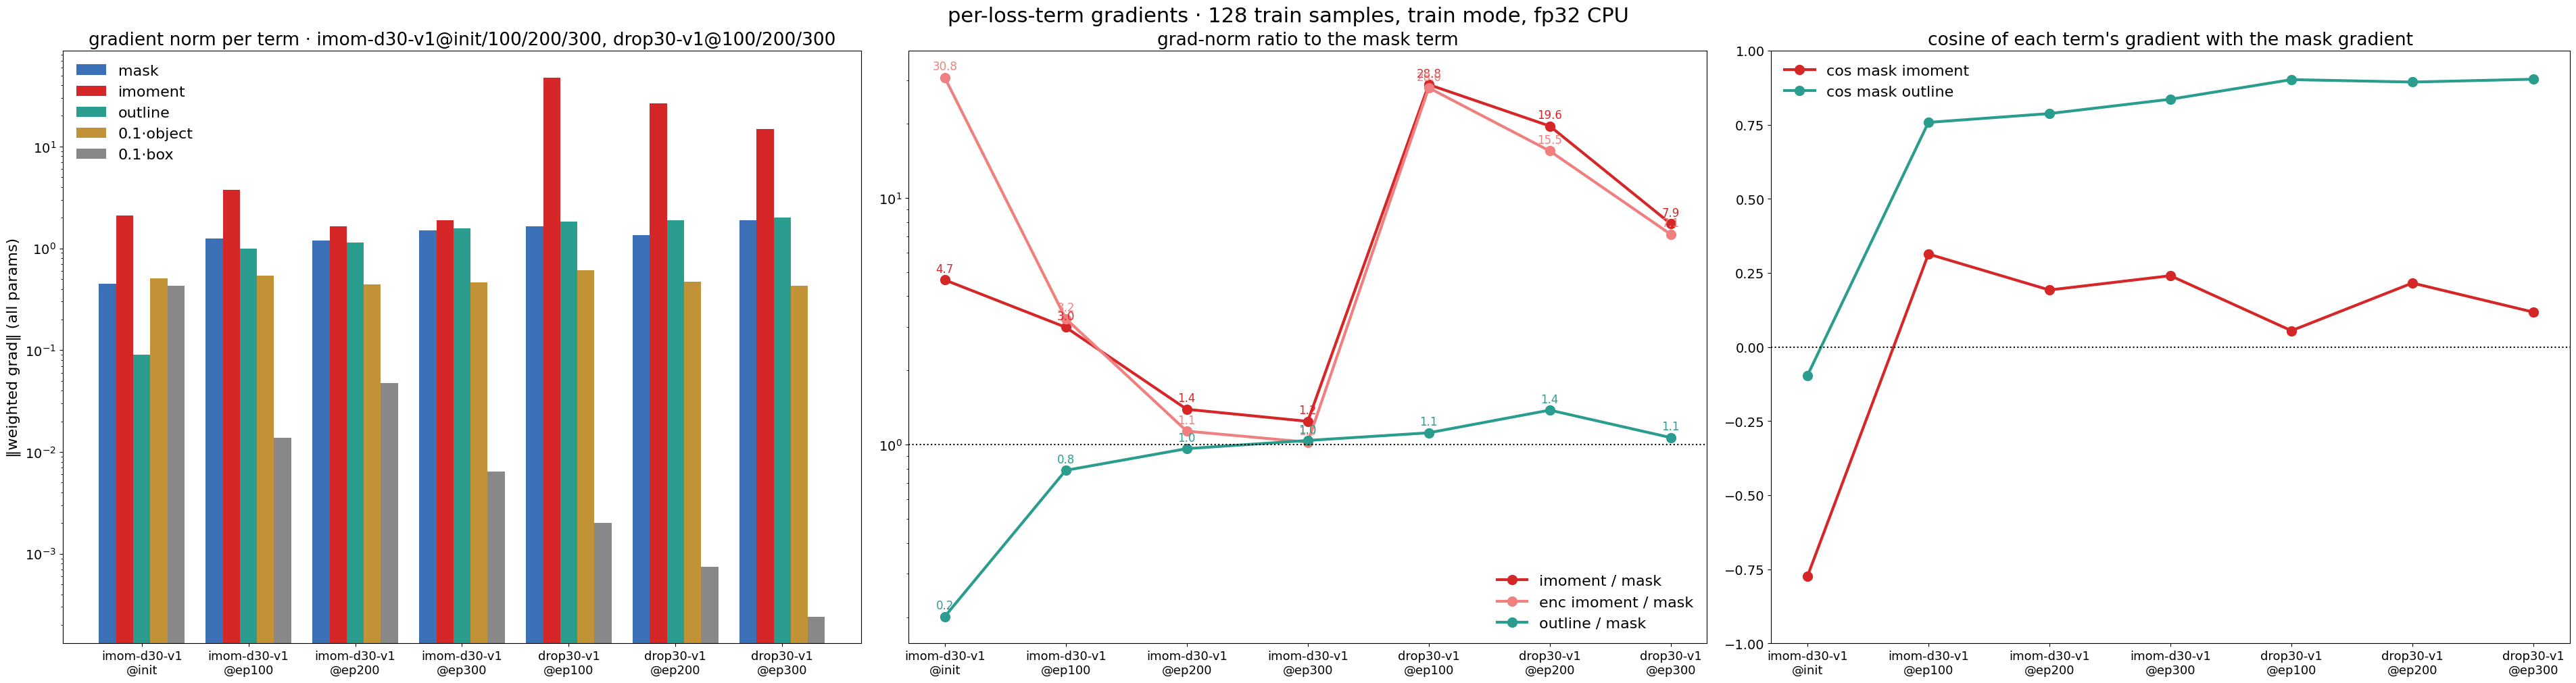

In [17]:
import json, subprocess
GJ = Path(SCRATCH) / "nb130/grads.json"
GRAD_CODE = r'''
import os, sys, json
os.environ["CUDA_VISIBLE_DEVICES"] = ""
from pathlib import Path
ROOT = Path("/home/ethantu/workspace/good-vibrations"); sys.path.insert(0, str(ROOT / "src9")); os.chdir(ROOT)
import torch; torch.set_num_threads(8)
from torch.utils.data import Subset, DataLoader
from dataset import build_dataset
from arch.transformer3 import Transformer3
out_f, B, NMB = sys.argv[1], int(sys.argv[2]), int(sys.argv[3])
_, _, train_eval, info = build_dataset("tukey", batch_size=1024, eval_batch_size=108, num_workers=0)
ds = train_eval.dataloader.dataloader.dataset
idx = torch.randperm(len(ds), generator=torch.Generator().manual_seed(0))[: B * NMB].tolist()
batches = list(DataLoader(Subset(ds, idx), batch_size=B))
args = json.loads((ROOT / "runs/imom-d30-v1/args.json").read_text())
T3 = ("height", "width", "bins_per_band", "d", "heads", "freq_layers", "laser_layers", "latent_dim", "laser_drop", "band_drop", "dice_w", "objrecall_w", "boundary_w", "mask_loss", "maskae", "readout", "heatmap_w", "laser_jitter_p", "speaker_gain_p", "gan_w", "norm", "log_mag", "abspos", "n_queries", "query_layers", "freeze_readout", "drop_rescale", "band_overlap", "tokenizer", "imom_w", "outline_w")
kw = {k: args[k] for k in ("speaker_gain", "speaker_gain_hz", "laser_jitter") + T3} | dict(imom_w=1.0, outline_w=1.0)  # every term computed for every model
CKPTS = [("imom-d30-v1", "init", None)] + [("imom-d30-v1", f"ep{e}", ROOT / f"runs/imom-d30-v1/checkpoints/ep{e}-ba{e * 10}-rank0.pt") for e in (100, 200, 300)] \
        + [("drop30-v1", f"ep{e}", ROOT / f"runs/drop30-v1/checkpoints/ep{e}-ba{e * 10}-rank0.pt") for e in (100, 200, 300)]
TERMS = {"mask": 1.0, "imoment": 1.0, "outline": 1.0, "object": 0.1, "box": 0.1}
res = []
for run, tag, ck in CKPTS:
    torch.manual_seed(42); model = Transformer3(info, **kw)
    if ck is not None: model.load_state_dict(torch.load(ck, map_location="cpu", weights_only=False)["state"]["model"])
    model.train()
    named = [(n, p) for n, p in model.named_parameters() if p.requires_grad]; ps = [p for _, p in named]
    dec = {i for i, (n, _) in enumerate(named) if n.startswith("decoder.")}
    G = {t: [torch.zeros_like(p) for p in ps] for t in TERMS}; L = {t: 0.0 for t in TERMS}
    torch.manual_seed(1)
    for b in batches:
        out = model(b); losses = model.loss(out, b)
        for j, t in enumerate(TERMS):
            gs = torch.autograd.grad(TERMS[t] * losses[t], ps, retain_graph=j < len(TERMS) - 1, allow_unused=True)
            for acc, gg in zip(G[t], gs):
                if gg is not None: acc += gg / len(batches)
            L[t] += losses[t].item() / len(batches)
    fl = lambda t, keep: torch.cat([g.flatten() for i, g in enumerate(G[t]) if keep(i)])
    flat = {t: fl(t, lambda i: True) for t in TERMS}; enc = {t: fl(t, lambda i: i not in dec) for t in TERMS}; de = {t: fl(t, lambda i: i in dec) for t in TERMS}
    cos = lambda a, b: float((a @ b) / (a.norm() * b.norm() + 1e-30))
    res.append(dict(run=run, ckpt=tag, **{f"loss_{t}": L[t] for t in TERMS}, **{f"gnorm_{t}": float(flat[t].norm()) for t in TERMS},
                    **{f"gnorm_enc_{t}": float(enc[t].norm()) for t in TERMS}, **{f"gnorm_dec_{t}": float(de[t].norm()) for t in TERMS},
                    **{f"cos_mask_{t}": cos(flat["mask"], flat[t]) for t in TERMS if t != "mask"}, **{f"cos_enc_mask_{t}": cos(enc["mask"], enc[t]) for t in TERMS if t != "mask"}))
    json.dump(res, open(out_f, "w"), indent=1)
'''
if not GJ.exists():   # ~15 min CPU, ~5.3 GB RSS
    GJ.parent.mkdir(parents=True, exist_ok=True); (GJ.parent / "gradcheck_inline.py").write_text(GRAD_CODE)
    subprocess.run([sys.executable, str(GJ.parent / "gradcheck_inline.py"), str(GJ), "4", "32"], check=True, env=dict(os.environ, CUDA_VISIBLE_DEVICES=""))
GR = pd.DataFrame(json.load(open(GJ))); GR["who"] = GR.run + "@" + GR.ckpt
TERMS_ = ["mask", "imoment", "outline", "object", "box"]
GR["imoment / mask"] = GR.gnorm_imoment / GR.gnorm_mask; GR["outline / mask"] = GR.gnorm_outline / GR.gnorm_mask
GR["enc imoment / mask"] = GR.gnorm_enc_imoment / GR.gnorm_enc_mask
display(GR.set_index("who")[[f"loss_{t}" for t in TERMS_] + [f"gnorm_{t}" for t in TERMS_] + ["imoment / mask", "outline / mask", "enc imoment / mask"]
                           + [c for c in GR if c.startswith("cos_")]].round(3).T)

fig, axes = plt.subplots(1, 3, figsize=(38, 10), constrained_layout=True)
x = np.arange(len(GR))
for j, t in enumerate(TERMS_):
    axes[0].bar(x + (j - 2) * 0.16, GR[f"gnorm_{t}"], 0.16, label=f"{'0.1·' if t in ('object', 'box') else ''}{t}", color=["#3B6FB6", "#D62728", "#2A9D8F", "#C29237", "#888"][j])
axes[0].set_yscale("log"); axes[0].set_xticks(x, GR.who.str.replace("@", "\n@"), fontsize=13); axes[0].set_ylabel("‖weighted grad‖ (all params)"); axes[0].legend(frameon=False)
axes[0].set_title("gradient norm per term · imom-d30-v1@init/100/200/300, drop30-v1@100/200/300")
for c, col in (("imoment / mask", "#D62728"), ("enc imoment / mask", "#F08080"), ("outline / mask", "#2A9D8F")):
    axes[1].plot(x, GR[c], "o-", lw=3, ms=10, color=col, label=c)
    for xi, v in zip(x, GR[c]): axes[1].annotate(f"{v:.1f}", (xi, v), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=12, color=col)
axes[1].axhline(1, color="k", ls=":"); axes[1].set_yscale("log"); axes[1].set_xticks(x, GR.who.str.replace("@", "\n@"), fontsize=13); axes[1].legend(frameon=False)
axes[1].set_title("grad-norm ratio to the mask term")
for c, col in (("cos_mask_imoment", "#D62728"), ("cos_enc_mask_imoment", "#F08080"), ("cos_mask_outline", "#2A9D8F")):
    if c in GR: axes[2].plot(x, GR[c], "o-", lw=3, ms=10, color=col, label=c.replace("cos_", "cos ").replace("_", " "))
axes[2].axhline(0, color="k", ls=":"); axes[2].set_ylim(-1, 1); axes[2].set_xticks(x, GR.who.str.replace("@", "\n@"), fontsize=13); axes[2].legend(frameon=False)
axes[2].set_title("cosine of each term's gradient with the mask gradient")
fig.suptitle("per-loss-term gradients · 128 train samples, train mode, fp32 CPU", fontsize=22)
plt.show()

## Verdict
imom-w 1.0 + outline-w 1.0 is a net loss everywhere except the miss rate. The imoment term dominates the first ~25 epochs with a gradient that opposes the mask gradient, and the run never recovers: train mask loss is 2× drop30's, masks are soft and over-painted, and location is worse, which is the very thing the moment term was meant to fix. Outline adds no crispness (biou −.10). The one useful effect is fewer missed objects OOD (missing −10 pp, under-painting 30 → 11 %). That can probably be had from a small, late moment term. Next runs (drop30 config: `--laser-drop 0.3 --band-drop 0.3`):
1. `--imom-w 0.1 --outline-w 0` (the moment term at 1/10: at init 1.6 vs mask 0.83, grad ≈ 0.5× mask). This tests whether the miss-rate benefit survives without the underfit.
2. `--imom-w 0.03 --outline-w 0`, a cheaper bracket.
3. Better still, ramp the term in after warmup (like boundary_w's `min(1, epoch / 50)` in transformer3.loss). This needs a one-line code change (not made here; src9 untouched).
Drop outline-only (`--outline-w 1.0` alone) as low priority: its gradient is ~parallel to the mask's, and drop30 already gets the lower outline loss.